# Taller 2: predicción de abandono de clientes para FinAlpes

Hecho por: María Paula Ospina 202123208

Este notebook  lee el archivo ../data/churn.csv. El caso es el de FinAlpes, unafintech colombiana que quiere ofrecr a los bancos un modelo para predecir qué clientes se van a ir, de forma que el banco pueda contactarlos con una oferta de retención.

Cómo está organizado frente a lo que pide el taller:

1. Entendimiento y preparación de los datos: scción 1.
2. Entrenamiento de los modelos: sección 2.
3. Análisis cuantitativo de los resultados: sección 3.
4. Análisis cualitativo con interpretabilidad: sección 4.
5. Generación de valor: sección 5.
6. Insights y recomendación final: archivo informe/Informe_ejecutivo.md.
7. Declaración de uso de IA generativa: archivo DECLARACION_IA.md y README.


In [1]:
import numpy as np

import pandas as pd
import matplotlib.pyplot as plt

import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns",  None)

pd.set_option("display.max_rows", 100)

## 1. Entendimiento y preparación de los datos

Ayudas usadas: cargar un dataset, explorar la estructura, histograma, grafico de cajas, gráfico de barras, dimensiones de calidad, duplicados, valores inválidos, inconsistencias, valores atípicos, nulos y relación de una variable con la clase.

Diccionario de datos del archivo churn.csv:

credit_score: puntaje crediticio del cliente. Se espera entre 300 y 850.

country: país de residencia. Puede ser France, Germany o Spain.

gender: género del cliente. Puede ser Female o Male.

age: edad en años. Se espera entre 18 y 100.

tenure: años que lleva el cliente en el banco. Se espera entre 0 y 10.

balance: saldo de la cuenta. Se espera mayor o igual a 0.

products_number: número de productos que tiene el cliente. Se espera entre 1 y 4.

credit_card: 1 si tiene tarjeta de crédito y 0 si no.

active_member: 1 si es un cliente activo y 0 si no.

estimated_salary: salario estimado del cliente. Se espera mayor o igual a 0.

churn: 1 si el cliente abandonó el banco y 0 si se quedó. Es la variable que se quiere predecir.

### 1.1 Carga y estructura del dataset

In [2]:
#cargar el archivo como dataframe
df=pd.read_csv("../data/churn.csv")
df.head()

,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,418.0,France,Female,46.0,9,0.00,1,1,1,81014.50,1
1,689.0,Germany,Male,67.0,9,157094.78,1,1,1,99490.01,0
2,477.0,Spain,Female,48.0,2,129120.64,1,0,1,26475.79,0
3,573.0,Germany,Female,35.0,9,206868.78,2,0,1,102986.15,0
4,849.0,France,Male,69.0,7,71996.09,1,1,1,139065.94,0


In [3]:
# dimensiones, tipos de dato y no nulos
print(df.shape)
print(df.dtypes)
df.info()

(10045, 11)
credit_score        float64
country                 str
gender                  str
age                 float64
tenure                int64
balance             float64
products_number       int64
credit_card           int64
active_member         int64
estimated_salary    float64
churn                 int64
dtype: object
<class 'pandas.DataFrame'>
RangeIndex: 10045 entries, 0 to 10044
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   credit_score      9795 non-null   float64
 1   country           10045 non-null  str    
 2   gender            10045 non-null  str    
 3   age               9745 non-null   float64
 4   tenure            10045 non-null  int64  
 5   balance           9845 non-null   float64
 6   products_number   10045 non-null  int64  
 7   credit_card       10045 non-null  int64  
 8   active_member     10045 non-null  int64  
 9   estimated_salary  9695 non-null   float64
 10 

In [4]:
# estadíticas descriptivas de las numericas
df.describe()

,credit_score,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
count,9795.000000,9745.000000,10045.000000,9845.000000,10045.000000,10045.000000,10045.000000,9695.000000,10045.000000
mean,650.690148,38.937609,5.018915,76317.500287,1.530114,0.704530,0.514684,100069.014751,0.203584
std,97.087963,10.734222,2.901585,62422.434819,0.581829,0.456277,0.499809,57510.689111,0.402683
min,95.000000,-1.000000,-2.000000,0.000000,1.000000,0.000000,0.000000,-5000.000000,0.000000
25%,584.000000,32.000000,3.000000,0.000000,1.000000,0.000000,0.000000,51013.655000,0.000000
50%,652.000000,37.000000,5.000000,97042.600000,1.000000,1.000000,1.000000,100130.950000,0.000000
75%,718.000000,44.000000,8.000000,127559.970000,2.000000,1.000000,1.000000,149382.875000,0.000000
max,1200.000000,210.000000,25.000000,250898.090000,4.000000,1.000000,1.000000,199992.480000,1.000000


In [5]:
#estadísticas de las variables de texto
df.describe(include="object")

/tmp/ipykernel_9193/2290357159.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,country,gender
count,10045,10045
unique,9,4
top,France,Male
freq,5003,5464


In [6]:
#valores únicos de las categoricas y las binarias
for columna in ["country", "gender","products_number", "credit_card", "active_member", "churn"]:
    print(columna, df[columna].unique())

numericas = df.select_dtypes(include="number").columns.tolist()
categoricas= df.select_dtypes(include="object").columns.tolist()
print(numericas)
print(categoricas)

#tipos de vriable según el diccionario
continuas= ["credit_score","age","balance", "estimated_salary"]
discretas = ["tenure","products_number"]
binarias = ["credit_card", "active_member"]

country <StringArray>
[  'France',  'Germany',    'Spain',  'GERMANY',   'FRANCE',    'SPAIN',
   'spain ',  'france ', 'germany ']
Length: 9, dtype: str
gender <StringArray>
['Female', 'Male', 'F', 'M']
Length: 4, dtype: str
products_number [1 2 3 4]
credit_card [1 0]
active_member [1 0]
churn [1 0]
['credit_score', 'age', 'tenure', 'balance', 'products_number', 'credit_card', 'active_member', 'estimated_salary', 'churn']
['country', 'gender']


/tmp/ipykernel_9193/3608082697.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categoricas = df.select_dtypes(include="object").columns.tolist()


El archivo tiene 10.045 registros y 11 atributos. Hay 4 variables continuas, que son credit_score, age, balance y estimated_salary. tenure y products_number son discretas, credit_card y active_member son binarias, country y gender son categóricas de texto y churn es la variable objetivo.

El describe ya muestra probleas. La edad va de menos 1 a 210 años, el tenure de menos 2 a 25 años, el credit_score de 95 a 1200 y el estimated_salary tiene un mínimo de menos 5.000. Ninguno de esos valores cabe en el diccionario de datos. Además, country tiene 9 valores únicos cuando debería tener 3 y gender tiene 4 cuando debería tener 2. Por lo tanto, hay categorías escritas de varias formas.

Asimismo, hay nulos en cuatro columnas: credit_score tiene 250, age tiene 300, balance tiene 200 y estimated_salary tiene 350. En churn el promedio es 0,2036, es decir que cerca del 20,4% de los clientes de la muestra abandonó el banco.

### 1.2 Distribución de las variables continuas

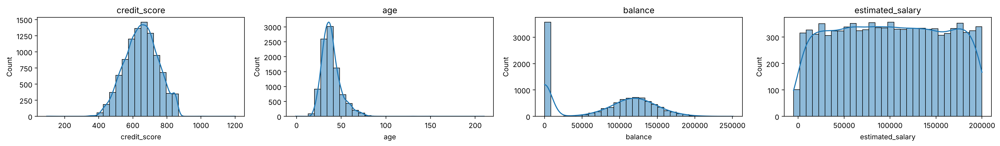

In [7]:
# histogramas
columnas = continuas

fig, axes= plt.subplots(1, len(columnas), figsize=(5 * len(columnas), 3))
for ax, columna in zip(axes, columnas):
    sns.histplot(df[columna], bins=30,kde=True,ax=ax)
    ax.set_title(columna)
plt.tight_layout()
plt.show()

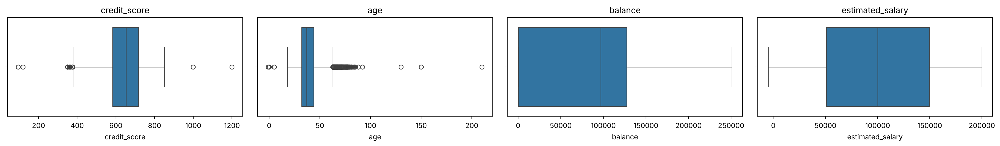

In [8]:
# gráicos de cajas
fig, axes = plt.subplots(1,  len(columnas), figsize=(5 * len(columnas), 3))
for ax, columna in zip(axes,columnas):
    sns.boxplot(x=df[columna], ax=ax)
    ax.set_title(columna)
plt.tight_layout()
plt.show()

### 1.3 Variables categóricas, binarias y discretas

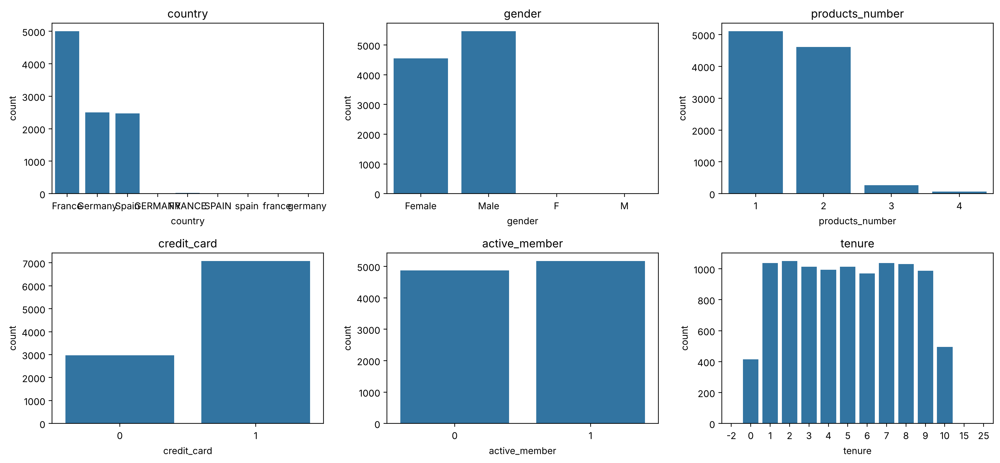

country
France      0.498059
Germany     0.249079
Spain       0.246391
FRANCE      0.002190
france      0.001692
GERMANY     0.000896
SPAIN       0.000896
germany     0.000597
spain       0.000199
Name: proportion, dtype: float64
gender
Male      0.543952
Female    0.453061
M         0.001593
F         0.001394
Name: proportion, dtype: float64
products_number
1    0.508512
2    0.458935
3    0.026481
4    0.006073
Name: proportion, dtype: float64


In [9]:
#graficos de barras
columnas= ["country", "gender", "products_number", "credit_card",  "active_member", "tenure"]
fig, axes = plt.subplots(2,3,figsize=(15, 7))

for ax, columna in zip( axes.ravel(), columnas):
    sns.countplot(x=columna, data=df,ax=ax)
    ax.set_title(columna)
plt.tight_layout()
plt.show()

for columna in ["country", "gender", "products_number"]:
    print(df[columna].value_counts(normalize=True))

### 1.4 Variable objetivo

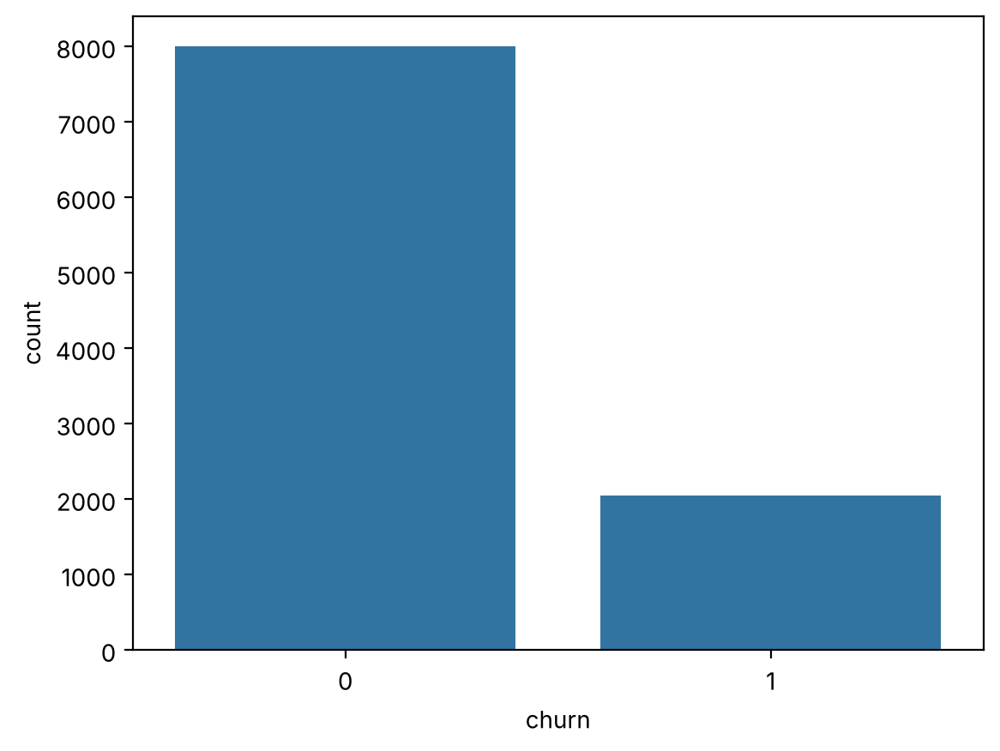

churn
0    8000
1    2045
Name: count, dtype: int64

In [10]:
#distribución de churn
sns.countplot(x="churn", data=df)
plt.show()

df["churn" ].value_counts()

In [11]:
df["churn"].value_counts(normalize=True)

churn
0    0.796416
1    0.203584
Name: proportion, dtype: float64

Los histogramas muestran formas distintas en cada variable. credit_score se parece a una campana centrada cerca de 650, con unos pocos valores sueltos hacia 1200 que no son válidos. age tiene una cola larga hacia la derecha, con la mayoría de clentes entre 30 y 45 años y valores sueltos que llegan hasta 210. balance es la más rara: hay una barra muy alta en 0 y el resto de los clientes forma otra campana alrededor de 120.000. estimated_salary es casi plana entre 0 y 200.000. Por lo tanto, el salario estimado no tiene una forma que se parezca a un salario real.

En las variables categóricas, Francia tiene cerca de la mitad de los clientes, con 49,8%, y Alemania y España tienen cerca de una cuarta parte cada una, con 24,9% y 24,6%. Hay más hombres, con 54,4%, que mujeres, con 45,3%, y el resto son las abreviaturas M y F. El 50,9% de los clientes tiene un solo producto, el 45,9% tiene dos, el 2,6% tiene tres y el 0,6% tiene cuatro. Esto significa que casi todos los clientes tenen uno o dos productos y que los casos de tres o cuatro son muy pocos.

La variable objetivo está desbalanceada: 8.000 clientes se quedaron y 2.045 se fueron, es decir 79,6% contra 20,4%. Esto importa dado que un modelo que siempre diga que el cliente se queda ya acierta cerca del 80% de las veces. Por lo tanto, la exactitud sola no sirve para evaluar. Es por esto, que en las secciones siguientes se usa el F1, la precisión y el recall.

### 1.5 Dimensiones de calidad de los datos

Del vistazo inicial saliron problemas de unicidad, completitud, consistencia y validez. Vamos a revisar cada dimensión antes de tocar nada.

In [12]:
# unicidad, ver los registros duplicados
print("Registros duplicados:", df.duplicated().sum())

#completitud, nulos por columna
print(df.isna().sum())
print(df.isna().mean() * 100)

Registros duplicados: 45
credit_score        250
country               0
gender                0
age                 300
tenure                0
balance             200
products_number       0
credit_card           0
active_member         0
estimated_salary    350
churn                 0
dtype: int64
credit_score        2.488800
country             0.000000
gender              0.000000
age                 2.986560
tenure              0.000000
balance             1.991040
products_number     0.000000
credit_card         0.000000
active_member       0.000000
estimated_salary    3.484321
churn               0.000000
dtype: float64


In [13]:
# consistencia, ver si lascategorías están escritas de una sola forma
print( df["country"].value_counts() )
print(df["gender"].value_counts())
print(df.dtypes)

country
France      5003
Germany     2502
Spain       2475
FRANCE        22
france        17
GERMANY        9
SPAIN          9
germany        6
spain          2
Name: count, dtype: int64
gender
Male      5464
Female    4551
M           16
F           14
Name: count, dtype: int64
credit_score        float64
country                 str
gender                  str
age                 float64
tenure                int64
balance             float64
products_number       int64
credit_card           int64
active_member         int64
estimated_salary    float64
churn                 int64
dtype: object


In [14]:
# validez, valores que se salen de los rangos del diccionario
print(df.describe().loc[["min", "max"]].T)

rangos = {"credit_score": (300, 850), "age": (18, 100), "tenure": (0, 10), "products_number": (1,  4)}
for columna, (minimo, maximo) in rangos.items():
    print(columna,  "fuera de rango:", (df[columna].notna() & ~df[columna].between(minimo, maximo)).sum())
print("balance menor que 0:", (df["balance"] < 0 ).sum())
print("estimated_salary menor que 0:",(df["estimated_salary"]< 0).sum())
for columna in ["credit_card", "active_member","churn"]:
    print(columna,  "fuera de 0 y 1:", (~df[columna].isin([0, 1]) ).sum())

                     min        max
credit_score        95.0    1200.00
age                 -1.0     210.00
tenure              -2.0      25.00
balance              0.0  250898.09
products_number      1.0       4.00
credit_card          0.0       1.00
active_member        0.0       1.00
estimated_salary -5000.0  199992.48
churn                0.0       1.00
credit_score fuera de rango: 4
age fuera de rango: 6
tenure fuera de rango: 3
products_number fuera de rango: 0
balance menor que 0: 0
estimated_salary menor que 0: 3
credit_card fuera de 0 y 1: 0
active_member fuera de 0 y 1: 0
churn fuera de 0 y 1: 0


In [15]:
# casos que parecen raros pero pueden ser reales
print("Clientes con balance igual a 0:",(df["balance"] == 0).sum(),  round((df["balance"]== 0).mean() * 100, 1),  "por ciento")
print( "Clientes con tenure mayor que edad menos 18:", ( df["tenure"] > df["age"] - 18).sum())
print("Clientes con estimated_salary menor que 1000:", (df["estimated_salary"] < 1000).sum())

Clientes con balance igual a 0: 3574 35.6 por ciento
Clientes con tenure mayor que edad menos 18: 319
Clientes con estimated_salary menor que 1000: 61


Por dimensión de calidad se encontró lo siguiente.

Unicidad: hay 45 registros duplicados exactos.

Completitud: faltan 250 valores en credit_score, 300 en age, 200 en balance y 350 en estimated_salary. Eso es entre 2% y 3,5% de cada columna. Las demás columnas están completas.

Consistencia: country aparece con 9 escrituras distintas, por ejemplo France, FRANCE, france y france con un espacio al final. gender aparece como Male, Female, M y F.

Validez: hay 4 puntajes crediticios fuera del rango de 300 a 850, 6 edades fuera de 18 a 100, 3 valores de tenure fuera de 0 a 10 y 3 salarios negativos. No hay saldos negativos, ni números de productos fuera de 1 a 4, ni binarias con valores distintos de 0 y 1.

Asimismo, se revisaron tres casos que parecen raros. El balance igual a 0 aparece en cerca del 36% de los clientes, que es mucho pero es posible en un banco, porque hay cuentas sin saldo. Los clientes con tenure mayor que la edad menos 18 son posibles porque una cuenta se puede abrir antes de los 18 años. Y los salarios muy bajos, menores que 1.000, son pocos. Estos tres casos no se tratan como errores. Tratarlos como error sería asumir una regla de negocio que no está en el diccionario de datos. En cambio, una edad de 210 años o un puntaje de 1200 sí rompen el rango del diccionario, y esos sí se corrigen.

### 1.6 Tratamiento de duplicados, inconsistencias y valores inválidos

In [16]:
# qitar los duplicados
print("Registros antes:",len(df))
df = df.drop_duplicates().reset_index(drop=True)
print("Registros después:", len(df))

Registros antes: 10045
Registros después: 10000


In [17]:
# unificar cómo se escriben las caegorías
df["country" ] =df["country" ].str.strip().str.lower().replace( {"france": "France", "germany": "Germany", "spain": "Spain"})
df["gender"] = df["gender"].str.strip().str.lower().replace({"male": "Male", "m": "Male","female": "Female", "f": "Female"})

print(df["country"].value_counts())
print(df["gender"].value_counts())

# ojo que al unificar pueden aparecer duplicados que antes se veían distintos
print("Duplicados después de unificar:", df.duplicated().sum())
df =df.drop_duplicates().reset_index( drop=True)

print("Registros:",len(df))

country
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64
gender
Male      5457
Female    4543
Name: count, dtype: int64
Duplicados después de unificar: 0


Registros: 10000


In [18]:
# ver cuáles son los inválidos y cómo quedarían si se recortan al límite más cercano
limites ={"credit_score": (300,850), "age": (18, 100), "tenure": (0, 10), "estimated_salary": (0, np.inf)}
for columna, (minimo, maximo) in limites.items():
    fuera=df[columna].notna() & ((df[columna] < minimo) | (df[columna] > maximo))
    comparacion = pd.DataFrame({"valor original": df.loc[fuera,  columna],
                                "valor recortado": df.loc[fuera, columna].clip(minimo, maximo)})
    print(columna, "valores fuera de rango:", fuera.sum() )
    print( comparacion.T)

credit_score valores fuera de rango: 4
                   1794   1880   6405   9007
valor original   1200.0  120.0   95.0  999.0
valor recortado   850.0  300.0  300.0  850.0
age valores fuera de rango: 6
                  991   1775  1818   4027   4526  7203
valor original   130.0   5.0   0.0  210.0  150.0  -1.0
valor recortado  100.0  18.0  18.0  100.0  100.0  18.0
tenure valores fuera de rango: 3
                 4672  5757  6287
valor original     15    25    -2
valor recortado    10    10     0
estimated_salary valores fuera de rango: 3
                   1983   2347  4668
valor original  -5000.0 -120.5  -1.0
valor recortado     0.0    0.0   0.0


Los vlores fuera de rango son pocos y todos parecen errores de captura. Hay puntajes crediticios de 1200, 999, 120 y 95, edades de 210, 150, 130, 5, 0 y menos 1, valores de tenure de 15, 25 y menos 2, y salarios de menos 5.000, menos 120,5 y menos 1. En total son 16 vlores entre 10.000 registros.

La actividad propone recortarlos al límite más cercano, pero la tabla de arriba muestra por qué eso no sirve aquí. Una edad de 210 pasaría a 100 y una de 5 pasaría a 18, y no hay forma de saber cuál era la edad real del cliente. Un salario de menos 5.000 pasaría a 0, que tampoco es un dato creíble. Recortar dejaría un valor falso que prece real y que el modelo no podría distinguir de uno verdadero. Por eso en estos casos se marcan como nulos y se imputan más adelante con la mediana del conjunto de entrenamiento. Esta es la situación en la que la actividad dice que conviene más el nulo que el recorte.

In [19]:
#los inválidos sevuelen nulos
for columna,  (minimo, maximo) in rangos.items():
    invalidos = df[columna].notna() & ~df[columna].between(minimo, maximo )
    print(columna, "valores marcados como nulos:", invalidos.sum())
    df.loc[invalidos, columna]= np.nan
invalidos = df["estimated_salary"] < 0
print("estimated_salary valores marcados como nulos:", invalidos.sum() )
df.loc[invalidos, "estimated_salary"] = np.nan

df.describe().loc[ ["min",  "max"]].T

credit_score valores marcados como nulos: 4
age valores marcados como nulos: 6
tenure valores marcados como nulos: 3
products_number valores marcados como nulos: 0
estimated_salary valores marcados como nulos: 3


,min,max
credit_score,350.00,850.00
age,18.00,92.00
tenure,0.00,10.00
balance,0.00,250898.09
products_number,1.00,4.00
credit_card,0.00,1.00
active_member,0.00,1.00
estimated_salary,11.58,199992.48
churn,0.00,1.00


### 1.7 Tratamiento de valores atípicos

In [20]:
#regla del IQR
con_atipicos = []
for columna in continuas:
    q1, q3=df[columna].quantile([0.25, 0.75])
    iqr=q3 - q1
    inferior, superior=q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_atipicos =((df[columna] < inferior) | (df[columna] > superior)).sum()
    print( columna,"atípicos según la regla del IQR:", n_atipicos)
    if n_atipicos > 0:
        con_atipicos.append( columna)
print("Variables con atípicos:", con_atipicos)

credit_score atípicos según la regla del IQR: 12
age atípicos según la regla del IQR: 344
balance atípicos según la regla del IQR: 0
estimated_salary atípicos según la regla del IQR: 0
Variables con atípicos: ['credit_score', 'age']


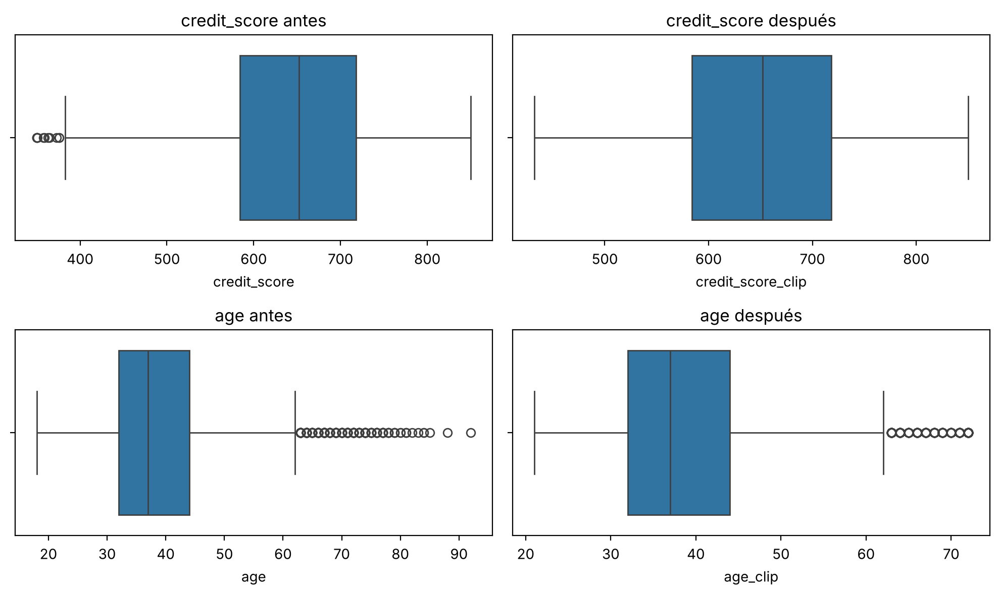

       credit_score  credit_score_clip
count   9746.000000         9746.00000
mean     650.624051          650.82126
std       96.615225           96.12207
min      350.000000          432.00000
25%      584.000000          584.00000
50%      652.000000          652.00000
75%      718.000000          718.00000
max      850.000000          850.00000
               age     age_clip
count  9694.000000  9694.000000
mean     38.917681    38.896740
std      10.471936    10.311409
min      18.000000    21.000000
25%      32.000000    32.000000
50%      37.000000    37.000000
75%      44.000000    44.000000
max      92.000000    72.000000


In [21]:
# clipping en los percentiles 1 y 99 en una columna nueva para poder comparar
for columna in con_atipicos:
    inferior, superior = df[columna].quantile([0.01, 0.99 ])
    df[columna + "_clip"]= df[columna].clip(lower=inferior,upper=superior)

fig, axes =plt.subplots(len( con_atipicos), 2, figsize=(10, 3 * len(con_atipicos)))

for fila,columna in zip(axes, con_atipicos):
    sns.boxplot(x=df[columna], ax=fila[ 0]).set_title(columna + " antes")
    sns.boxplot(x=df[columna + "_clip"], ax=fila[1]).set_title(columna + " después")
plt.tight_layout()
plt.show()

for columna in con_atipicos:
    print(df[[columna,  columna + "_clip"]].describe() )

In [22]:
#nos quedamos con la versión tratada
for columna in con_atipicos:
    df[columna]= df[columna+ "_clip"]
    df = df.drop(columns=columna+ "_clip")
df.describe()

,credit_score,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
count,9746.00000,9694.000000,9997.000000,9800.000000,10000.000000,10000.00000,10000.000000,9647.000000,10000.000000
mean,650.82126,38.896740,5.013804,76286.251909,1.530200,0.70550,0.515100,100069.671467,0.203700
std,96.12207,10.311409,2.892016,62413.450781,0.581654,0.45584,0.499797,57484.026111,0.402769
min,432.00000,21.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,584.00000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51106.180000,0.000000
50%,652.00000,37.000000,5.000000,97038.690000,1.000000,1.00000,1.000000,100137.700000,0.000000
75%,718.00000,44.000000,7.000000,127537.155000,2.000000,1.00000,1.000000,149376.125000,0.000000
max,850.00000,72.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


### 1.8 Nulos: revisión exploratoria con media y mediana

Esta imputacion es solo para explorar y se hace sobre una copia. La imputación que se usa para modelar viene en la sección 2, después de dividir los datos, con la mediana calculada solo con el conjunto de entrenamiento. Así no se filtra información de validación ni de prueba.

credit_score        2.54
age                 3.06
tenure              0.03
balance             2.00
estimated_salary    3.53
dtype: float64


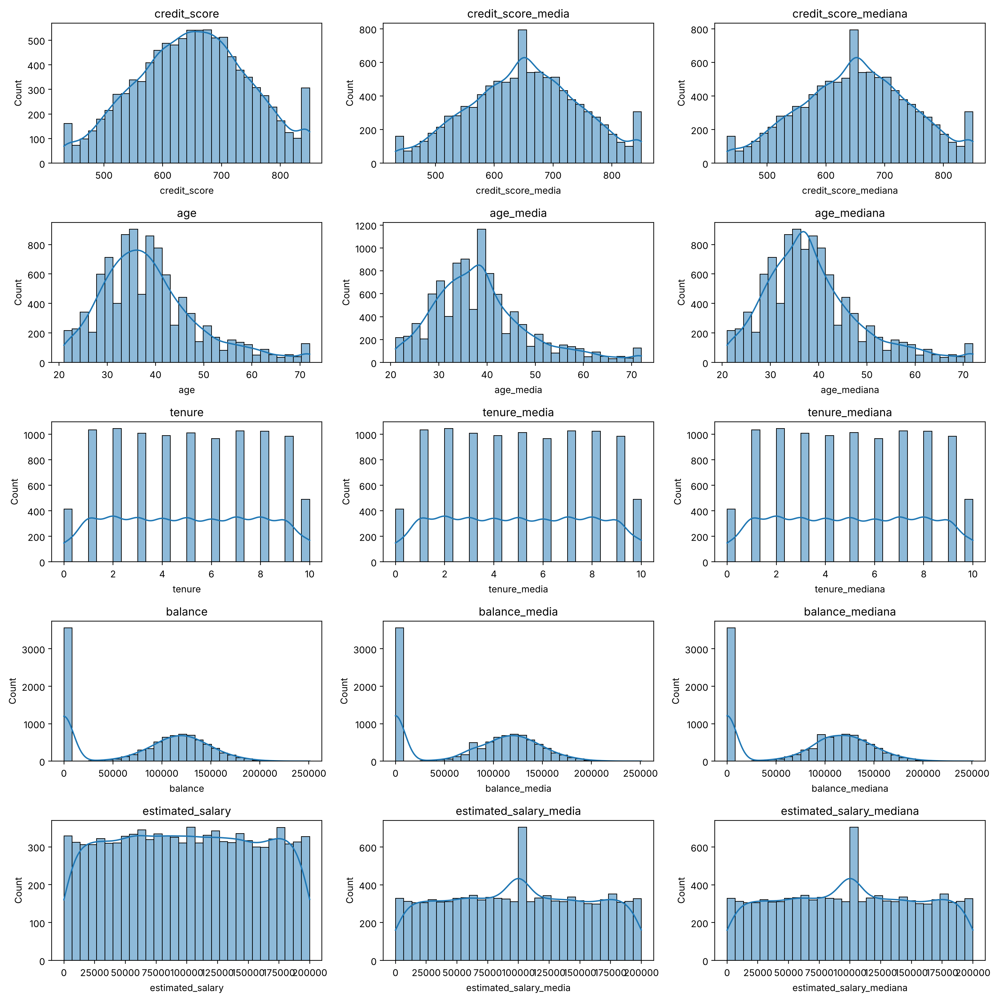

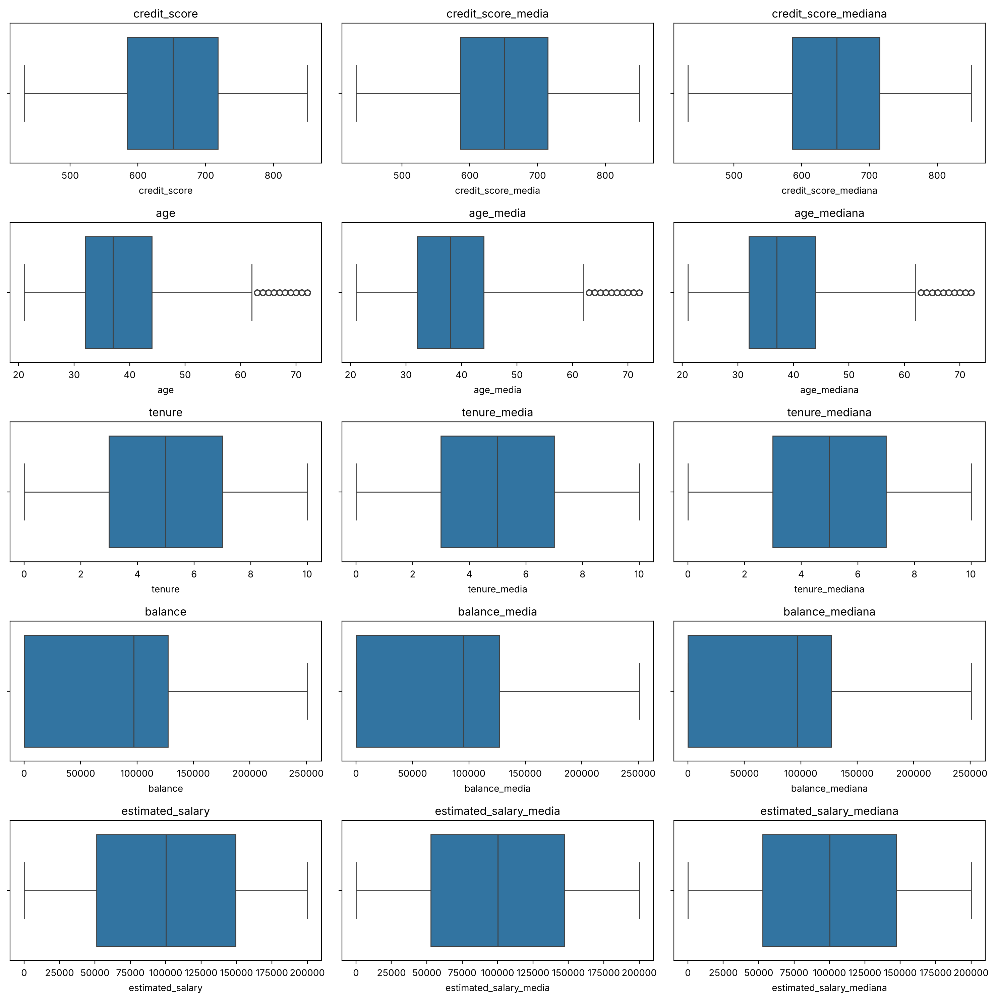

       credit_score  credit_score_media  credit_score_mediana
count    9746.00000        10000.000000          10000.000000
mean      650.82126          650.821260            650.851200
std        96.12207           94.893344             94.893525
min       432.00000          432.000000            432.000000
25%       584.00000          586.000000            586.000000
50%       652.00000          650.821260            652.000000
75%       718.00000          715.000000            715.000000
max       850.00000          850.000000            850.000000
               age     age_media   age_mediana
count  9694.000000  10000.000000  10000.000000
mean     38.896740     38.896740     38.838700
std      10.311409     10.152402     10.157657
min      21.000000     21.000000     21.000000
25%      32.000000     32.000000     32.000000
50%      37.000000     38.000000     37.000000
75%      44.000000     44.000000     44.000000
max      72.000000     72.000000     72.000000
            tenure 

In [23]:
columnas_nulos =df.columns[df.isna().any()].tolist()
print(df[columnas_nulos].isna().mean() * 100)

df_exploracion = df.copy()
for columna in columnas_nulos:
    df_exploracion[columna + "_media" ] = df_exploracion[columna ].fillna( df_exploracion[columna].mean())
    df_exploracion[columna + "_mediana"] = df_exploracion[columna].fillna(df_exploracion[columna ].median())

fig, axes = plt.subplots( len(columnas_nulos), 3, figsize=(15, 3 * len(columnas_nulos)))
for fila, columna in zip(axes, columnas_nulos):
    for ax, version in zip(fila, [columna,  columna + "_media",columna+ "_mediana"]):
        sns.histplot(df_exploracion[version],bins=30,kde=True, ax=ax)
        ax.set_title(version)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(len(columnas_nulos),  3, figsize=(15, 3 * len(columnas_nulos)))

for fila, columna in zip(axes, columnas_nulos):
    for ax, version in zip(fila, [columna, columna + "_media", columna + "_mediana"] ):
        sns.boxplot(x=df_exploracion[version], ax=ax)
        ax.set_title(version)
plt.tight_layout()
plt.show()

for columna in columnas_nulos:
    print(df_exploracion[[columna, columna + "_media", columna + "_mediana"]].describe())

Después de quitar los 45 duplicados quedaron 10.000 registros. Al unificar la escritura de las categorías no aparecieron duplicados nuevos y quedaron 3 países y 2 géneros: Francia con 5.014 clientes, Alemania con 2.509 y España con 2.477, y 5.457 hombres contra 4.543 mujeres.

Los 16 valores inválidos se marcaron como nulos: 4 en credit_score, 6 en age, 3 en tenure y 3 en estimated_salary. Con eso todos los rangos quedaron dentro del diccionario de datos.

En los valores atípicos, según la regla del IQR, balance y estimated_salary no tienen atípicos. credit_score tiene 12 y age tiene 344. Esos 344 de la edad son clientes mayores de unos 62 años y no son errores. Por lo tanto, no se eliminan. Se aplicó clipping en los percentiles 1 y 99, que deja la edad entre 21 y 72 años y el puntaje entre 432 y 850. Esto limita el peso de las puntas, pero también modifica alrededor del 1% de los clientes en cada extremo, que sí son valores posibles. La media y la desviación casi no cambian, así que el efecto es pequeño. Es una decisión de modelado y no una corrección de errores.

Para los nulos se comparó la media con la mediana en las cinco columnas que los tienen. Las dos opciones dejan casi igual la forma de las distribuciones, dado que faltan pocos datos, entre 2% y 3,5% de cada columna salvo tenure, que solo tiene 3. Se elige la mediana porque la edad y el balance son asimétricos, y en esos casos la mediana representa mejor a un cliente tpico que la media. Se calcula solo con el conjunto de entrenamiento en la sección 2.

### 1.9 Relación de cada variable con la clase

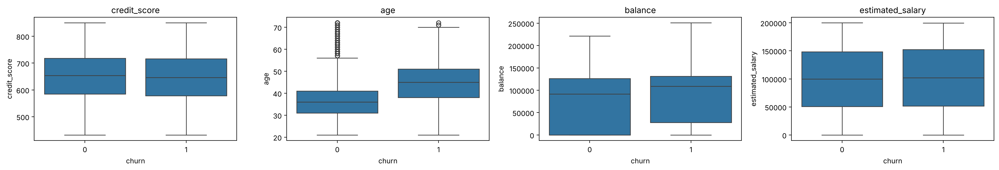

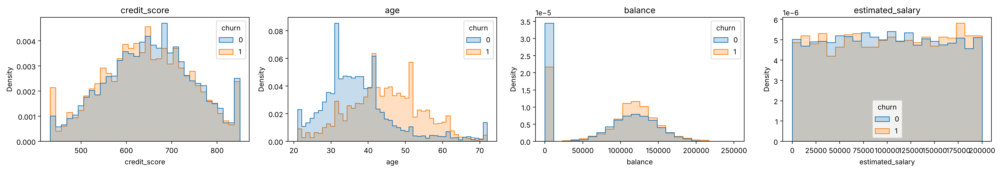

       credit_score        age       balance  estimated_salary
churn                                                         
0        652.056635  37.386172  72564.297095      99754.255399
1        645.966616  44.763224  90774.560290     101300.403166


In [24]:
# continuas según la clase
fig,  axes = plt.subplots(1,len(continuas), figsize=(5 * len(continuas), 3.5))
for ax, columna in zip(axes, continuas):
    sns.boxplot(x="churn", y=columna,  data=df, ax=ax)
    ax.set_title( columna)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, len(continuas ), figsize=(5 * len(continuas), 3.5))
for ax, columna in zip(axes,continuas):
    sns.histplot(data=df, x=columna,  hue="churn",  stat="density", common_norm=False, element="step", ax=ax )
    ax.set_title(columna)
plt.tight_layout()
plt.show()

print(df.groupby("churn")[continuas].mean())

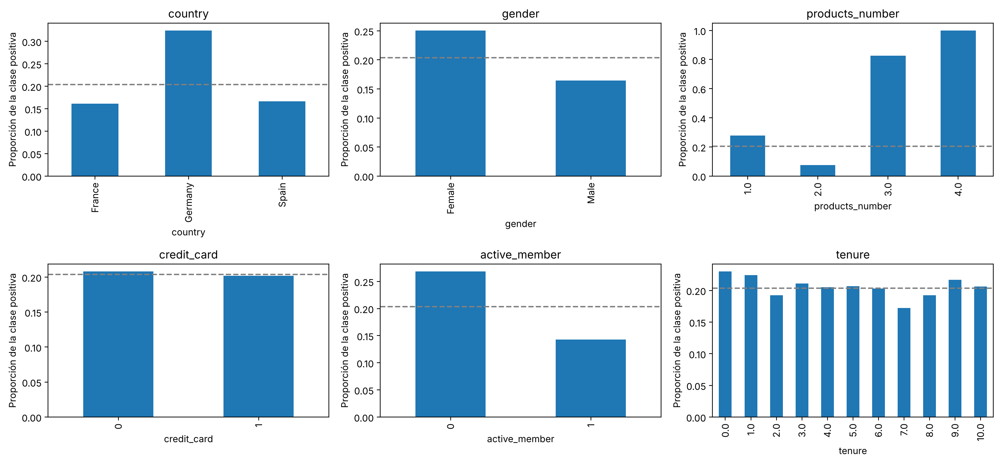

country
France     0.161548
Germany    0.324432
Spain      0.166734
Name: churn, dtype: float64
gender
Female    0.250715
Male      0.164559
Name: churn, dtype: float64
active_member
0    0.268509
1    0.142691
Name: churn, dtype: float64
credit_card
0    0.208149
1    0.201843
Name: churn, dtype: float64


In [25]:
#proporcion de la clase positiva por categria
columnas_cat= ["country", "gender", "products_number", "credit_card", "active_member", "tenure"]
fig, axes = plt.subplots(2, 3, figsize=(15,  7 ))
for ax, columna in zip(axes.ravel(), columnas_cat):
    proporcion = df.groupby(columna)["churn"].mean()
    proporcion.plot(kind="bar", ax=ax)
    ax.axhline( df["churn"].mean(), color="gray", linestyle="--")
    ax.set_ylabel("Proporción de la clase positiva")
    ax.set_title(columna)
plt.tight_layout()
plt.show()

for columna in [ "country","gender", "active_member", "credit_card"]:
    print(df.groupby(columna)["churn"].mean())

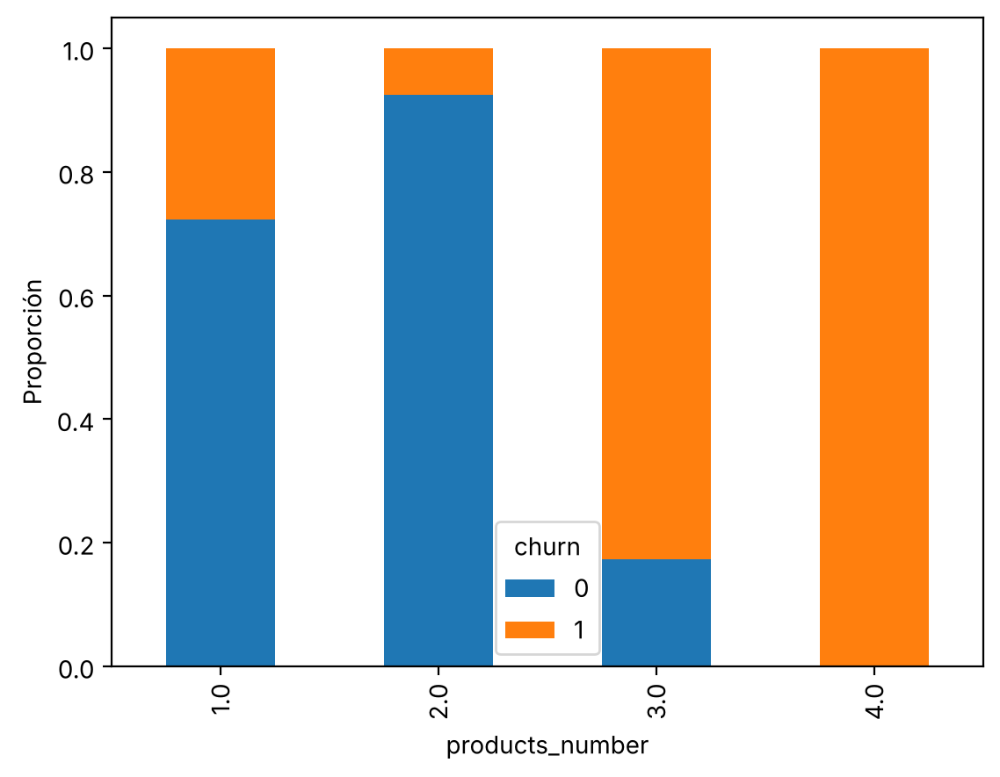

                 count      mean
products_number                 
1.0               5084  0.277144
2.0               4590  0.075817
3.0                266  0.827068
4.0                 60  1.000000


In [26]:
#numero de productos contra la clase
tabla = pd.crosstab(df["products_number"], df["churn"],  normalize="index")
tabla.plot(kind="bar", stacked=True)
plt.ylabel("Proporción")
plt.show()
print(df.groupby("products_number" )["churn"].agg(["count", "mean"]))

Los clientes que abandonan se ven distintos en algunas variables. Los que se fueron tienen una edad promedio de 44,8 años y los que se quedaron de 37,4. El saldo promedio también es más alto en los que se fueron, 90.775 contra 72.564. En credit_score y estimated_salary casi no hay diferencia, 646 contra 652 y 101.300 contra 99.754, y los histogramas por clase se montan uno sobre el otro.

En las variables categóricas hay diferencias más claras. En Alemania abandona el 32,4% de los clientes, mientras que en Francia es 16,2% y en España 16,7%. Entre las mujeres abandona el 25,1% y entre los hombres el 16,5%. Los clientes que no son activos abandonan en 26,9% y los activos en 14,3%. La tarjeta de crédito no marca diferencia, 20,8% contra 20,2%.

El caso más fuerte es el número de productos. Con un producto abandona el 27,7%, con dos productos baja a 7,6%, con tres sube a 82,7% y con cuatro se van los 60 clientes. Como los casos de tres y cuatro productos son pocos, 266 y 60 clientes, hay quemirarlos con cuidado, pero la forma no es una línea recta, y eso ya anticipa que un modelo de árboles puede capturar algo que la regresión logística no.

Estas son asociaciones entre cada variable y el abandono. No dicen que la edad, el país o el número de productos causen que el cliente se vaya.

### 1.10 Correlaciones y pruebas estadísticas frente al abandono

Ayudas usadas: prueba t de Welch, prueba U de Mann Whitney, prueba chi cuadrado y V de Cramér. Estas pruebas dicen si la diferencia entre quienes abandonan y quienes se quedan es mayor de lo que se esperaría por azar. No dicen que la variable cause el abandono. Cada prueba usa los registros que tienen valor en la variable que se prueba.

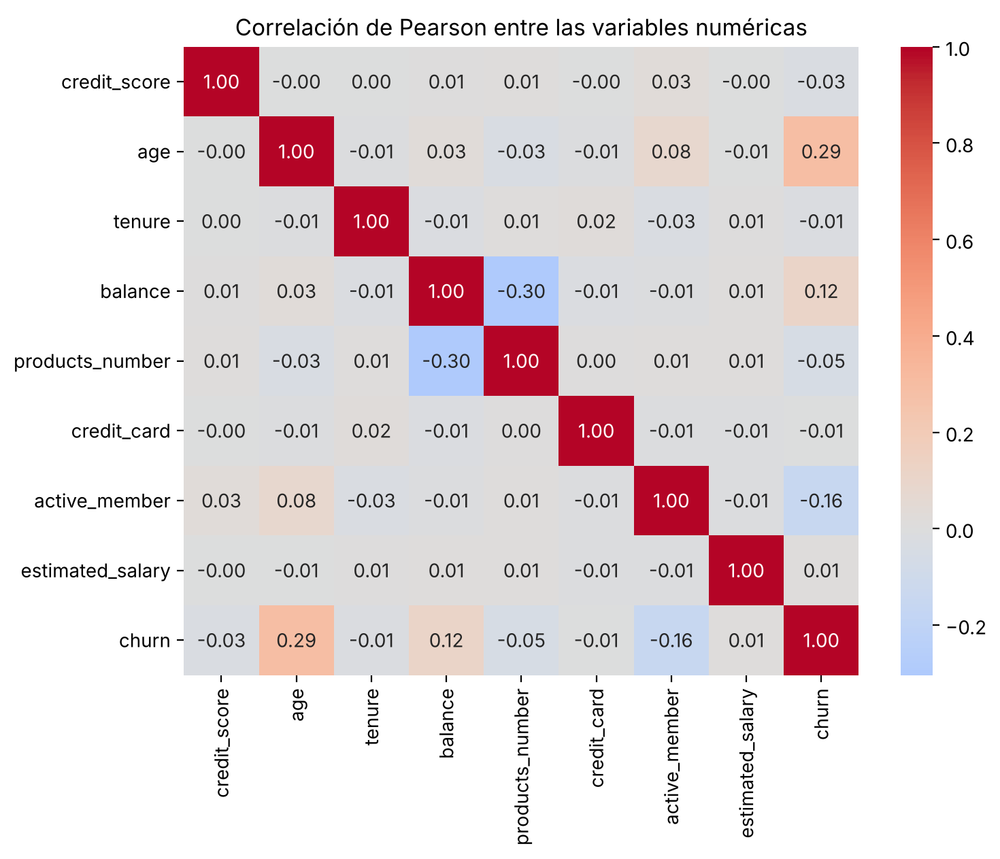

In [27]:
#correlacion de las numericas
plt.figure(figsize=(8, 6))

sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlación de Pearson entre las variables numéricas")
plt.show()

In [28]:
# continuas, t de Welch y U de Mann Whtney
filas = []
for columna in continuas:
    se_queda =df.loc[df["churn"]== 0, columna].dropna()
    abandona=df.loc[df["churn"] == 1, columna].dropna()
    t, p_t = stats.ttest_ind(abandona, se_queda,  equal_var=False )
    u,p_u=stats.mannwhitneyu(abandona, se_queda,alternative="two-sided")
    r_rangos =1 - 2 * u / (len(abandona) * len(se_queda))
    filas.append({"variable": columna,
                  "media abandona": abandona.mean(), "media se queda": se_queda.mean(),
                  "mediana abandona": abandona.median(),"mediana se queda": se_queda.median(),
                  "p valor t": p_t, "p valor U": p_u,  "r biserial de rangos": r_rangos})
pruebas_continuas =pd.DataFrame(filas).set_index("variable")
pruebas_continuas

,media abandona,media se queda,mediana abandona,mediana se queda,p valor t,p valor U,r biserial de rangos
variable,,,,,,,
credit_score,645.966616,652.056635,646.000,654.00,1.341032e-02,1.594054e-02,0.035055
age,44.763224,37.386172,45.000,36.00,9.103697e-174,5.441270e-219,-0.458771
balance,90774.560290,72564.297095,109153.960,91835.16,9.235238e-34,9.908658e-28,-0.154023
estimated_salary,101300.403166,99754.255399,102127.295,99654.13,2.907284e-01,2.884948e-01,-0.015484


In [29]:
# categóricas, binarias y discretas, chi cuadrado y V de Cramér
filas =[]
for columna in ["country", "gender",  "products_number",  "credit_card", "active_member",  "tenure"]:
    tabla = pd.crosstab(df[columna], df["churn"])
    chi2,p_valor,grados, esperados= stats.chi2_contingency(tabla)
    n = tabla.to_numpy().sum()
    v_cramer=np.sqrt(chi2 / (n * (min(tabla.shape ) - 1 )))
    filas.append({"variable": columna, "chi cuadrado": chi2, "grados de libertad": grados,
                  "p valor": p_valor, "V de Cramér": v_cramer, "frecuencia esperada mínima": esperados.min()})
pruebas_categoricas =pd.DataFrame( filas).set_index("variable").sort_values("V de Cramér", ascending=False)
pruebas_categoricas

,chi cuadrado,grados de libertad,p valor,V de Cramér,frecuencia esperada mínima
variable,,,,,
products_number,1503.629362,3,0.000000e+00,0.387767,12.222000
country,301.255337,2,3.830318e-66,0.173567,504.564900
active_member,242.985342,1,8.785858e-55,0.155880,987.741300
gender,112.918571,1,2.248210e-26,0.106263,925.409100
tenure,13.894101,10,1.778770e-01,0.037280,84.153346
credit_card,0.471338,1,4.923724e-01,0.006865,599.896500


La correlación entre las variables numéicas es baja en general. La más alta entre dos variables explicativas es entre products_number y balance, con 0,30. Con la clase, la más alta es la edad, con 0,29, seguida de active_member con menos 0,16 y balance con 0,12. Como churn es binaria, esa correlación solo da una idea gruesa.

En las variables continuas, la edad y el balance son las que más separan. La edad tiene una mediana de 45 años en quienes abandonan contra 36 en quienes se quedan, con un p valor de la prueba t que es prácticamente 0 y una correlación biserial de rangos de 0,46 en valor absoluto, que es un efecto moderado. El balance también es significativo, con medianas de 109.154 contra 91.835, pero el efecto es pequeño, 0,15. credit_score tiene un p valor de 0,013 en la prueba t y 0,016 en la prueba U, pero un efecto de 0,035, así que es significativo y a la vez casi irrelevante. Esto responde a la pregunta de la actividad: una diferencia significativa no siempre es grande, y con 10.000 registros casi cualquier diferencia pequeña sale significativa. estimated_salary no es significativa, con p valores de 0,29. Las dos pruebas, t y U, llegan a la misma conclusión en las cuatro variables, lo cual da confianza.

En las categóricas, todas las frecuencias esperadas mínimas son mayores que 5. Por lo tanto, la prueba chi cuadrado es válida. products_number tiene larelación más fuerte, con una V de Cramér de 0,39, seguida de country con 0,17, active_member con 0,16 y gender con 0,11. tenure, con p valor de 0,18, y credit_card, con p valor de 0,49, no muestran relación con el abandono.

Selección de variables. Tenure, credit_card y estimated_salary no muestran relación con el abandono en las pruebas, y credit_score la muestra muy pequeña. Aun así no se descartan. El conjunto original se define en la práctica como todas las variables originales, los modelos de la sección 2 las tratan con regularización o con árboles, y una variable que sola no separa puede aportar combinada con otras. Más adelante la importancia de cada variable en la regresión logística y en SHAP confirma que aportan muy poco.

Sobre products_number, la relación con el abandono no es una línea recta: abandona el 27,7% con un producto, el 7,6% con dos, el 82,7% con tres y todos con cuatro. Es por esto, que conviene más tratarla como categórica que como numérica en un modelo lineal, que solo puede ajustar una pendiente. Los árboles no tienen ese problema porque cortan la variable donde haga falta. En lugar de convertirla con one hot, el conjunto ampliado agrega los indicadores productos_1 y productos_3mas, que capturan la forma.

Estas son asociaciones y no dicen que una variable cause el abandono.

## 2. Entrenamiento de los modelos

Ayudas usadas: codificacion one hot, características derivadas, dividir en entrenamiento, validación y prueba, estandarizar variables, regresión logística, árbol de decisión, KNN, Random Forest, Gradient Boosting, votación, stacking, red neuronal, GridSearchCV y validación cruzada.

Se arman dos conjuntos de variables, el original y el ampliado con características derivadas. Con el conjunto original seentrenan ocho modelos de cinco familias: tres modelos básicos, cuatro ensambles y una red neuronal. Los hiperparámetros se buscan con GridSearchCV y validación cruzada estratificada de 5 folds sobre el conjunto de entrenamiento, y la métrica para elegirlos es el F1. Las rejillas son las de las actividades de la Práctica 2. El conjunto ampliado se usa después, en la seccion 3.

### 2.1 Codificación one hot

In [30]:
#pasar las categoricas a columnas numericas
df= pd.get_dummies(df, columns=["country", "gender"], drop_first=True, dtype=int )
variables_originales =[columna for columna in df.columns if columna!= "churn"]
df.head()

,credit_score,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn,country_Germany,country_Spain,gender_Male
0,432.0,46.0,9.0,0.00,1.0,1,1,81014.50,1,0,0,0
1,689.0,67.0,9.0,157094.78,1.0,1,1,99490.01,0,1,0,1
2,477.0,48.0,2.0,129120.64,1.0,0,1,26475.79,0,0,1,0
3,573.0,35.0,9.0,206868.78,2.0,0,1,102986.15,0,1,0,0
4,849.0,69.0,7.0,71996.09,1.0,1,1,139065.94,0,0,0,1


### 2.2 Características derivadas

In [31]:
#características que se calculan fila por fila con las varibles originales
def construir_derivadas(X):
    X = X.copy()
    X["balance_cero"] =(X["balance"] == 0).astype(float).where(X["balance"].notna())
    X["balance_salario"] = X["balance"] / (X["estimated_salary"] + 1)
    X[ "productos_1"] = (X["products_number"] == 1).astype(int)
    X["productos_3mas"] = (X["products_number"] >= 3).astype(int)
    X["edad_activo"] = X["age"] * X["active_member"]
    return X

derivadas = ["balance_cero","balance_salario", "productos_1", "productos_3mas", "edad_activo"]
variables_ampliadas= variables_originales + derivadas

#esto es solo para explorar cuales separan mejor a los que abandonan
df_derivadas = construir_derivadas( df[variables_originales] ).assign(churn=df["churn"])
for columna in ["balance_cero", "productos_1", "productos_3mas"]:
    print(df_derivadas.groupby(columna)["churn"].agg(["count", "mean"]))

              count      mean
balance_cero                 
0.0            6241  0.241468
1.0            3559  0.139365
             count      mean
productos_1                 
0             4916  0.127746
1             5084  0.277144
                count      mean
productos_3mas                 
0                9674  0.181621
1                 326  0.858896


In [32]:
# derivadas continuas, U de Mann Whitny contra la clase
filas = []
for columna in ["balance_salario", "edad_activo"]:
    se_queda = df_derivadas.loc[df_derivadas[ "churn"] == 0, columna].dropna()
    abandona= df_derivadas.loc[df_derivadas["churn"] == 1, columna].dropna()
    u, p_u= stats.mannwhitneyu(abandona, se_queda,  alternative="two-sided")
    filas.append({ "variable": columna, "mediana abandona": abandona.median(), "mediana se queda": se_queda.median(),
                  "p valor U": p_u,"r biserial de rangos": 1 - 2 * u / (len(abandona) * len(se_queda))})
pd.DataFrame(filas).set_index("variable")

,mediana abandona,mediana se queda,p valor U,r biserial de rangos
variable,,,,
balance_salario,0.884011,0.702169,4.871769e-24,-0.145305
edad_activo,0.000000,27.000000,2.466839e-19,0.122913


Entre las derivadas, las que mejor separan son las de productos. Con tres o más productos abandona el 85,9% de los clientes, contra 18,2% en el resto, aunque son solo 326 clientes. Con un solo producto abandona el 27,7% contra 12,8%. El saldo en cero separa al revés: abandona el 13,9% de quienes tienen saldo cero y el 24,1% de los demás.

De las dos derivadas continuas, balance_salario tiene una mediana de 0,88 en quienes abandonan contra 0,70 en quienes se quedan, con un efecto pequeño de 0,15. edad_activo tiene una mediana de 0 en quienes abandonan contra 27 en quienes se quedan, con un efecto de 0,12. Esa mediana de 0 aparece dado que casi todos los que abandonan son inactivos y la variable vale 0 cuando el cliente es inactivo. Por lo tanto, mucho de lo que edad_activo dice ya lo dice active_member.

Estas derivadas no agregan información nueva. Presentan de otra forma lo que ya estaba. Se comprueba si ayudan al modelo en la sección 3.

### 2.3 División en entrenamiento, validación y prueba

In [33]:
from sklearn.model_selection import train_test_split

#60 por ciento para entrenar, 20 para validación y 20 para prueba, estratificado por churn
X = df[variables_originales]
y = df["churn"]

X_temp, X_test, y_temp, y_test=train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25,random_state=42, stratify=y_temp
)

print(len(X_train), len(X_val ),len(X_test))
print(y_train.value_counts(normalize=True), y_val.value_counts(normalize=True), y_test.value_counts(normalize=True))

6000 2000 2000
churn
0    0.796167
1    0.203833
Name: proportion, dtype: float64 churn
0    0.7965
1    0.2035
Name: proportion, dtype: float64 churn
0    0.7965
1    0.2035
Name: proportion, dtype: float64


### 2.4 Imputación de nulos, derivadas y estandarización

La mediana se calcula solo con el conjunto de entrenamiento y se aplica a los tres conjuntos. Las características derivadas se calculan después de impuar, a partir de las variables originales ya completas, para que cada derivada sea consistente con las variables de las que sale. Hay un escalador por cada conjunto de variables, ajustado solo con entrenamiento.

In [34]:
medianas =X_train.median()
X_train = X_train.fillna(medianas)

X_val = X_val.fillna(medianas)
X_test= X_test.fillna( medianas)
print(X_train.isna().sum().sum(), X_val.isna().sum().sum(), X_test.isna().sum().sum())

X_train_amp_crudo =construir_derivadas(X_train)
X_val_amp_crudo = construir_derivadas(X_val)
X_test_amp_crudo = construir_derivadas(X_test)

0 0 0


In [35]:
from sklearn.preprocessing import StandardScaler

#conjunto original
escalador_original = StandardScaler()
X_train_esc =pd.DataFrame(escalador_original.fit_transform(X_train), columns=variables_originales, index=X_train.index)
X_val_esc =pd.DataFrame(escalador_original.transform(X_val), columns=variables_originales,  index=X_val.index)
X_test_esc= pd.DataFrame(escalador_original.transform(X_test), columns=variables_originales, index=X_test.index)

#conjuno ampliado
escalador_ampliado= StandardScaler()
X_train_amp = pd.DataFrame(escalador_ampliado.fit_transform(X_train_amp_crudo), columns=variables_ampliadas,  index=X_train.index)
X_val_amp = pd.DataFrame(escalador_ampliado.transform( X_val_amp_crudo), columns=variables_ampliadas,  index=X_val.index)

X_test_amp = pd.DataFrame(escalador_ampliado.transform(X_test_amp_crudo ), columns=variables_ampliadas,  index=X_test.index)

#todo queda organizado por conjunto de variables
X_esc = {"original": { "train": X_train_esc,"val": X_val_esc, "test": X_test_esc},
         "ampliado": {"train": X_train_amp, "val": X_val_amp, "test": X_test_amp}}
escaladores = {"original": escalador_original,"ampliado": escalador_ampliado}
columnas_conjunto = {"original": variables_originales,  "ampliado": variables_ampliadas}

### 2.5 Modelos básicos con el conjunto original

In [36]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, GridSearchCV

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# regresión logística
param_grid_lr = {"C": [0.01, 0.1, 1, 10], "class_weight": [None,"balanced" ]}
busqueda_lr = GridSearchCV(LogisticRegression(max_iter=1000), param_grid_lr, cv=skf, scoring="f1")
busqueda_lr.fit(X_train_esc, y_train)

print("Regresión logística. Mejor valor:",  busqueda_lr.best_params_)
print("F1 de validación cruzada:", busqueda_lr.best_score_)
modelo_lr = busqueda_lr.best_estimator_

Regresión logística. Mejor valor: {'C': 0.01, 'class_weight': 'balanced'}
F1 de validación cruzada: 0.48430773727088167


In [37]:
from sklearn.tree import DecisionTreeClassifier

#árbol dedecisón
param_grid_dt = {"max_depth": [3, 5, 7, 10, None],"min_samples_leaf": [1, 5, 20, 50],"class_weight": [None, "balanced"]}
busqueda_dt = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid_dt,cv=skf, scoring="f1")
busqueda_dt.fit(X_train_esc, y_train)

print("Árbol de decisión. Mejor valor:", busqueda_dt.best_params_)
print("F1 de validación cruzada:",  busqueda_dt.best_score_)
modelo_dt = busqueda_dt.best_estimator_

Árbol de decisión. Mejor valor: {'class_weight': None, 'max_depth': 7, 'min_samples_leaf': 20}
F1 de validación cruzada: 0.5854110704250177


In [38]:
from sklearn.neighbors import KNeighborsClassifier

#KNN
param_grid_knn = {"n_neighbors": [3,  5,  11,  21, 41], "weights": ["uniform", "distance"] }
busqueda_knn = GridSearchCV(KNeighborsClassifier(), param_grid_knn, cv=skf,  scoring="f1")
busqueda_knn.fit(X_train_esc, y_train )

print( "KNN. Mejor valor:", busqueda_knn.best_params_)
print("F1 de validación cruzada:", busqueda_knn.best_score_)
modelo_knn = busqueda_knn.best_estimator_

KNN. Mejor valor: {'n_neighbors': 3, 'weights': 'distance'}
F1 de validación cruzada: 0.4629360640794518


Se optimiza el F1 y no la exactitud porque las clases están desbalanceadas, con 20% de abandono. Un modelo que siempre diga que el cliente se queda acierta cerca del 80% y no detecta ningún abandono.

La regresión logística quedó con C de 0,01 y class_weight balanced, y un F1 de validación cruzada de 0,484. Una C tan baja significa una regularización fuerte, y el peso balanceado hace que le dé más importancia a la clase minoritaria. El árbol quedó con profundidad 7 y mínimo de 20 registros por hoja, con un F1 de 0,585. Un árbol con hojas pequeñas y profundo memoriza, y la búsqueda eligió un punto intermedio. KNN quedó con 3 vecinos y pesos por distancia, con un F1 de 0,463. KNN calcula distancias entre clientes, así que necesita las variables escaladas: sin escalar, el salario y el balance, que están en miles, dominarían sobre la edad o el tenure.

### 2.6 Ensambles con el conjunto original

In [39]:
from sklearn.ensemble import RandomForestClassifier

# Random Forest
param_grid_rf={
    "n_estimators": [ 200, 400],
    "max_depth": [5, 10, None],
    "min_samples_leaf": [1, 5,20],
    "class_weight": [None, "balanced"],
}
busqueda_rf = GridSearchCV(RandomForestClassifier(random_state=42,  n_jobs=-1), param_grid_rf,cv=skf, scoring="f1")
busqueda_rf.fit(X_train_esc, y_train)

print( "Random Forest. Mejor valor:", busqueda_rf.best_params_)
print("F1 de validación cruzada:", busqueda_rf.best_score_ )
modelo_rf= busqueda_rf.best_estimator_

Random Forest. Mejor valor: {'class_weight': 'balanced', 'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 400}
F1 de validación cruzada: 0.6274962752853028


In [40]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight

#Grdient Boosting no tiene class_weight así que los pesos balanceados se calculan dentro del fit
# asi GridSearchCV no se los pasa tambien a la métrca y el F1 de la validacion cruzada no sale inflado
class GradientBoostingBalanceado(GradientBoostingClassifier):
    def fit(self, X, y, sample_weight=None):
        return super().fit(X, y, sample_weight=compute_sample_weight("balanced",  y) )

param_grid_gb = {"n_estimators": [100, 300],  "learning_rate": [0.05, 0.1],  "max_depth": [2, 3, 4]}
busqueda_gb= GridSearchCV(GradientBoostingBalanceado(random_state=42), param_grid_gb, cv=skf,  scoring="f1")
busqueda_gb.fit(X_train_esc, y_train)

print("Gradient Boosting. Mejor valor:", busqueda_gb.best_params_)

print( "F1 de validación cruzada:", busqueda_gb.best_score_)
modelo_gb =busqueda_gb.best_estimator_

Gradient Boosting. Mejor valor: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 300}
F1 de validación cruzada: 0.6140896534285493


In [41]:
from sklearn.ensemble import VotingClassifier
from sklearn.metrics import f1_score

#votacion dura y suave con los tres básicos ya optimizados
modelos_base=[("logistica",  modelo_lr),("arbol", modelo_dt),  ("knn", modelo_knn)]

votacion_dura=VotingClassifier(estimators=modelos_base, voting="hard")
votacion_dura.fit( X_train_esc, y_train)
votacion_suave = VotingClassifier(estimators=modelos_base,voting="soft")

votacion_suave.fit(X_train_esc, y_train)

print("F1 de validación de la votación dura:", round(f1_score(y_val, votacion_dura.predict(X_val_esc )), 3))
print("F1 de validación de la votación suave:", round(f1_score(y_val, votacion_suave.predict(X_val_esc)), 3))

F1 de validación de la votación dura: 0.56
F1 de validación de la votación suave: 0.552


In [42]:
from sklearn.ensemble import StackingClassifier

#stacking con los mismos tres moelos base y unaregresion logística al final
apilamiento = StackingClassifier(estimators=modelos_base, final_estimator=LogisticRegression(max_iter=1000),
                                 cv=5, stack_method="predict_proba", n_jobs=-1)
param_grid_st = {"final_estimator__C": [0.1,1,  10], "final_estimator__class_weight": [None, "balanced"]}
busqueda_st = GridSearchCV( apilamiento, param_grid_st, cv=skf, scoring="f1")
busqueda_st.fit( X_train_esc, y_train )

print("Stacking. Mejor valor:", busqueda_st.best_params_)
print("F1 de validación cruzada:", busqueda_st.best_score_)
modelo_st = busqueda_st.best_estimator_

Stacking. Mejor valor: {'final_estimator__C': 10, 'final_estimator__class_weight': 'balanced'}
F1 de validación cruzada: 0.6048833574394441


El Random Forest quedó con 400 árboles, profundidad sin límite, mínimo de 5 registros por hoja y class_weight balanced, con un F1 de validación cruzada de 0,627. El Gradient Boosting quedó con 300 árboles, tasa de aprendizaje de 0,1 y profundidad 3, con un F1 de 0,614. Los pesos balanceados del Gradient Boosting se calculan dentro del fit porque, si se pasan desde GridSearchCV, esta versión de scikit learn también los usa al calcular el F1 y el valor de la validación cruzada sale inflado. La tasa de aprendizaje y el número de árboles actúan juntos. Una tasa menor necsita más árboles para llegar al mismo punto, y por eso no se miran por separado.

En la votación, la dura tuvo un F1 de validación de 0,560 y la suave de 0,552, una diferencia muy pequeña. Se conserva la suave porque es la que permite graficar las curvas ROC y de precisión y recall. Lo habital es que la suave funcione mejor dado que aprovecha la confianza de cada modelo, pero aquí esa ventaja no aparece, y entre las dos no hay una diferencia que permita elegir una con claridad. El stacking quedó con C de 10 y class_weight balanced en el modelo final, con un F1 de 0,605. Conviene que los modelos base sean distintos porque así cometen errores distintos, y el modelo final aprende en cuáles confiar. Si los tres fueran parecidos, el stacking no tendría nada que corregir.

### 2.7 Red neuronal con el conjunto original

In [43]:
import keras
from keras import layers

#red densa con dropout opcional, salida sigmoide y entroia cruzada binaria
def construir_red(neuronas, n_entradas, dropout=True):
    keras.utils.set_random_seed(42 )
    capas = [ keras.Input(shape=(n_entradas,))]
    for n in neuronas:
        capas.append(layers.Dense( n,activation="relu") )
        if dropout:
            capas.append(layers.Dropout( 0.2))
    capas.append(layers.Dense(1, activation="sigmoid"))
    red= keras.Sequential(capas)
    red.compile(optimizer="adam", loss="binary_crossentropy",
                metrics=[keras.metrics.AUC(name="auc"), keras.metrics.Recall(name="recall")])
    return red

#red de referencia con dos capas ocultas de 16 y 8 neuronas
construir_red([16, 8], X_train_esc.shape[1], dropout=False ).summary()

I0000 00:00:1794097427.119214    9193 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794097427.163481    9193 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1794097428.535061    9193 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 337 (1.32 KB)

 Trainable params: 337 (1.32 KB)

 Non-trainable params: 0 (0.00 B)

In [44]:
#tres arquitecturas con Dropout de 0,2 después de cada capa oculta
arquitecturas= {"una capa de 8": [8], "dos capas de 16 y 8": [16,8 ], "tres capas de 32, 16 y 8": [32, 16, 8]}
redes, historias = {}, {}
for nombre, neuronas in arquitecturas.items():
    red = construir_red(neuronas,  X_train_esc.shape[1])
    historias[nombre] = red.fit(X_train_esc, y_train.to_numpy(), validation_data=(X_val_esc, y_val.to_numpy()),
                                epochs=100,batch_size=32, verbose=0)
    redes[nombre] =red
    prob_val = red.predict(X_val_esc,verbose=0).ravel()
    print(nombre, ". F1 de validación:", round(f1_score(y_val, (prob_val>= 0.5).astype(int)), 3))

una capa de 8 . F1 de validación: 0.515


dos capas de 16 y 8 . F1 de validación: 0.543


tres capas de 32, 16 y 8 . F1 de validación: 0.548


Mejor arquitectura: tres capas de 32, 16 y 8


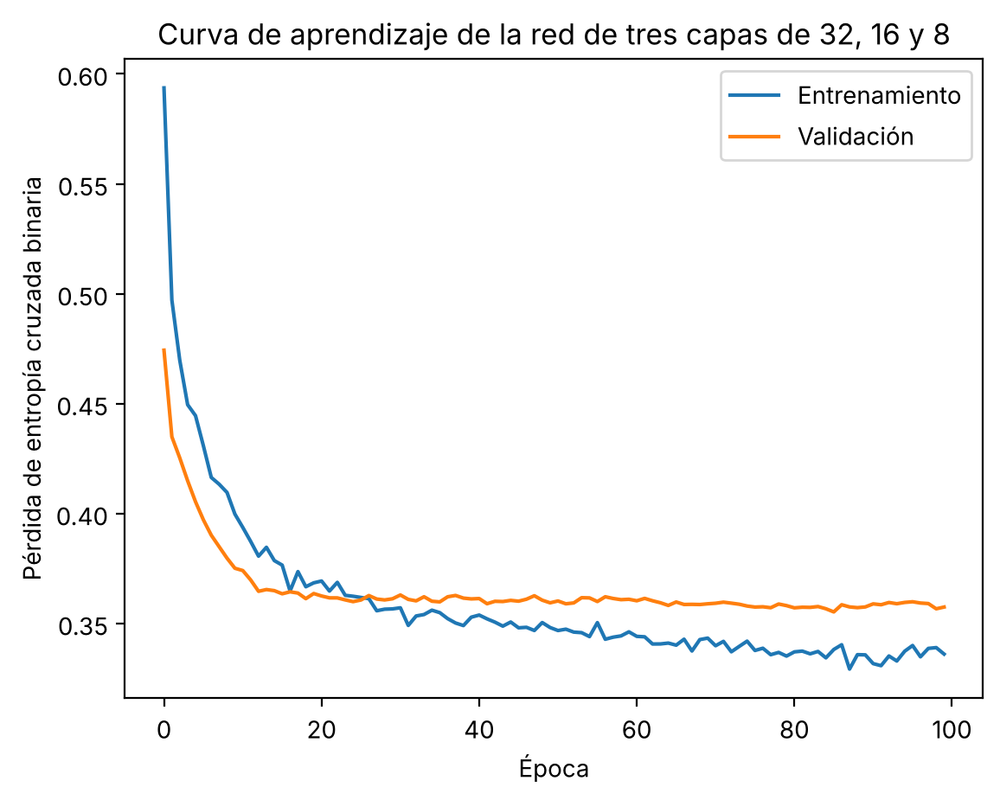

In [45]:
# mejor arquitectura según el F1 de validación y su curva de aprendizaje
f1_redes = {nombre: f1_score( y_val, (red.predict(X_val_esc, verbose=0).ravel() >= 0.5).astype(int))
            for nombre,red in redes.items()}
mejor_arquitectura =max(f1_redes, key=f1_redes.get)

modelo_red = redes[mejor_arquitectura]
print("Mejor arquitectura:", mejor_arquitectura)

historia = historias[mejor_arquitectura].history
plt.plot(historia["loss"], label="Entrenamiento")
plt.plot(historia["val_loss"], label="Validación")
plt.xlabel("Época")
plt.ylabel("Pérdida de entropía cruzada binaria")
plt.title("Curva de aprendizaje de la red de " + mejor_arquitectura)

plt.legend()

plt.show()

La red de referencia, con dos capas ocultas de 16 y 8 neuronas, tiene 337 parámetros: 192 en la primera capa, 136 en la segunda y 9 en la salida. La salida usa sigmoide porque convierte el resultado en un número entre 0 y 1 que se lee como la probabilidad de abandono, igual que la regresión logística.

De las tres arquitecturas con Dropout, la de una capa de 8 neuronas tuvo un F1 de validación de 0,515, la de 16 y 8 tuvo 0,543 y la de 32, 16 y 8 tuvo 0,548. Gana la más grande, pero por 0,005 sobre la intermedia, una diferencia que no distigue una de la otra. Una red más grande no es siempre mejor, y aquí se ve porque pasar de una a dos capas ayuda y pasar de dos a tres casi no cambia. La curva de aprendizaje muestra que la pérdida de validación deja de bajar cerca de la época 25 y se queda alrededor de 0,36, mientras la de entrenamiento sigue bajando un poco. Hay un sobreajuste leve después de unas 40 épocas, no grave.

## 3. Análisis cuantitativo de los resultados

Ayudas usadas: matriz de confusión, exactitud, precisión, recall, F1, curva ROC, curva deprecisión y recall, bootstrapping, intervalo de confianza por bootstrapping, prueba A B entre dos modelos, pruba t y prueba de McNemar, de las Prácticas 2 y 4.

Los modelos secomparan y se eligen con el conjunto de validación. El conjunto de prueba se usa por primera vez después de elegir, para evaluar los modelos finalistas y para la comparación estadística. Se mantiene el mismo orden de las actividades de la práctica: primeo los modelos basicos, luego los ensambles y luego la red neuronal.

In [46]:
from sklearn.metrics import (confusion_matrix,ConfusionMatrixDisplay,PrecisionRecallDisplay,RocCurveDisplay,  accuracy_score,
                             precision_score, recall_score, roc_auc_score, average_precision_score, classification_report)

#funciones para tratar igual a los de scikit learn y a la red de Keras
def es_keras(modelo):
    return isinstance(modelo,  keras.Model)

def probabilidades(modelo,X):
    if es_keras(modelo):
        return modelo.predict(X, verbose=0).ravel()
    return modelo.predict_proba(X)[:,  1]

def clases(modelo,X):
    if es_keras(modelo):
        return (probabilidades(modelo, X ) >= 0.5).astype( int )
    return modelo.predict(X)

def metricas_modelo(modelo, X,  y ):
    y_pred, y_prob = clases(modelo, X),probabilidades(modelo, X)
    return {"exactitud": accuracy_score(y, y_pred ), "precisión": precision_score(y,  y_pred),
            "recall": recall_score( y, y_pred), "F1": f1_score(y, y_pred),
            "AUC": roc_auc_score(y, y_prob), "AP": average_precision_score(y, y_prob)}

modelos_basicos = { "Regresión logística": modelo_lr, "Árbol de decisión": modelo_dt, "KNN": modelo_knn}
modelos_ensambles= {"Random Forest": modelo_rf, "Gradient Boosting": modelo_gb,
                     "Votación suave": votacion_suave, "Stacking": modelo_st}
modelos_red = {"Red neuronal": modelo_red}

todos = {**modelos_basicos, **modelos_ensambles,  **modelos_red}
conjuntos = {"Entrenamiento": (X_train_esc, y_train), "Validación": (X_val_esc, y_val)}

In [47]:
#matrices de confusión, métrics y curvas deprecisión recall y ROC de un grupo de modelos
def evaluar_grupo(grupo):
    fig, axes= plt.subplots(len(conjuntos), len(grupo), figsize=(4.5 * len(grupo), 8),squeeze=False)
    for j, (nombre, modelo) in enumerate(grupo.items()):
        for i, (titulo, (X_c, y_c)) in enumerate(conjuntos.items()):
            ConfusionMatrixDisplay.from_predictions(y_c, clases(modelo, X_c), ax=axes[i, j], colorbar=False)
            axes[i,j].set_title(nombre + " en " + titulo.lower())
    plt.tight_layout()
    plt.show()

    filas =[]
    for nombre, modelo in grupo.items():
        for titulo, (X_c, y_c) in conjuntos.items():
            filas.append({"modelo": nombre, "conjunto": titulo, **metricas_modelo(modelo, X_c, y_c)})
    tabla = pd.DataFrame(filas)
    print(tabla.round(3).to_string(index=False))

    #cuános clientes que se van detecta cada modelo y cuántas falsas alarmas da
    filas_conteo= []
    for nombre, modelo in grupo.items():
        for titulo, (X_c,  y_c) in conjuntos.items():
            vn, fp, fn, vp= confusion_matrix(y_c, clases(modelo, X_c), labels=[0,1]).ravel()
            filas_conteo.append({"modelo": nombre,  "conjunto": titulo, "abandonos reales": vp + fn,
                                 "abandonos detectados": vp, "falsas alarmas": fp})
    print(pd.DataFrame(filas_conteo).to_string(index=False))

    fig,  axes =plt.subplots(1,2, figsize=(14,4), sharey=True)
    for ax, titulo in zip(axes, conjuntos):
        sns.barplot( data=tabla[tabla["conjunto"] == titulo].melt(id_vars=["modelo", "conjunto"],
                    value_vars=["exactitud", "precisión", "recall","F1"]),
                    x="variable", y="value", hue="modelo", ax=ax)
        ax.set_title("Métricas en "+ titulo.lower())
        ax.set_xlabel("")
        ax.set_ylabel("Valor de la métrica")
    plt.tight_layout()
    plt.show()

    for curva, titulo_curva in [(PrecisionRecallDisplay, "Curvas de precisión y recall"), (RocCurveDisplay, "Curvas ROC")]:
        fig, axes = plt.subplots( 1,2, figsize=(12, 5),sharey=True)
        for ax, (titulo, (X_c, y_c)) in zip(axes, conjuntos.items()):
            for nombre, modelo in grupo.items():
                curva.from_predictions(y_c, probabilidades(modelo, X_c ), ax=ax, name=nombre)
            if curva is PrecisionRecallDisplay:
                ax.axhline((y_c== 1).mean(),color="k",linestyle="--", label="Línea base")
            else:
                ax.plot([0,1], [0, 1], "k--", label="Azar")
            ax.set_title(titulo_curva + " en " + titulo.lower())
            ax.legend(loc="lower left" if curva is PrecisionRecallDisplay else "lower right")
        plt.tight_layout()
        plt.show()
    return tabla

### 3.1 Modelos básicos

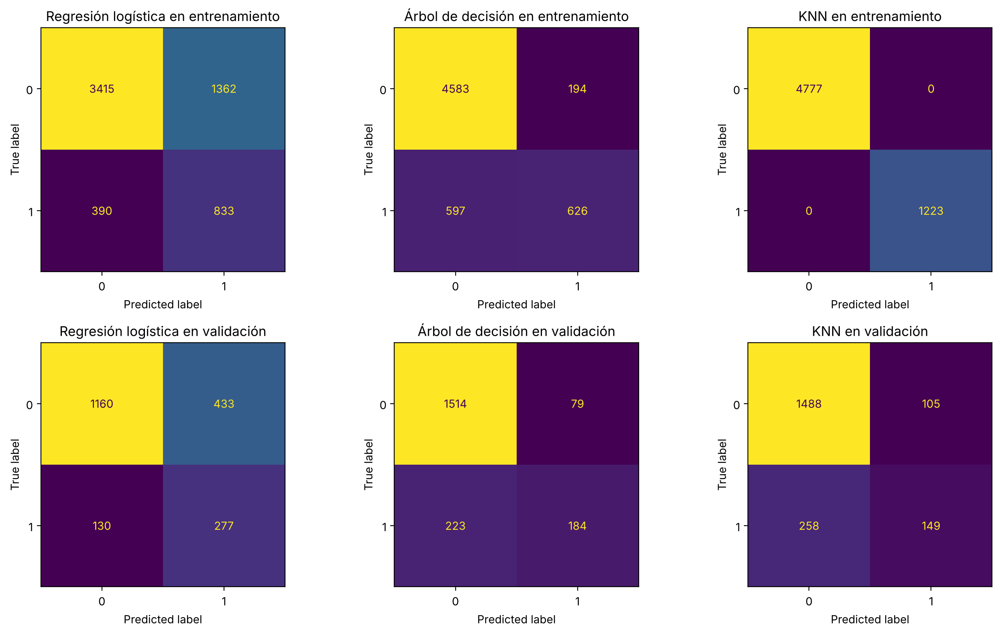

             modelo      conjunto  exactitud  precisión  recall    F1   AUC    AP
Regresión logística Entrenamiento      0.708      0.379   0.681 0.487 0.764 0.465
Regresión logística    Validación      0.718      0.390   0.681 0.496 0.763 0.452
  Árbol de decisión Entrenamiento      0.868      0.763   0.512 0.613 0.885 0.726
  Árbol de decisión    Validación      0.849      0.700   0.452 0.549 0.817 0.622
                KNN Entrenamiento      1.000      1.000   1.000 1.000 1.000 1.000
                KNN    Validación      0.818      0.587   0.366 0.451 0.732 0.488
             modelo      conjunto  abandonos reales  abandonos detectados  falsas alarmas
Regresión logística Entrenamiento              1223                   833            1362
Regresión logística    Validación               407                   277             433
  Árbol de decisión Entrenamiento              1223                   626             194
  Árbol de decisión    Validación               407               

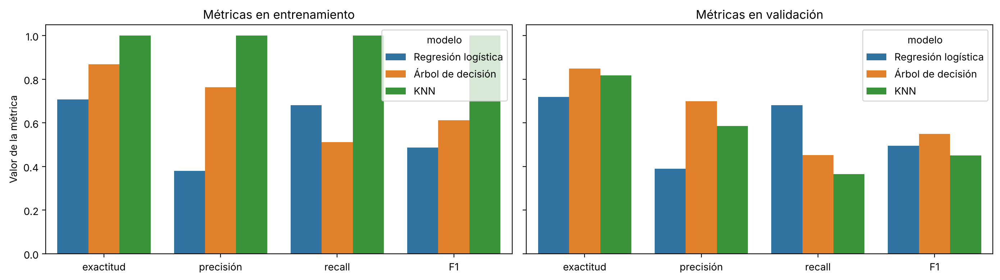

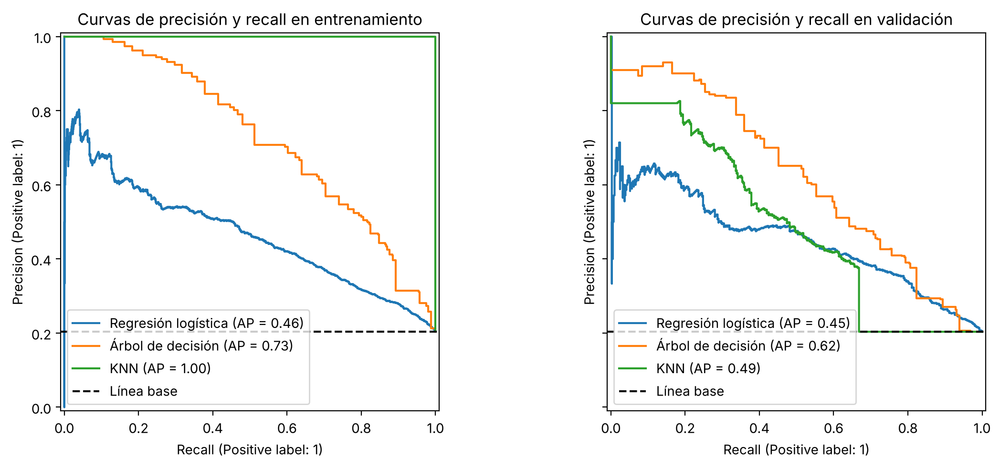

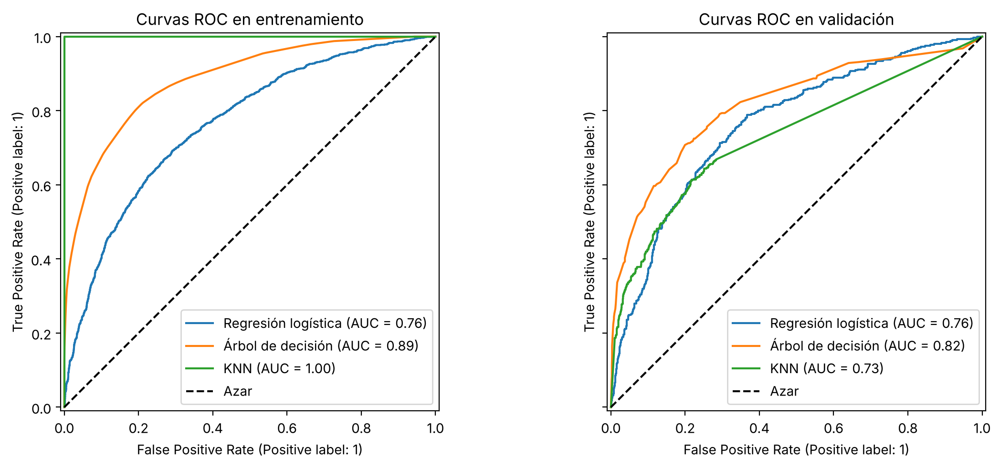

In [48]:
tabla_basicos = evaluar_grupo(modelos_basicos)

En validación, la regresión logística detecta 277 de los 407 clientes que abandonan, con 433 falsas alarmas. El árbol detecta 184 con 79 falsas alarmas, y KNN detecta 149 con 105. La regresión logística detecta más pero molesta a muchos clientes que no se iban a ir, y el árbol hace lo contrario.

El modelo con más diferencia entre entrenamiento y validacion es KNN. En entrenamiento tiene exactitud, precisión, recall y F1 de 1,000, y en validación el F1 baja a 0,451. Con 3 vecinos y pesos por distancia, cada cliente de entrenamiento es su propio vecino más cercano, así que se predice a sí mismo y la métrica de entrenamiento no dice nada sobre cómo generaliza. El árbol, baja de un F1 de 0,613 a 0,549 y la regresión logística casi no cambia, de 0,487 a 0,496.

En las curvas, el árbol tiene el mayor AP de validación, 0,622, contra 0,488 de KNN y 0,452 de la regresión logística. También tiene el mayor AUC, 0,817. La línea base de la curva de precisión y recall es la proporción de la clase positiva, cerca de 0,20. Las curvas ROC se ven más optimistas que las de precisión y recall porque la tasa de falsos positivos se calcula entre muchos negativos, y un modelo que se equivoca con pocos de ellos ya queda cerca de la esquina de arriba a la izquierda, aunque su precisión sea baja.

El mejor modelo básico por F1 de validación es el árbol, con 0,549. Si para el banco fuera más costoso no detectar a un cliente que se va que contactar a uno que no, convendría la regresión logística, que tiene el mayor recall, 0,681, aunque su F1 sea menor.

### 3.2 Ensambles

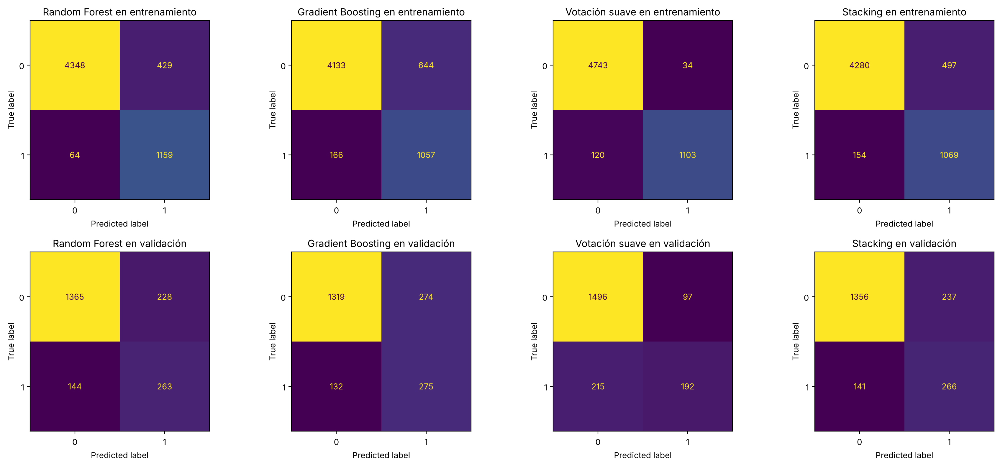

           modelo      conjunto  exactitud  precisión  recall    F1   AUC    AP
    Random Forest Entrenamiento      0.918      0.730   0.948 0.825 0.980 0.927
    Random Forest    Validación      0.814      0.536   0.646 0.586 0.839 0.659
Gradient Boosting Entrenamiento      0.865      0.621   0.864 0.723 0.940 0.831
Gradient Boosting    Validación      0.797      0.501   0.676 0.575 0.834 0.659
   Votación suave Entrenamiento      0.974      0.970   0.902 0.935 0.998 0.993
   Votación suave    Validación      0.844      0.664   0.472 0.552 0.827 0.636
         Stacking Entrenamiento      0.892      0.683   0.874 0.767 0.963 0.876
         Stacking    Validación      0.811      0.529   0.654 0.585 0.838 0.654


           modelo      conjunto  abandonos reales  abandonos detectados  falsas alarmas
    Random Forest Entrenamiento              1223                  1159             429
    Random Forest    Validación               407                   263             228
Gradient Boosting Entrenamiento              1223                  1057             644
Gradient Boosting    Validación               407                   275             274
   Votación suave Entrenamiento              1223                  1103              34
   Votación suave    Validación               407                   192              97
         Stacking Entrenamiento              1223                  1069             497
         Stacking    Validación               407                   266             237


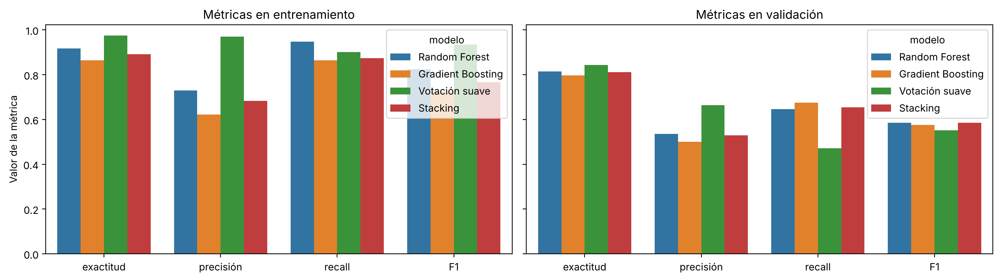

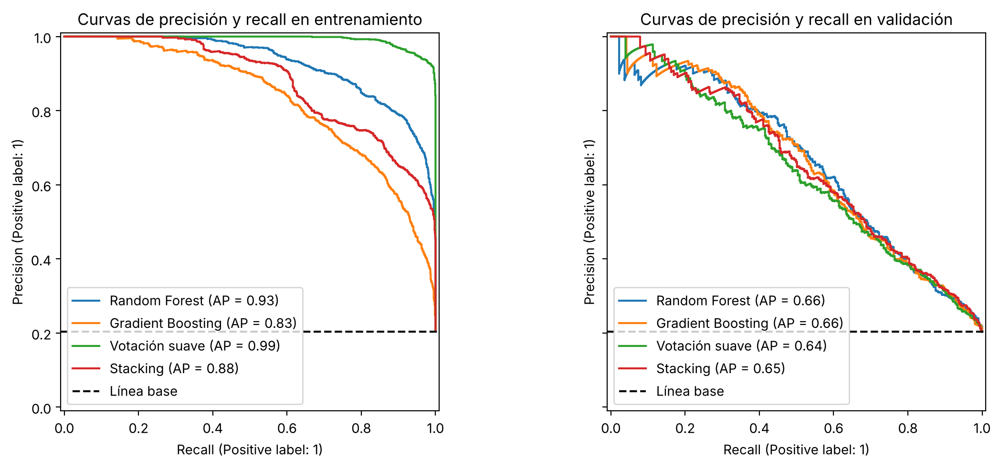

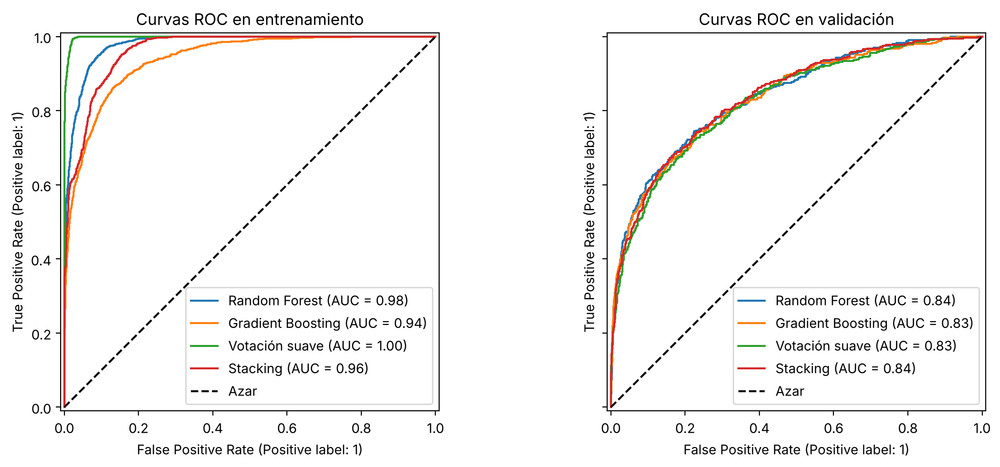

In [49]:
tabla_ensambles = evaluar_grupo(modelos_ensambles)

En validación, el Random Forest detecta 263 de los 407 abandonos con 228 falsas alarmas, el Gradient Boosting detecta 275 con 274, la votación suave detecta 192 con 97 y el stacking detecta 266 con 237. Los ensambles de árboles detectan más clientes que el mejor modelo básico, el árbol con 184, y a cambio generan bastantes más falsas alarmas.

El ensamble con más sobreajuste es la votación suave, con un F1 de 0,935 en entrenamiento y 0,552 en validación. La causa es el KNN que va dentro de la votación, que memoriza el entrenamiento. Le sigue el Random Forest, con 0,825 contra 0,586. El Gradient Boosting es el que menos se pasa, de 0,723 a 0,575.

El mayor AP de validación lo comparten el Random Forest y el Gradient Boosting, con 0,659, y el mayor AUC es el del Random Forest, con 0,839.

### 3.3 Red neuronal

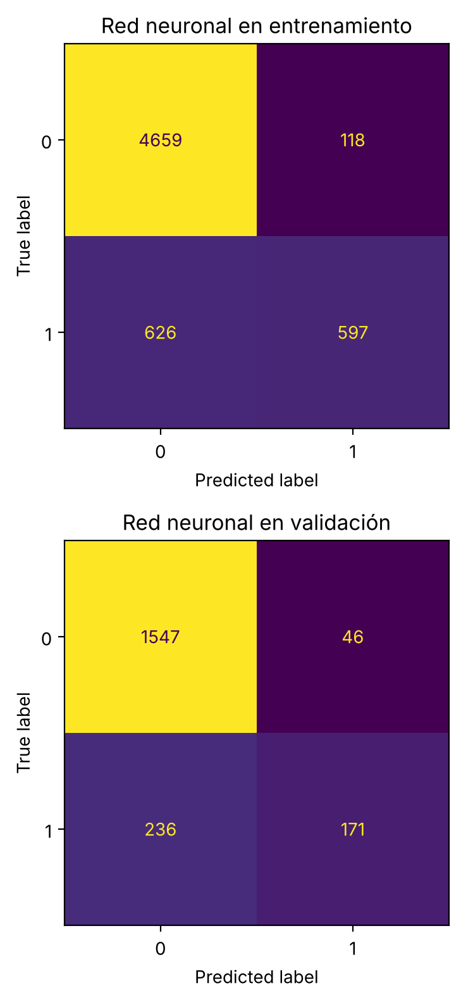

      modelo      conjunto  exactitud  precisión  recall    F1   AUC    AP
Red neuronal Entrenamiento      0.876      0.835   0.488 0.616 0.895 0.758
Red neuronal    Validación      0.859      0.788   0.420 0.548 0.837 0.667


      modelo      conjunto  abandonos reales  abandonos detectados  falsas alarmas
Red neuronal Entrenamiento              1223                   597             118
Red neuronal    Validación               407                   171              46


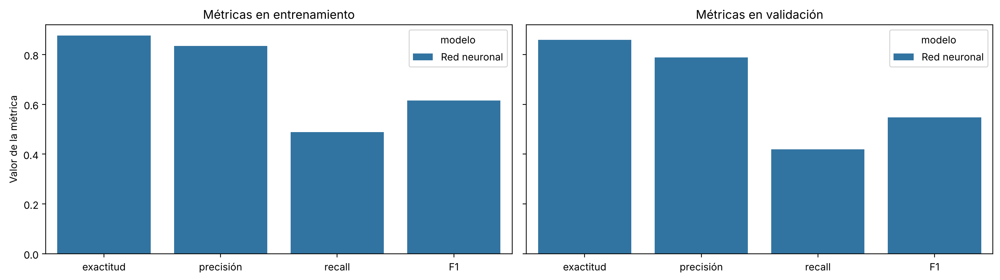

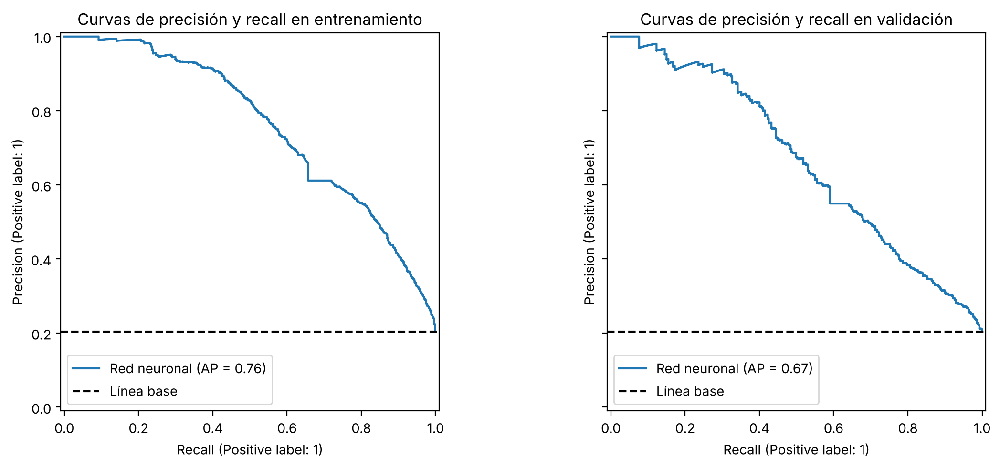

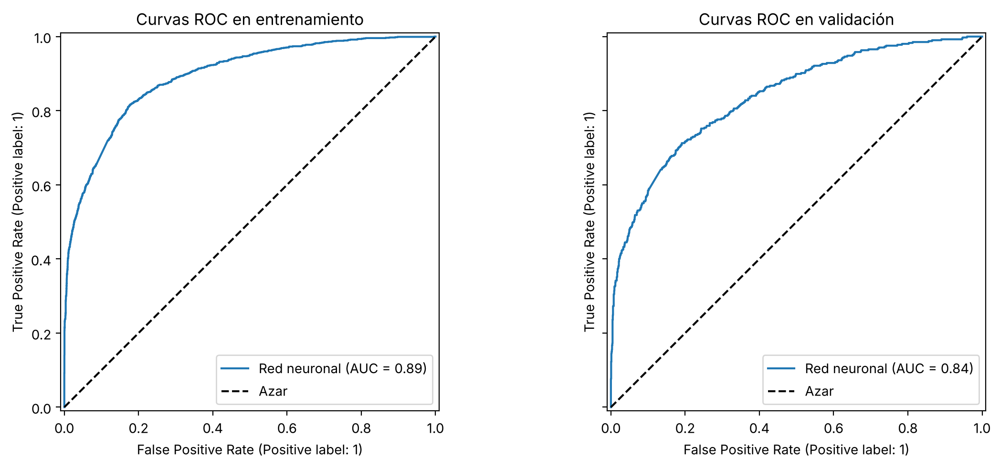

In [50]:
tabla_red = evaluar_grupo(modelos_red)

La red neuronal detecta 171 de los 407 abandonos con 46 falsas alarmas. Es el modelo que menos falsas alarmas genera, pero detecta pocos clientes. Con umbral 0,5 tiene una precisión de 0,788 y un recall de 0,420. Su F1 de validación es 0,548. Entre entrenamiento y validación casi no cambia, de 0,616 a 0,548, así que no sobreajusta mucho. Tiene el mayor AP de todos los modelos, 0,667, lo que indica que ordena bien a los clients aunque con el umbral de 0,5 deje escapar a muchs. Moviendo el umbral se podría ganar recall.

### 3.4 Elección del modelo final con la validación

                     exactitud  precisión  recall     F1    AUC     AP
modelo                                                                
Regresión logística      0.718      0.390   0.681  0.496  0.763  0.452
Árbol de decisión        0.849      0.700   0.452  0.549  0.817  0.622
KNN                      0.818      0.587   0.366  0.451  0.732  0.488
Random Forest            0.814      0.536   0.646  0.586  0.839  0.659
Gradient Boosting        0.797      0.501   0.676  0.575  0.834  0.659
Votación suave           0.844      0.664   0.472  0.552  0.827  0.636
Stacking                 0.811      0.529   0.654  0.585  0.838  0.654
Red neuronal             0.859      0.788   0.420  0.548  0.837  0.667


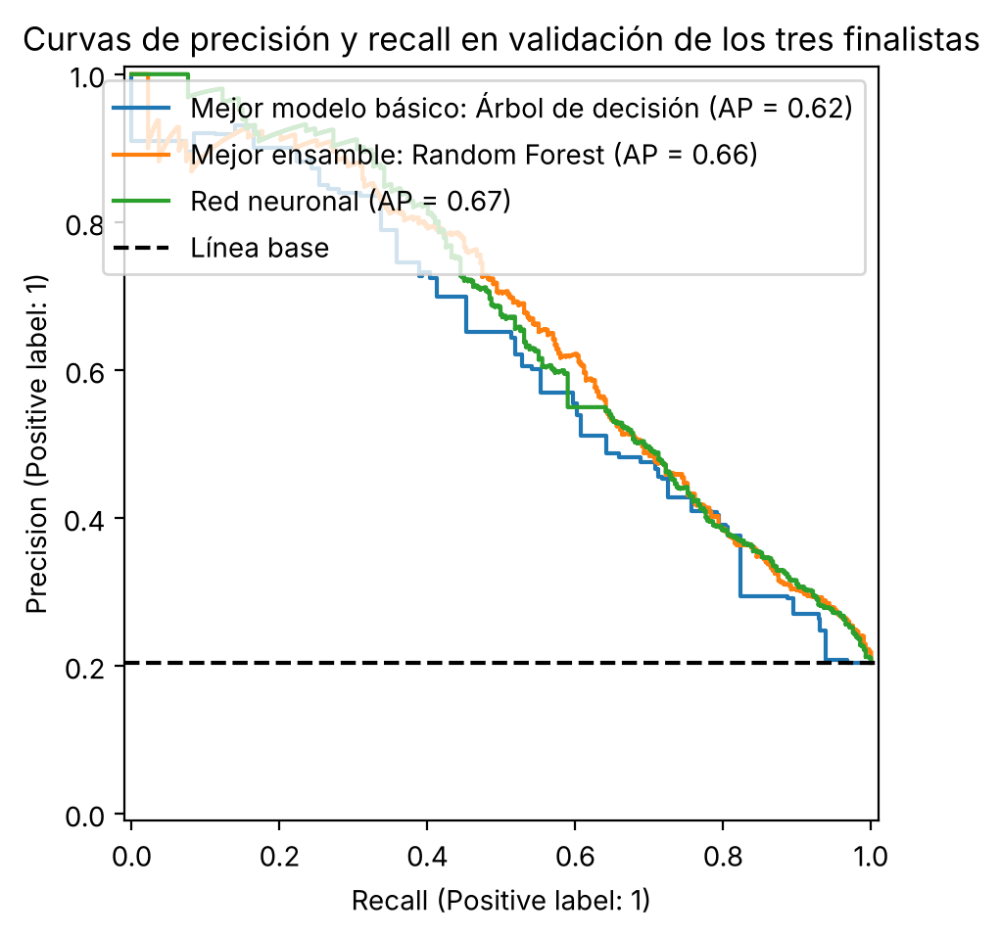

Modelo con el mayor F1 de validación: Random Forest


In [51]:
tabla_val = pd.concat([tabla_basicos,  tabla_ensambles, tabla_red])
tabla_val =tabla_val[tabla_val["conjunto"] == "Validación"].set_index("modelo").drop(columns="conjunto")
print(tabla_val.round(3))

mejor_basico = tabla_val.loc[list(modelos_basicos), "F1"].idxmax()
mejor_ensamble = tabla_val.loc[list(modelos_ensambles),"F1"].idxmax()
finalistas = { "Mejor modelo básico: "+ mejor_basico: todos[mejor_basico],
              "Mejor ensamble: " + mejor_ensamble: todos[mejor_ensamble],
              "Red neuronal": modelo_red}

# curvas de precisión y recall en validación de los tres finalistas
fig,  ax= plt.subplots(figsize=(7, 5))

for nombre,modelo in finalistas.items():
    PrecisionRecallDisplay.from_predictions(y_val, probabilidades(modelo, X_val_esc), ax=ax, name=nombre)
ax.axhline((y_val == 1).mean(), color="k", linestyle="--", label="Línea base" )
ax.set_title("Curvas de precisión y recall en validación de los tres finalistas")
ax.legend(loc="upper right")
plt.show()

modelo_elegido= tabla_val["F1"].idxmax()

print("Modelo con el mayor F1 de validación:", modelo_elegido)

El Random Forest tiene el mayor F1 de validación, 0,586, y el mayor AUC, 0,839. Pero el stacking, con 0,585, y el Gradient Boosting, con 0,575, quedan muy cerca. La diferencia de 0,001 entre el Random Forest y el stacking no permite decir que uno sea mejor. La actividad dice que si dos modelos son parecidos se prefiere el más simple, y entre los dos el Random Forest es más simple que un stacking que entrena cuatro modelos. Se elige el Random Forest.

Los ensambles mejoran al mejor modelo básico. El F1 sube de 0,549 del árbol a 0,586, una mejora de 0,037. Esa mejora cuesta tiempo de entrenamiento, 400 árboles contra uno, y interpretabilidad, porque un árbol de profundidad 7 se puede leer y un bosque no. La red neuronal quedó en 0,548, igual al árbol.

Si el banco valorara más no perder clientes que molestar a los que no se iban a ir, la elección podría cambiar hacia un modelo de mayor recall, como la regresión logística o el Gradient Boosting, o bajar el umbral del Random Forest. Esto se evalúa con dinero en la sección 5.

### 3.5 Evaluación de los finalistas en el conjunto de prueba

In [52]:
filas =[]
for nombre, modelo in finalistas.items():
    for titulo, X_c, y_c in [("Validación", X_val_esc, y_val), ("Prueba", X_test_esc, y_test)]:
        filas.append({"modelo": nombre, "conjunto": titulo, **metricas_modelo(modelo, X_c, y_c)})
tabla_finalistas= pd.DataFrame(filas)
print(tabla_finalistas.round(3).to_string(index=False))
print("Exactitud de la línea base en prueba:", round(y_test.value_counts(normalize=True).max(), 3))

                                modelo   conjunto  exactitud  precisión  recall    F1   AUC    AP
Mejor modelo básico: Árbol de decisión Validación      0.849      0.700   0.452 0.549 0.817 0.622
Mejor modelo básico: Árbol de decisión     Prueba      0.850      0.709   0.442 0.545 0.827 0.633
         Mejor ensamble: Random Forest Validación      0.814      0.536   0.646 0.586 0.839 0.659
         Mejor ensamble: Random Forest     Prueba      0.825      0.559   0.666 0.608 0.855 0.681
                          Red neuronal Validación      0.859      0.788   0.420 0.548 0.837 0.667
                          Red neuronal     Prueba      0.854      0.775   0.398 0.526 0.837 0.662
Exactitud de la línea base en prueba: 0.796


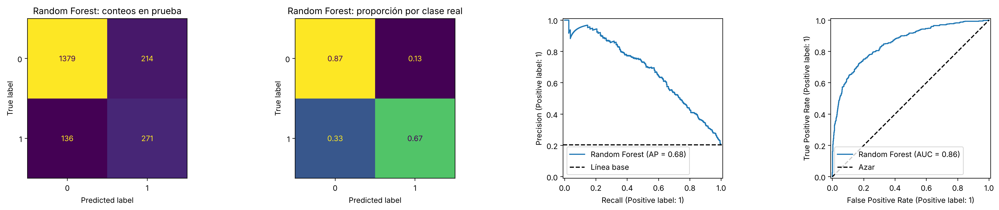

              precision    recall  f1-score   support

           0       0.91      0.87      0.89      1593
           1       0.56      0.67      0.61       407

    accuracy                           0.82      2000
   macro avg       0.73      0.77      0.75      2000
weighted avg       0.84      0.82      0.83      2000



In [53]:
#detalle del modelo que salió elegido en valiación
modelo_elegido_obj = todos[modelo_elegido]
y_pred_elegido = clases(modelo_elegido_obj, X_test_esc)

fig, axes = plt.subplots(1, 4, figsize=(20, 4) )
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_elegido, ax=axes[0],  colorbar=False)
axes[0].set_title(modelo_elegido + ": conteos en prueba")
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_elegido,normalize="true",  ax=axes[1], colorbar=False)
axes[1].set_title(modelo_elegido + ": proporción por clase real")
PrecisionRecallDisplay.from_predictions(y_test,probabilidades(modelo_elegido_obj, X_test_esc), ax=axes[2], name=modelo_elegido)
axes[2].axhline((y_test == 1).mean(), color="k", linestyle="--",  label="Línea base")
axes[2].legend()
RocCurveDisplay.from_predictions(y_test, probabilidades(modelo_elegido_obj, X_test_esc), ax=axes[3], name=modelo_elegido )
axes[3 ].plot([0, 1], [0,1], "k--", label="Azar" )
axes[3].legend()
plt.tight_layout()
plt.show()
print(classification_report(y_test,  y_pred_elegido))

Los tres finalistas en prueba son el árbol, el Random Forest y la red. El Random Forest sigue siendo el mejor en F1, con 0,608, contra 0,545 del árbol y 0,526 de la red. El modelo elegido en validación sigue siendo el mejor en prueba, así que no hay que cambiar la elección, y no debe cambiar mirando la prueba, dado que eso la convertiría en otro conjunto de validación y ya no mediría cómo se comporta el modelo con clientes nuevos.

Las métricas del Random Forest se mantienen, y hasta mejoran un poco: exactitud de 0,825 en prueba contra 0,814 en validación, precisión de 0,559 contra 0,536, recall de 0,666 contra 0,646, F1 de 0,608 contra 0,586, AUC de 0,855 contra 0,839 y AP de 0,681 contra 0,659. La diferencia entre validación y prueba se explica sobre todo por la variación de muestra, dado que son 2.000 clientes en cada conjunto, y no porque el modelo haya aprendido algo nuevo.

La exactitud de la línea base en prueba, un modelo que siempre dice que el cliente se queda, es 0,796. El Random Forest tiene 0,825, solo 0,029 más. Y el árbol y la red tienen mayor exactitud que el Random Forest, 0,850 y 0,854, aunque detectan menos abandonos. Esto es lo que muestra que la exactitud sola no es suficiente cuando hay desbalance: el modelo con mejor exactitud no es el mejor para el banco. Es por esto, que se mira el F1, la precisión y el recall.

El Random Forest se equivoca más con falsas alarmas que con abandonos no detectados. Entre los clientes que marca, 56% abandona, y de los que abandonan detecta 67%. Si el banco quisiera detectar más, podría bajar el umbral de decisión, con el costo de que suben las falsas alarmas y baja la precisión, como se ve en la sección 5.

### 3.6 Configuración 1: ingeniería de características

Ayudas usadas: actividad 1 de la Práctica 4. El modelo elegido se entrena dos veces con los mismos hiperparámetros: con el conjunto original, que es el modelo 1A, y con el ampliado, que es el modelo 1B. La comparación se hace con el F1 de validación y el conjunto con mayor F1 se usa en la configuración 2.

In [54]:
from sklearn.base import clone

# reentrena el modelo con los mismos hiperparámetros pero con otro conjunto de variables
def reentrenar(nombre, conjunto):
    modelo=todos[nombre]
    X_tr, X_va = X_esc[conjunto]["train" ],  X_esc[conjunto]["val"]
    if es_keras(modelo):
        red=construir_red(arquitecturas[mejor_arquitectura],X_tr.shape[1])
        red.fit(X_tr, y_train.to_numpy(), validation_data=(X_va, y_val.to_numpy()), epochs=100,batch_size=32, verbose=0)
        return red
    nuevo = clone(modelo )
    nuevo.fit(X_tr, y_train)
    return nuevo

def modelo_en(nombre, conjunto):
    return todos[nombre] if conjunto == "original" else reentrenar(nombre, "ampliado")

modelo_1A = todos[modelo_elegido]
modelo_1B= reentrenar(modelo_elegido, "ampliado")

filas = []
for etiqueta, modelo, conjunto in [("1A", modelo_1A, "original"), ("1B",  modelo_1B, "ampliado")]:
    m =metricas_modelo(modelo, X_esc[conjunto ]["val"],y_val)
    filas.append({"modelo": etiqueta,"tipo": modelo_elegido,  "conjunto de variables": conjunto,
                  "precisión": m["precisión"], "recall": m["recall"], "F1": m["F1" ]})
tabla_config1 =pd.DataFrame(filas).set_index("modelo")
print( tabla_config1.round(3))

conjunto_elegido= tabla_config1["conjunto de variables"].iloc[tabla_config1["F1"].to_numpy().argmax()]
print("Conjunto de variables con el mayor F1 de validación:",conjunto_elegido)

                 tipo conjunto de variables  precisión  recall     F1
modelo                                                               
1A      Random Forest              original      0.536   0.646  0.586
1B      Random Forest              ampliado      0.530   0.654  0.585
Conjunto de variables con el mayor F1 de validación: original


Se retoma el Random Forest, el modelo elegido, con sus mismos hiperparámetros. El modelo 1A usa las variables originales y tiene un F1 de validación de 0,586. El modelo 1B usa las originales más las cinco derivadas y tiene 0,585, con precisión de 0,530 contra 0,536 y recall de 0,654 contra 0,646. Entre los dos cambia solo el conjunto de variables.

La diferencia es de 0,001 y gana el conjunto original, por lo que ese es el que se usa en la configuración 2. Que las derivadas no ayuden es lo esperado en un modelo de árboles, que ya encuentra por sí mismo los cortes y las interacciones, como indica la ayuda de características derivadas. Las derivadas podrían ayudar a la regreión logística, pero no se probó porque la actividad solo pide el modelo final.

### 3.7 Configuración 2: tipo de modelo

El mejor modelo básico es el modelo 2A y el mejor ensamble es el modelo 2B. Se entrenan con el conjunto de variables que ganó en la configuración 1 y con sus mismos hiperparámetros.

In [55]:
modelo_2A = modelo_en(mejor_basico,  conjunto_elegido)

modelo_2B=modelo_en(mejor_ensamble, conjunto_elegido)

cuatro ={"1A": (modelo_1A, "original"), "1B": (modelo_1B, "ampliado"),
          "2A": (modelo_2A, conjunto_elegido), "2B": (modelo_2B, conjunto_elegido)}
nombre_conjunto ={"original": "originales", "ampliado": "ampliadas"}
descripcion = {"1A": modelo_elegido + " con variables originales", "1B": modelo_elegido + " con variables ampliadas",
               "2A": mejor_basico+ " con variables " + nombre_conjunto[conjunto_elegido],
               "2B": mejor_ensamble + " con variables " + nombre_conjunto[conjunto_elegido]}

filas= []
for etiqueta, (modelo, conjunto) in cuatro.items():
    m = metricas_modelo(modelo, X_esc[conjunto]["val"], y_val)
    filas.append({"modelo": etiqueta, "descripción": descripcion[etiqueta],
                  "precisión": m["precisión"], "recall": m["recall"], "F1 validación": m["F1"]})
tabla_cuatro = pd.DataFrame(filas).set_index( "modelo")

print(tabla_cuatro.round(3))
print("Ganador de la configuración 1:",tabla_cuatro.loc[["1A", "1B"],"F1 validación"].idxmax())
print("Ganador de la configuración 2:", tabla_cuatro.loc[["2A", "2B"], "F1 validación"].idxmax())

                                       descripción  precisión  recall  \
modelo                                                                  
1A          Random Forest con variables originales      0.536   0.646   
1B           Random Forest con variables ampliadas      0.530   0.654   
2A      Árbol de decisión con variables originales      0.700   0.452   
2B          Random Forest con variables originales      0.536   0.646   

        F1 validación  
modelo                 
1A              0.586  
1B              0.585  
2A              0.549  
2B              0.586  
Ganador de la configuración 1: 1A
Ganador de la configuración 2: 2B


El modelo 2A es el árbol de decisión, el mejor modelo básico, y el 2B es el Random Forest, el mejor ensamble, los dos con variables originales. En validación el 2A tiene una precisión de 0,700, un recall de 0,452 y un F1 de 0,549. El 2B tiene 0,536, 0,646 y 0,586. Gana el 2B en F1, por 0,037. La diferencia es pequeña en F1, pero grande en la forma: el árbol acierta más cuando marca a un cliente y el bosque detecta muchos más abandonos.

El 2B es el mismo modelo que el 1A, porque el Random Forest con variables originales ganó en las dos configuraciones. Por eso los intervalos y los resultados de 1A y 2B coinciden.

### 3.8 Bootstrapping sobre el conjunto de prueba

Se hacen 1000 réplicas con semilla 42. En cada réplica se remuestrea el conjunto de prueba una sola vez y se calcula el F1 de los cuatro modelos sobre los mismos clientes. Los modelos no se vuelven a entrenar porque lo que cambia entre réplicas son los clientes que se evalúan y no los modelos.

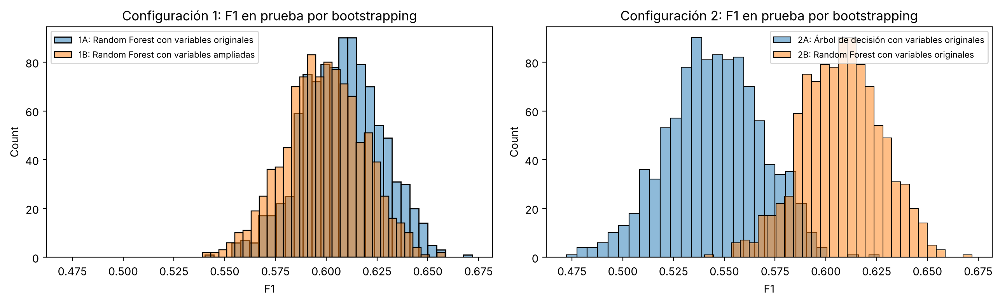

In [56]:
pred_test = {etiqueta: clases(modelo,X_esc[conjunto]["test"]) for etiqueta, (modelo,conjunto) in cuatro.items()}
y_test_arr = np.asarray(y_test)
n_test = len(y_test_arr)

rng =np.random.default_rng(42)
B = 1000
boot_f1 ={etiqueta: np.empty(B) for etiqueta in cuatro}
for b in range(B):
    idx= rng.integers(0, n_test, n_test)
    for etiqueta in cuatro:
        boot_f1[etiqueta][b] = f1_score(y_test_arr[idx],pred_test[etiqueta][idx])

configuraciones={"Configuración 1": ["1A","1B"], "Configuración 2": [ "2A", "2B"]}
fig,axes = plt.subplots(1, 2, figsize=(13,  4), sharex=True )
for ax, (titulo, etiquetas) in zip(axes, configuraciones.items()):
    for etiqueta in etiquetas:
        sns.histplot(boot_f1[etiqueta ], bins=30, alpha=0.5, label=etiqueta + ": " + descripcion[etiqueta], ax=ax)
    ax.set_title(titulo + ": F1 en prueba por bootstrapping")
    ax.set_xlabel("F1")
    ax.legend( fontsize=8)
plt.tight_layout()
plt.show()

        F1 validación  F1 prueba  IC inferior  IC superior  \
modelo                                                       
1A              0.586      0.608        0.569        0.645   
1B              0.585      0.599        0.559        0.636   
2A              0.549      0.545        0.498        0.588   
2B              0.586      0.608        0.569        0.645   

        validación dentro del intervalo  
modelo                                   
1A                                 True  
1B                                 True  
2A                                 True  
2B                                 True  


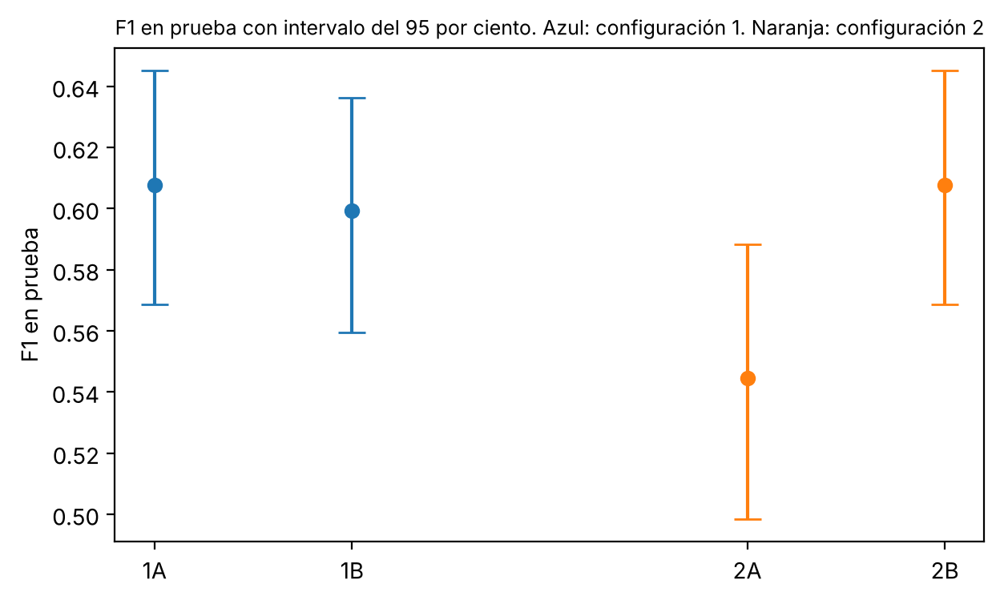

In [57]:
# intervalo del 95 por ciento con percentiles
filas = []
for etiqueta in cuatro:
    inferior, superior= np.percentile(boot_f1[ etiqueta],[2.5,  97.5])
    f1_prueba = f1_score(y_test_arr, pred_test[etiqueta])
    f1_validacion= tabla_cuatro.loc[etiqueta,"F1 validación"]
    filas.append({"modelo": etiqueta, "F1 validación": f1_validacion, "F1 prueba": f1_prueba,
                  "IC inferior": inferior, "IC superior": superior,
                  "validación dentro del intervalo": inferior <= f1_validacion <= superior} )
tabla_ic = pd.DataFrame(filas).set_index("modelo")
print(tabla_ic.round(3))

fig,  ax = plt.subplots(figsize=( 7, 4))
posiciones ={"1A": 0, "1B": 1, "2A": 3, "2B": 4}
for etiqueta, x in posiciones.items():
    f1_prueba,  inferior, superior = tabla_ic.loc[etiqueta, ["F1 prueba", "IC inferior", "IC superior"]]
    ax.errorbar(x, f1_prueba, yerr=[[f1_prueba - inferior], [superior - f1_prueba] ], fmt="o", capsize=6,
                 color="tab:blue" if x < 2 else "tab:orange")
ax.set_xticks( list(posiciones.values()), list(posiciones.keys()))
ax.set_ylabel("F1 en prueba")
ax.set_title("F1 en prueba con intervalo del 95 por ciento. Azul: configuración 1. Naranja: configuración 2")
ax.title.set_fontsize(9)
plt.show()

Con 1000 réplicas, el F1 en prueba del modelo 1A y del 2B es 0,608, con un intervalo del 95% de 0,569 a 0,645. El 1B es 0,599, con un intervalo de 0,559 a 0,636. El 2A es 0,545, con un intervalo de 0,498 a 0,588. No hace falta reentrenar en cada réplica porque los modelos ya están entrenados y lo que cambia entre réplicas son los clientes con los que se evalúan. El bootstrapping se hace sobre el conjunto de prueba y no sobre el de validación dado que la validación ya se usó para elegir, y sus cifras están inclinadas a favor del modelo elegido.

En la configuración 1 las distribuciones y los intervalos de 1A y 1B casi se montan por completo, así que con estos datos no se puede decir que uno sea mejor. En la configuración 2 los intervaos del árbol y del Random Forest se superponen un poco, entre 0,569 y 0,588, pero el del Random Forest queda más arriba. Que se superpongan no demuestra que sean equivalentes. Solo dice que con este conjunto de prueba la diferencia entre sus F1 no se distingue con claridad al mirar cada intervalo por separado. La prueba pareada de la sección siguiente, que compara los dos modelos con los mismos clientes, es más precisa.

El F1 de validación de cada modelo queda dentro de su intervalo de prueba, y el modelo elegido en validacion sigue siendo el mejor en prueba, así que no hay cambio de orden que explicar.

Un intervalo de 0,54 a 0,61, por ejemplo, significa para el banco que el F1 que tendría el modelo con clientes parecidos probablemente está en ese rango, y que el procedimiento acierta en 95 de cada 100 veces. Su ancho depende del tamaño del conjunto de prueba y de qué tan variable es la métrica. Con el doble de clientes el intervalo se haría más angosto, más o menos en un factor de uno sobre la raíz de dos, es decir unos 30% menos. La limitación de comparar dos cifras de F1 es que cada una trae incertidumbre, y una diferencia de unas centésimas puede ser solo ruido.

### 3.9 Pruebas A B pareadas, prueba t y McNemar

Ayudas usadas: acividad 2 de la Práctica 4. En cada configuración el modelo A es el primero y el modelo B el segundo. Los dos modelos se aplican a los mismos clientes de prueba. Por lo tanto, corresponde una prueba pareada. La diferencia mínima relevante es 0,02 en cada métrica.

In [58]:
from statsmodels.stats.contingency_tables import mcnemar

metricas_ab = {"F1": f1_score,  "Precisión": precision_score, "Recall": recall_score}
umbral_relevante=0.02

def comparar_pareado(etiqueta_a, etiqueta_b):
    pred_a,pred_b = pred_test[etiqueta_a], pred_test[etiqueta_b]

    # bootstrapping con muestras pareadas
    rng= np.random.default_rng( 42)
    boot_a = {nombre: np.empty(B) for nombre in metricas_ab}
    boot_b = {nombre: np.empty(B) for nombre in metricas_ab}
    for b in range(B ):
        idx = rng.integers(0, n_test, n_test)
        for nombre, metrica in metricas_ab.items():
            boot_a[ nombre][b]= metrica(y_test_arr[idx], pred_a[idx], zero_division=0)
            boot_b[nombre][b] = metrica(y_test_arr[idx],  pred_b[idx], zero_division=0)

    filas = []
    for nombre,  metrica in metricas_ab.items():
        d = boot_a[nombre] - boot_b[nombre]
        inferior, superior = np.percentile(d, [2.5, 97.5])
        observada = metrica(y_test_arr,pred_a) - metrica(y_test_arr, pred_b)
        p_boot= min(1.0, 2 * min(np.mean(d <= 0), np.mean(d >= 0)))
        filas.append({"métrica": nombre, "diferencia A menos B": observada,"IC 2,5": inferior, "IC 97,5": superior,
                      "p bootstrapping": p_boot,"el intervalo excluye 0": (inferior > 0) or (superior < 0),
                      "diferencia relevante": abs(observada) >= umbral_relevante})
    print(pd.DataFrame(filas).set_index("métrica").round( 4))

    sns.histplot(boot_a["F1"] - boot_b["F1"], bins=30)
    plt.axvline(0, color="k", linestyle="--")
    plt.title("Diferencia del F1 entre " + etiqueta_a + " y " + etiqueta_b + " por bootstrapping pareado")
    plt.xlabel("F1 de A menos F1 de B")
    plt.show()

    # t pareada sobre los vaores por cliente
    positivos = y_test_arr == 1
    valores = {"Exactitud": ((pred_a == y_test_arr).astype(int), (pred_b == y_test_arr).astype(int) ),
               "Recall": (pred_a[positivos], pred_b[positivos])}
    for nombre,(valores_a,  valores_b) in valores.items():
        estadistico, p_valor= stats.ttest_rel(valores_a,valores_b)
        print(f"Prueba t pareada de {nombre}: A = {valores_a.mean():.3f}, B = {valores_b.mean():.3f}, "
              f"t = {estadistico:.2f}, p valor = {p_valor:.4g}")

    # McNemar con todos losclientes y solo con los que abandonaron
    acierta_a, acierta_b = pred_a == y_test_arr, pred_b == y_test_arr
    for titulo, mascara in [("todos los clientes", np.ones(n_test, dtype=bool)),  ("clientes que abandonaron", positivos)]:
        tabla= pd.crosstab(acierta_a[mascara],  acierta_b[mascara ], rownames=["A acierta"], colnames=["B acierta"])
        tabla= tabla.reindex(index=[False, True], columns=[False, True], fill_value=0)
        resultado = mcnemar(tabla.to_numpy(), exact=False,  correction=True)
        print("McNemar con", titulo)
        print(tabla)
        print(f"chi2 = {resultado.statistic:.2f}, p valor = {resultado.pvalue:.4g}")

Configuración 1: A es 1A y B es 1B


           diferencia A menos B  IC 2,5  IC 97,5  p bootstrapping  \
métrica                                                             
F1                       0.0083 -0.0097   0.0275            0.352   
Precisión                0.0171 -0.0008   0.0384            0.064   
Recall                  -0.0049 -0.0296   0.0171            0.766   

           el intervalo excluye 0  diferencia relevante  
métrica                                                  
F1                          False                 False  
Precisión                   False                 False  
Recall                      False                 False  


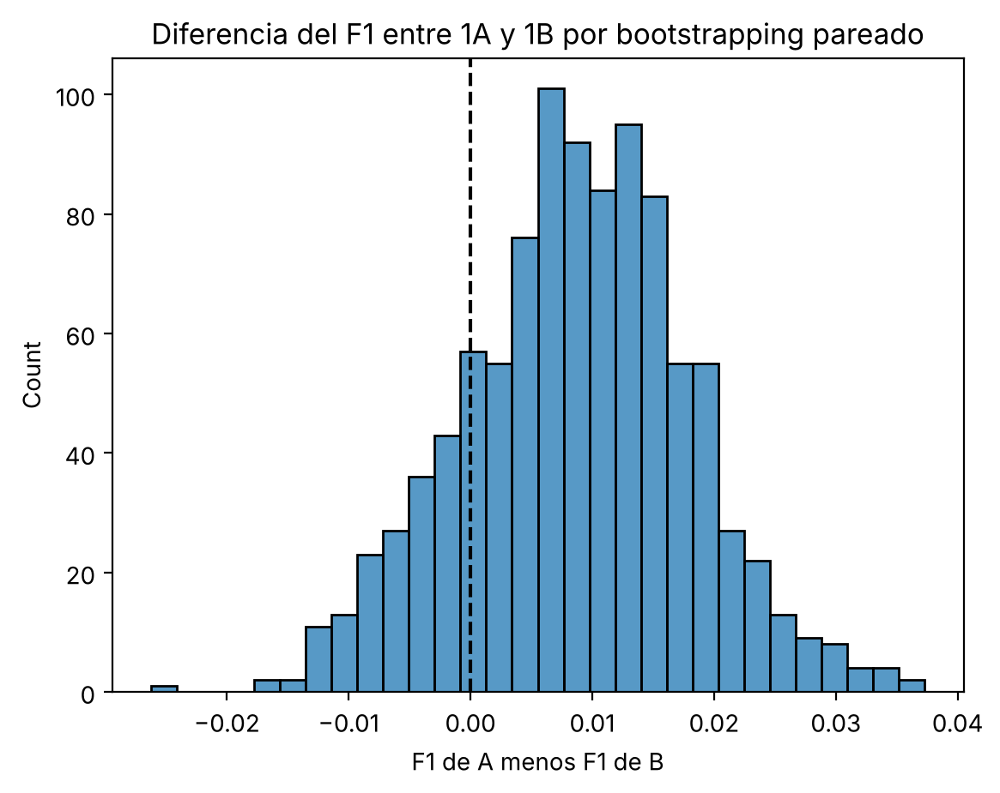

Prueba t pareada de Exactitud: A = 0.825, B = 0.818, t = 1.61, p valor = 0.1078
Prueba t pareada de Recall: A = 0.666, B = 0.671, t = -0.41, p valor = 0.6836
McNemar con todos los clientes
B acierta  False  True 
A acierta              
False        314     36
True          51   1599
chi2 = 2.25, p valor = 0.1334
McNemar con clientes que abandonaron
B acierta  False  True 
A acierta              
False        123     13
True          11    260
chi2 = 0.04, p valor = 0.8383


In [59]:
print("Configuración 1: A es 1A y B es 1B")
comparar_pareado( "1A", "1B")

Configuración 2: A es 2A y B es 2B


           diferencia A menos B  IC 2,5  IC 97,5  p bootstrapping  \
métrica                                                             
F1                      -0.0630 -0.0995  -0.0255              0.0   
Precisión                0.1499  0.1046   0.1933              0.0   
Recall                  -0.2236 -0.2597  -0.1829              0.0   

           el intervalo excluye 0  diferencia relevante  
métrica                                                  
F1                           True                  True  
Precisión                    True                  True  
Recall                       True                  True  


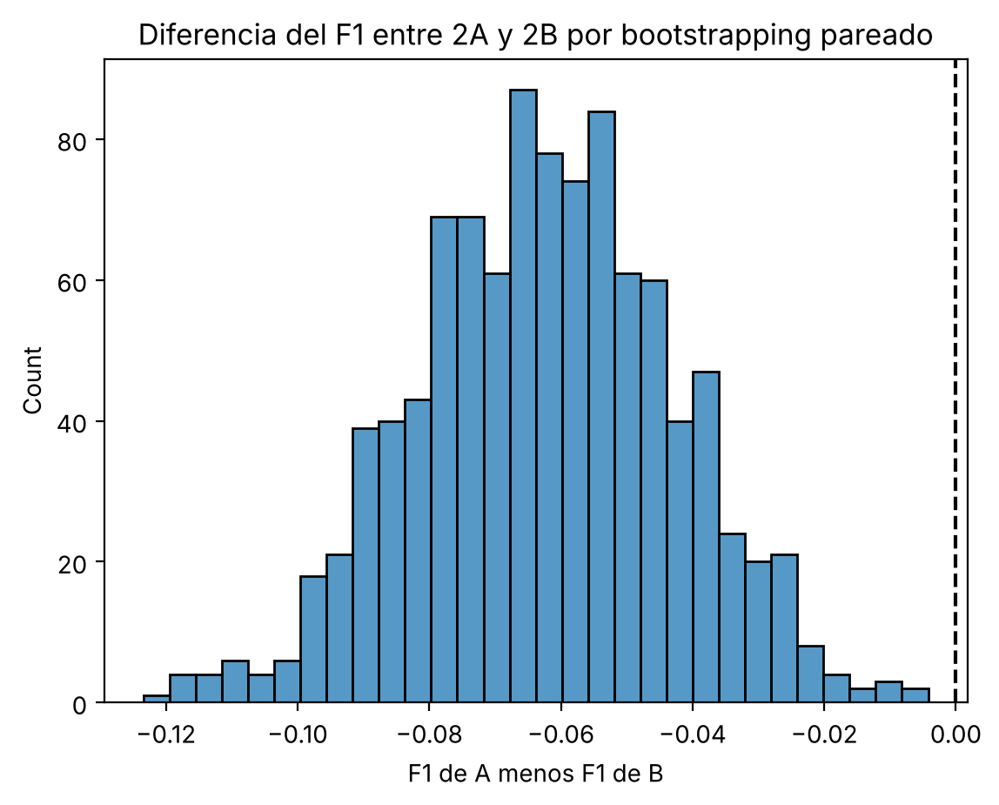

Prueba t pareada de Exactitud: A = 0.850, B = 0.825, t = 3.20, p valor = 0.001378
Prueba t pareada de Recall: A = 0.442, B = 0.666, t = -10.81, p valor = 4.054e-24
McNemar con todos los clientes
B acierta  False  True 
A acierta              
False        208     93
True         142   1557
chi2 = 9.80, p valor = 0.001741
McNemar con clientes que abandonaron
B acierta  False  True 
A acierta              
False        136     91
True           0    180
chi2 = 89.01, p valor = 3.926e-21


In [60]:
print("Configuración 2: A es 2A y B es 2B")
comparar_pareado("2A","2B")

Se usa una prueba pareada dado que los dos modelos de cada configuración se aplican a los mismos clientes del conjunto de prueba, y la comparación se hace cliente por cliente. La precisión y el F1 se comparan solo con bootstrapping dado que son razones sobre subconjuntos de clientes y no un promedio de un valor por ciente, así que la prueba t no aplica. La exactitud y el recall sí son promedios de un valor por cliente, 1 si acierta y 0 si no.

Configuración 1, modelos 1A y 1B. Las diferencias, son pequeñas y no significativas. El F1 difiere en 0,008, con intervalo de menos 0,010 a 0,028 y p valor de 0,352. La precisión difiere en 0,017, con intervalo de menos 0,001 a 0,038 y p de 0,064, y el recall en menos 0,005, con p de 0,766. Todos los intervalos contienen el 0 y ninguna diferencia llega al umbral relevante de 0,02, aunque la de precisión, con 0,017, queda cerca. La prueba t pareada da lo mismo, con p de 0,108 en la exactitud y 0,684 en el recall. McNemar tampoco encuentra diferencia: con todos los clientes, A acierta solo en 51 y B solo en 36, con p de 0,133, y entre los que abandonan, A acierta solo en 11 y B solo en 13, con p de 0,838. Las derivadas no mjoran al Random Forest.

Configuración 2, modelos 2A y 2B. Aquí las diferencias son claras. El F1 del árbol es 0,063 menor que el del bosque, con intervalo de menos 0,100 a menos 0,026, y un p valor de bootstrapping menor que 0,001. La precisión del árbol es 0,150 mayor y el recall es 0,224 menor, también con intervalos que excluyen el 0. Las tres diferencias superan el umbral relevante de 0,02. La prueba t pareada de la exactitud da una ventaja del árbol, 0,850 contra 0,825, con p de 0,0014, y la del recall da 0,442 contra 0,666, con p menor que 1e menos 20. McNemar con todos los clientes da que A acierta solo en 142 y B solo en 93, con p de 0,0017. Con los que abandonan, A acierta solo en 0 y B solo en 91, con p menor que 1e menos 20: el bosque detecta todos los abandonos que detecta el árbol y 91 más.

Esto resuelve la duda de la sección anterior. Los intervalos por separado se superponían un poco, pero la prueba pareada, que usa a los mismos clientes, sí detecta la diferencia. No es contradicción: el intervalo pareado de la diferencia es más angosto dado que quita la variación que es común a los dos modelos. La exactitud tiene el efecto contrario al F1 porque el árbol acierta más con los clientes que se quedan, que son la mayora.

Una diferencia significativa no siempre le importa al banco. Con más clientes se detectan diferencias muy pequeñas, por eso se fijó un umbral relevante de 0,02, y la decisión de fondo depende del valor en dinero de cada tipo de error, que se calcula en la sección 5.

## 4. Análisis cualitativo: interpretabilidad

Ayudas usadas: coeficientes de la regresión logística, función de predicción para interpretar, gráfico ICE, LIME, valores SHAP y gráficos SHAP, de la Práctica 5.

El modelo que se interpreta es el de mayor F1 de validación entre los dos de la configuración 2. Para el comportamiento global se usan las curvas ICE y el diagrama de enjambre de SHAP. Para las predicciones individuales se toman tres clientes del conjunto de prueba, según lo que hace ese modelo: un abandono bien detectado, un abandono que no se detectó y una falsa alarma. Cada uno se explica con LIME y con la cascada de SHAP. Estas técnicas trabajan con las variables originales, antes de escalar y antes de calcular las derivadas, y por eso se construye una función de predicción que hace todo por dentro.

In [61]:
modelo_final_nombre = tabla_cuatro.loc[["2A", "2B"], "F1 validación"].idxmax()
modelo_final, conjunto_final = cuatro[modelo_final_nombre]

columnas_final = columnas_conjunto[conjunto_final]
print("Modelo que se interpreta:", modelo_final_nombre, "que es", descripcion[modelo_final_nombre])

Modelo que se interpreta: 2B que es Random Forest con variables originales


### 4.1 Coeficientes de la regresión logística como referencia

                  coeficiente  razón de odds
active_member          -0.422          0.656
gender_Male            -0.241          0.786
credit_score           -0.055          0.946
products_number        -0.034          0.966
tenure                 -0.025          0.975
credit_card            -0.014          0.987
country_Spain           0.019          1.019
estimated_salary        0.022          1.023
balance                 0.168          1.183
country_Germany         0.288          1.334
age                     0.728          2.071


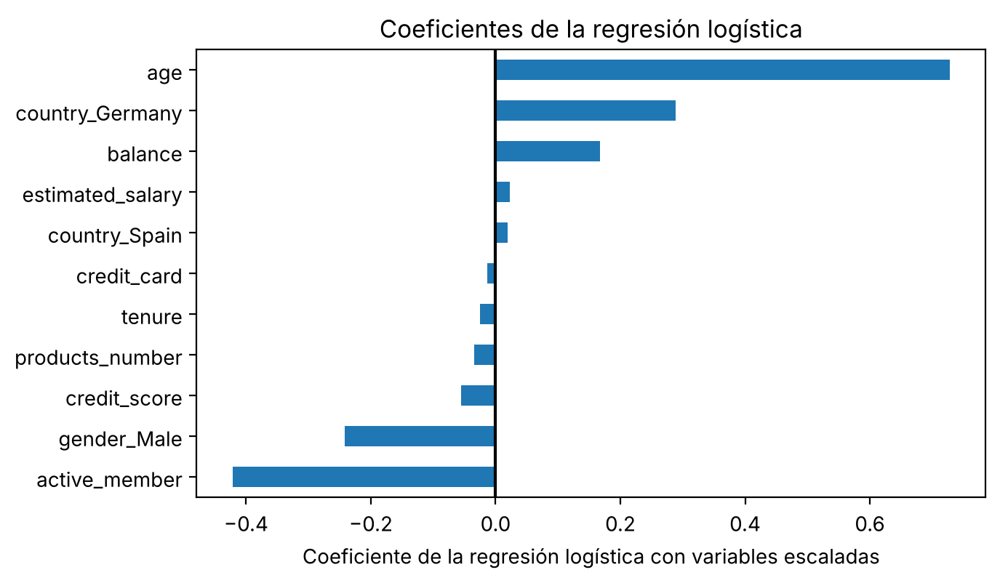

In [62]:
#coeficientes de la regresión logística con las variables escaladas
coeficientes = pd.Series(modelo_lr.coef_[0], index=variables_originales).sort_values()
odds = pd.DataFrame({"coeficiente": coeficientes, "razón de odds": np.exp(coeficientes)})
print(odds.round(3))

coeficientes.plot(kind="barh",figsize=(7, 4))
plt.axvline(0,color="k")

plt.xlabel("Coeficiente de la regresión logística con variables escaladas")
plt.title("Coeficientes de la regresión logística")
plt.show()

La regresión logística, sirve de referencia dado que sus coeficientes se leen directamente. Con variables escaladas, el coeficiente es el cambio en el logaritmo de las odds por cada desviación estándar de la variable. La edad es la más grande, con 0,728 y una razón de odds de 2,07: cada desviación estándar más de edad, unos 10 años, multiplica por 2 las odds de abandono, manteniendo lo demás igual. Le siguen country_Germany con 0,288 y odds de 1,33, y balance con 0,168 y 1,18. En sentido contrario están active_member con menos 0,422 y odds de 0,66, y gender_Male con menos 0,241 y odds de 0,79. credit_score, tenure, credit_card, country_Spain y estimated_salary están cerca de 0.

Llama la atención que products_number tenga un coeficiente de solo menos 0,034, cuando es la vaiable con la relación más fuerte en las pruebas. Es lo esperado: la relación no es lineal, con el mínimo en 2 productos y valores altos con 1, 3 y 4, y un modelo lineal solo puede ajustar una pendiente y esa pendiente promedia las dos direcciones. Los árboles sí la capturan, como se ve en las curvas ICE y en SHAP. Estos coeficientes son asociaciones condicionales a las otras variables del modelo y no efectos causales.

### 4.2 Función de predicción

In [63]:
columnas_base = variables_originales

def predecir_abandono(X):
    X = pd.DataFrame(X, columns=columnas_base)
    if conjunto_final == "ampliado":
        X = construir_derivadas(X)
    X_escalado= pd.DataFrame(escaladores[conjunto_final].transform(X[columnas_final]), columns=columnas_final)
    return probabilidades(modelo_final, X_escalado )

# la funcón tiene que dar lo mismo que el modelo con los datos ya escalados
print(np.allclose(predecir_abandono(X_test), probabilidades(modelo_final, X_esc[conjunto_final]["test"]),atol=1e-5))

True


### 4.3 Curvas ICE: comportamiento global

In [64]:
from sklearn.base import BaseEstimator, ClassifierMixin

# envoltura para que PartialDependenceDisplay pueda usar la funcion de pedicción
class ClasificadorDesdeFuncion(ClassifierMixin, BaseEstimator):
    def __init__(self, funcion=None):
        self.funcion =funcion
    def fit(self,X, y=None):
        self.classes_ = np.array([0, 1])
        return self
    def predict_proba( self,  X):
        p = self.funcion(X)
        return np.column_stack([1 - p, p])
    def predict(self, X):
        return (self.funcion(X) >= 0.5).astype( int)

clasificador_final = ClasificadorDesdeFuncion(predecir_abandono).fit(X_train)

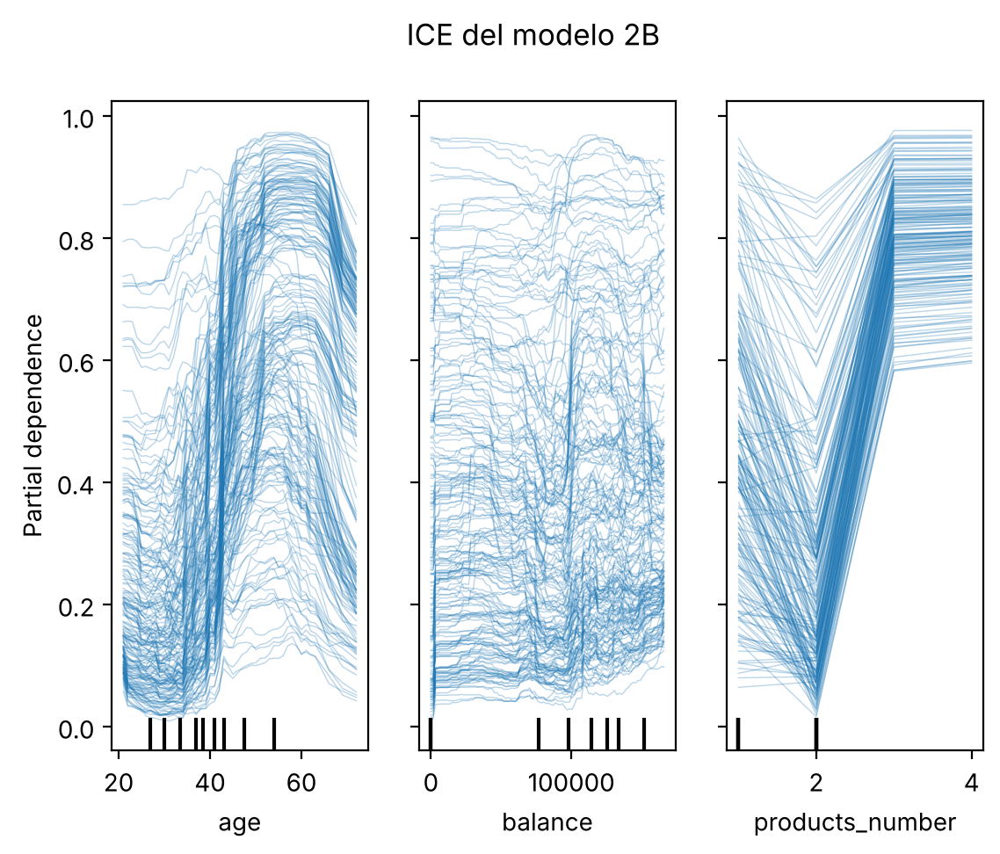

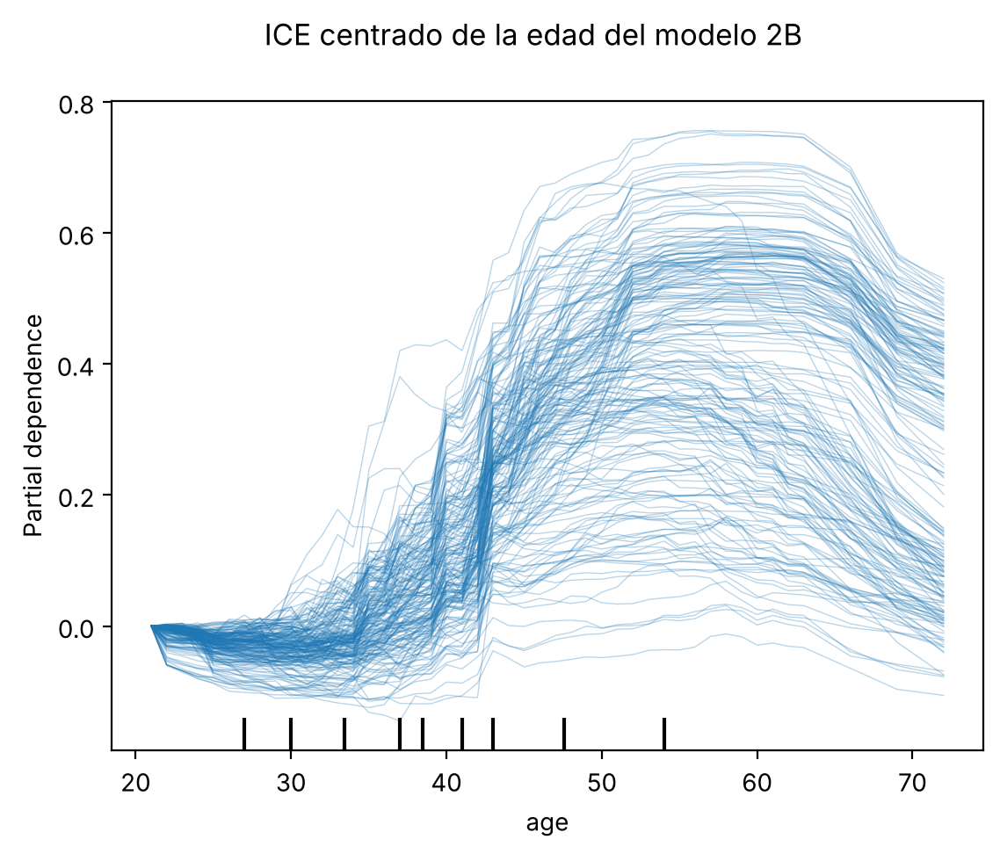

In [65]:
from sklearn.inspection import PartialDependenceDisplay

# muestra de 200 clients del conjunto de prueba
X_muestra = X_test.sample(200,random_state=42).astype(float)

display = PartialDependenceDisplay.from_estimator(clasificador_final, X_muestra, ["age", "balance", "products_number"],
                                                  kind="individual")
display.figure_.suptitle("ICE del modelo " + modelo_final_nombre)
plt.show()

# ICE centrado en el primer valor de la edad
display = PartialDependenceDisplay.from_estimator(clasificador_final, X_muestra,["age" ], kind="individual", centered=True)
display.figure_.suptitle("ICE centrado de la edad del modelo " + modelo_final_nombre)
plt.show()

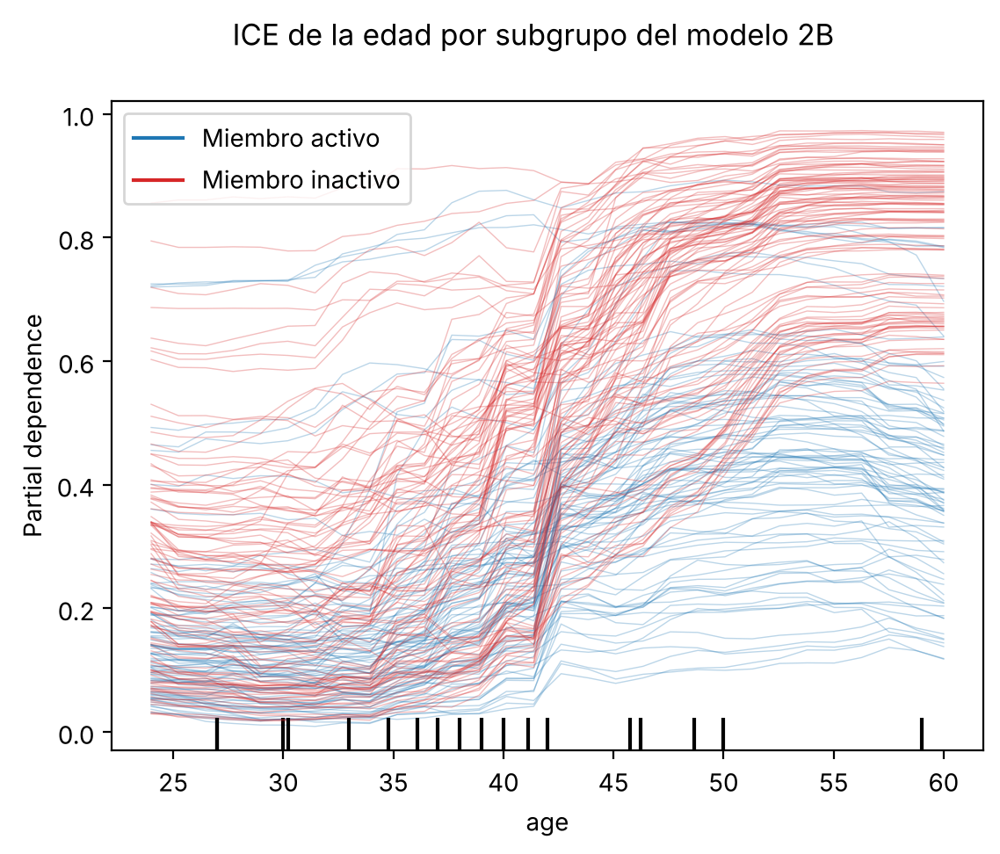

In [66]:
#ICE de la edad por grupo, activos e inactivos
from matplotlib.lines import Line2D

columna= "age"
grupo = X_muestra["active_member"]== 1
rejilla = { X_muestra.columns.get_loc( columna):
            np.linspace(X_muestra[columna].quantile(0.05), X_muestra[columna].quantile( 0.95),30)}

display= PartialDependenceDisplay.from_estimator(
    clasificador_final,  X_muestra[grupo], [columna],kind="individual", custom_values=rejilla,
    ice_lines_kw={"color": "tab:blue", "alpha": 0.3})
PartialDependenceDisplay.from_estimator(
    clasificador_final, X_muestra[~grupo],[columna], kind="individual",custom_values=rejilla,
    ax=display.axes_, ice_lines_kw={ "color": "tab:red", "alpha": 0.3})
display.axes_[0, 0].legend(handles=[Line2D([], [], color="tab:blue",label="Miembro activo"),
                                    Line2D([], [],color="tab:red", label="Miembro inactivo")])
display.figure_.suptitle("ICE de la edad por subgrupo del modelo " + modelo_final_nombre )
plt.show()

Las curvas ICE muestran qué pasa con la probabilidad que pedice el Random Forest cuando solo se cambia una variable de un cliente y las demás se dejan quietas. Cada línea es un cliente de la muestra de 200.

En la edad, la probabilidad es baja hasta cerca de los 40 años, sube de golpe entre los 41 y 42 años, se mantiene alta hasta los 60 ypocos años y vuelve a bajar después de los 65. El salto tan abrupto en los 41 a 42 años viene de que el bosque corta la variable en ese punto, y es un patrón del modelo aprendido. Las curvas tienen una forma parecida pero a distinta altura. Después de los 65 hay pocos clientes y la bajada es menos confiable.

En products_number, los clientes con 2 productos tienen la probabilidad más baja, cerca de 0 a 0,25. Con 1 producto la probabilidad es intermedia y con mucha dispersión, y con 3 y 4 productos salta a un rango de 0,6 a 0,97. Es la forma que ya se veía en los datos y que la regresión logística no capta. En balance las líneas son irregulares y se mueven poco, así que el efecto es débil. La curva centrada de la edad parte de 0 en todos los clientes y muestra que el aumento entre los 35 y los 45 años no es igual para todos: en algunos clientes la probabilidad sube cerca de 0,1 y en otros más de 0,7. Es decir que el efecto de la edad depende de las otras variables del cliente, y esa interacción no aparece en una regresión logística.

En el subgrupo, los clientes inactivos, en rojo, están por encima de los activos, en azul, en casi todas las edades. Las dos curvas suben por la edad en el mismo punto, así que la edad actúa igual en los dos grupos y lo que cambia es el nivel. Después de los 45 años la distancia es mayor, con los inactivos hasta cerca de 0,9 y los activos entre 0,2 y 0,8. Esto es lo que se esperaría si la inactividad y la edad se sumaran en el efecto, y no se puede afirmar más con una muestra de 200 clientes.

### 4.4 Valores SHAP: explicación global

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



PermutationExplainer explainer:   2%|▏         | 5/300 [00:00<?, ?it/s]


PermutationExplainer explainer:   2%|▏         | 7/300 [00:13<05:19,  1.09s/it]


PermutationExplainer explainer:   3%|▎         | 8/300 [00:15<07:23,  1.52s/it]


PermutationExplainer explainer:   3%|▎         | 9/300 [00:18<08:50,  1.82s/it]


PermutationExplainer explainer:   3%|▎         | 10/300 [00:20<09:46,  2.02s/it]

... (289 outputs left out)


PermutationExplainer explainer: 100%|██████████| 300/300 [11:44<00:00,  2.21s/it]


PermutationExplainer explainer: 301it [11:46,  2.23s/it]                         


PermutationExplainer explainer: 301it [11:46,  2.39s/it]

0.9237059144583669 0.9237059144583672
Valor base: 0.3061667682865229


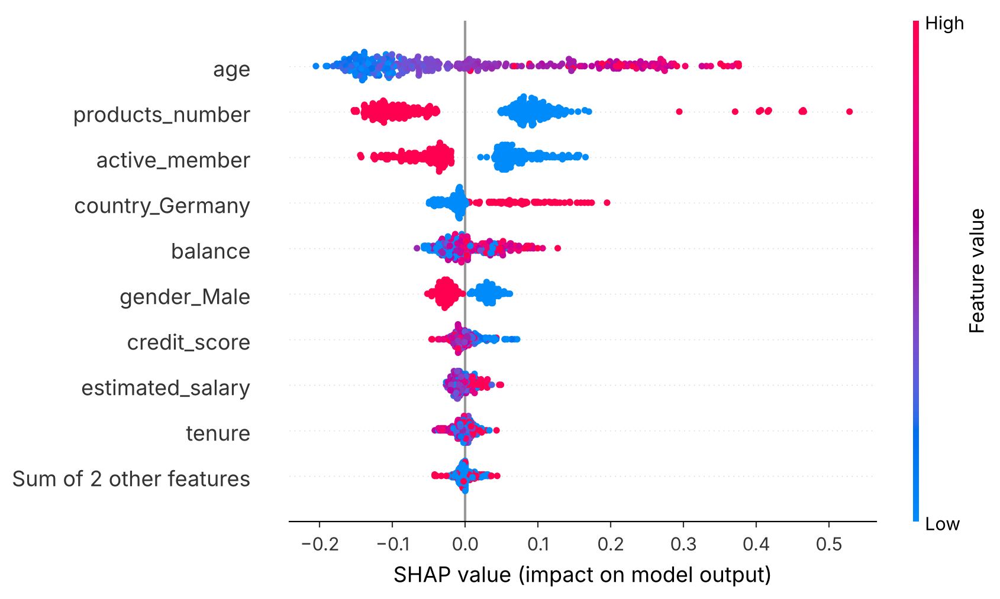

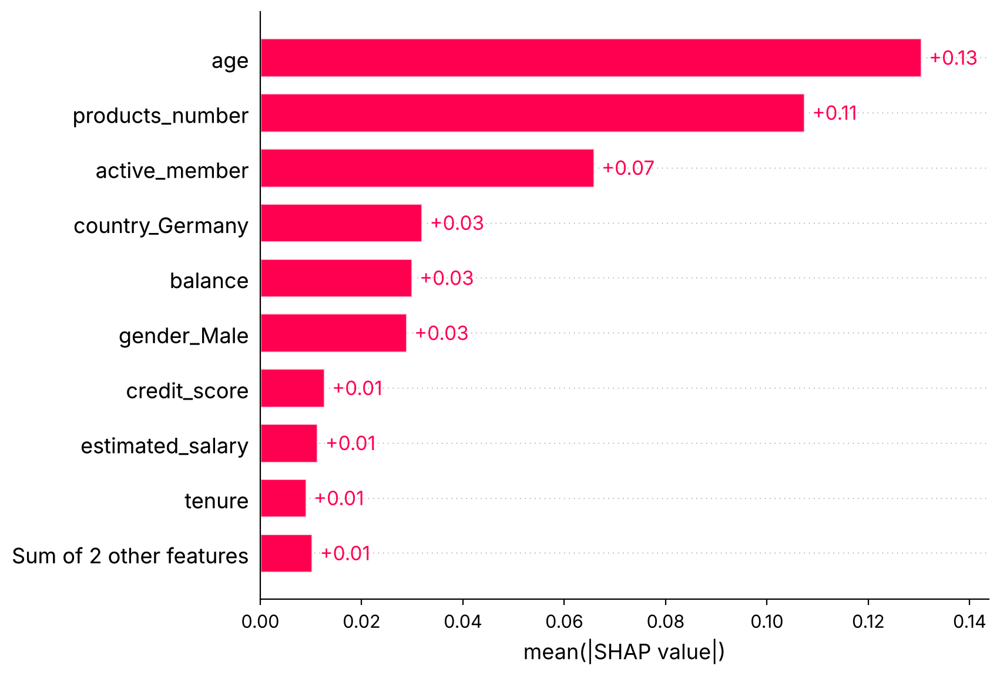

In [67]:
import shap

X_fondo= X_train.sample(100, random_state=42)
X_muestra_shap = X_test.sample(300,random_state=42)

#explicador agnóstico con la función de predicción
explicador = shap.Explainer(predecir_abandono, X_fondo)
valores = explicador(X_muestra_shap)

# comprobar la aditividad, el valor base más la suma de SHAP tiene que dar la predicción
i =0
print(valores.base_values[i] + valores.values[i].sum(), predecir_abandono(X_muestra_shap.iloc[[i]])[0])

print("Valor base:", valores.base_values[0])

shap.plots.beeswarm(valores)
shap.plots.bar(valores)

El diagrama de enjambre ordena las variables por su importancia promedio en las predicciones del Random Forest. Cada punto es un cliente, el color indica si el valor de la variable es alto o bajo y la posición horizontal indica cuánto sube o baja la probabilidad predicha frente al valor base de 0,306. El gráfico de barras, da el promedio del valor absoluto.

La edad es la más importante, con un promedio de 0,13, seguida de products_number con 0,11 y active_member con 0,07. Luego están country_Germany, balance y gender_Male, cada uno con 0,03, y credit_score, estimated_salary, tenure y las dos restantes con 0,01.

En la edad, los valores altos suben la probabilidad hasta cerca de 0,38 y los bajos la bajan hasta cerca de menos 0,2. En products_number se ven tres grupos: 1 producto suma cerca de 0,09, 2 productos resta cerca de 0,12, y los pocos clientes con 3 o 4 productos suman entre 0,3 y 0,5. Los clientes inactivos suman y los activos restan. Alemania suma hasta 0,2 y los demás países casi no cambian nada. Las mujeres suman y los hombres restan. Un balance alto suma un poco. credit_score, estimated_salary y tenure están alrededor de 0.

El orden coincide con la regresión logística en lo principal, con la edad primero, y se diferencia en que el bosque pone el número de productos segundo, algo que la regresión logística no veía por la no linealidad. Estas importancias muestran qué usa el modelo y no qué causa el abandono.

### 4.5 Tres predicciones individuales: LIME y cascada de SHAP

In [68]:
# casos del conjunto de prueba según el modelo que se interpreta
pred_final = clases(modelo_final, X_esc[conjunto_final][ "test"])

idx_vp = np.where((y_test_arr == 1) & (pred_final== 1 ))[0][0]

idx_fn = np.where((y_test_arr== 1) & (pred_final == 0))[0][ 0]
idx_fp= np.where((y_test_arr == 0) & (pred_final == 1))[0][0]
casos = {"Verdadero positivo": idx_vp, "Falso negativo": idx_fn,"Falso positivo": idx_fp }

X_casos =X_test.iloc[list(casos.values())]
resumen_casos = X_casos.copy()
resumen_casos.insert(0, "caso",list(casos.keys()))
resumen_casos["churn real"]=y_test_arr[list(casos.values())]
resumen_casos["probabilidad de abandono"]= predecir_abandono(X_casos)
resumen_casos.T

,7144,2513,8247
caso,Verdadero positivo,Falso negativo,Falso positivo
credit_score,653.0,606.0,641.0
age,47.0,37.0,40.0
tenure,6.0,6.0,7.0
balance,0.0,82373.94,0.0
products_number,1.0,1.0,1.0
credit_card,1,0,1
active_member,0,0,0
estimated_salary,50695.93,172526.9,126996.67
country_Germany,0,0,0


Verdadero positivo . Probabilidad del modelo: 0.804
[('age > 44.00', 0.3371669502287165), ('products_number <= 1.00', 0.14137717376211253), ('active_member=0', 0.13571353122519444), ('gender_Male=1', -0.060696294941177426), ('country_Germany=0', -0.04758219746425548), ('balance <= 0.00', -0.030780614786169523)]
Predicción del sustituto: [0.70116765] R2 local: 0.5358588420772019


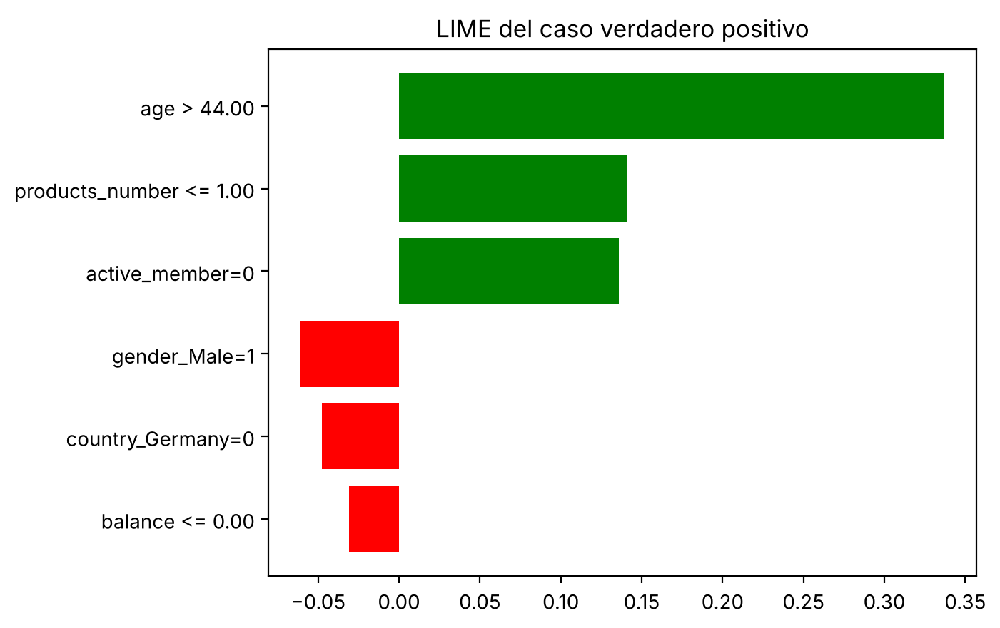

Falso negativo . Probabilidad del modelo: 0.321
[('products_number <= 1.00', 0.13673472811143667), ('32.00 < age <= 37.00', -0.1341912798365788), ('active_member=0', 0.13064156707740474), ('country_Germany=0', -0.060083609601049325), ('gender_Male=1', -0.05163603021199207), ('estimated_salary > 149669.93', 0.024308873176628817)]
Predicción del sustituto: [0.37048012] R2 local: 0.24860694533278815


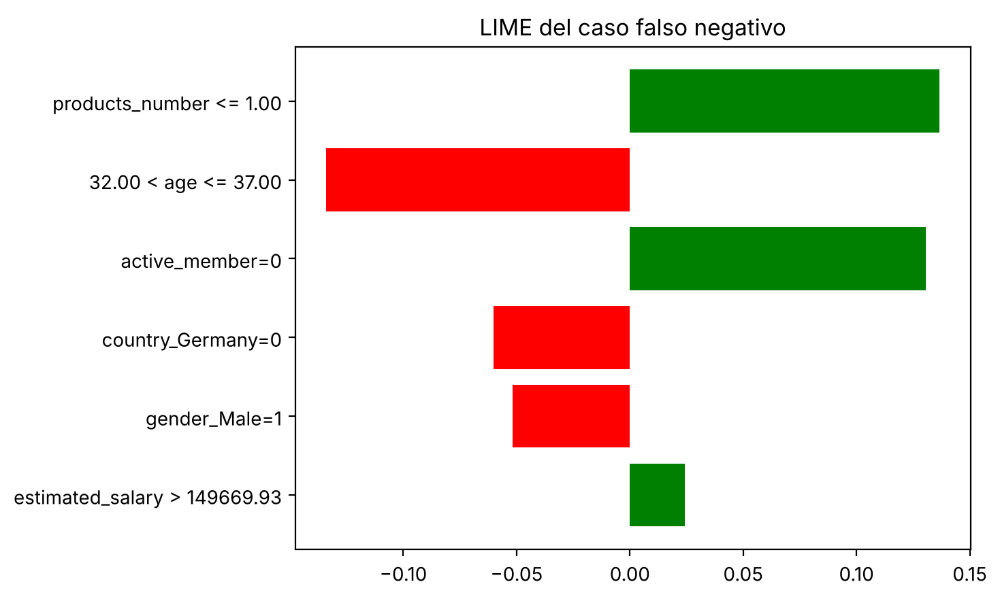

Falso positivo . Probabilidad del modelo: 0.622
[('products_number <= 1.00', 0.14446923097702064), ('active_member=0', 0.13086999058197668), ('country_Germany=0', -0.04865465415226242), ('gender_Male=0', 0.04519368404048341), ('37.00 < age <= 44.00', 0.023120129015004307), ('balance <= 0.00', -0.022739663531712806)]
Predicción del sustituto: [0.5103442] R2 local: 0.19133676298375724


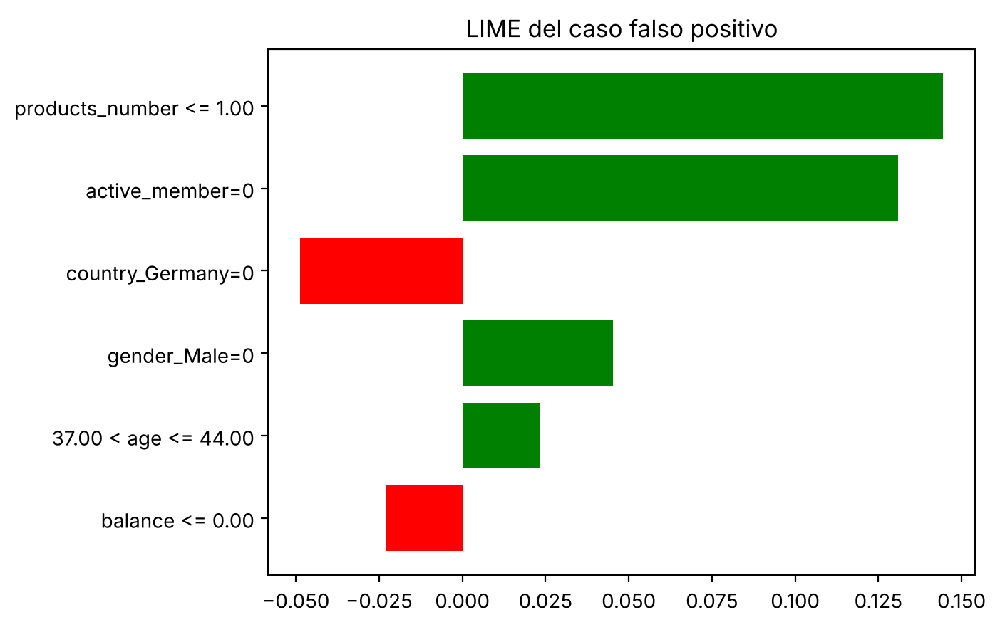

In [69]:
from lime.lime_tabular import LimeTabularExplainer

columnas_binarias_modelo=["credit_card","active_member","country_Germany", "country_Spain", "gender_Male"]
indices_categoricas =[columnas_base.index(c) for c in columnas_binarias_modelo]

explicador_lime = LimeTabularExplainer(X_train.to_numpy(), feature_names=columnas_base,
                                       class_names=["No abandona", "Abandona"], mode="classification",
                                       categorical_features=indices_categoricas,  random_state=42)

for nombre_caso, idx in casos.items():
    x = X_test.iloc[idx]
    explicacion = explicador_lime.explain_instance(x.to_numpy(), clasificador_final.predict_proba,
                                                   num_features=6, num_samples=5000)
    print(nombre_caso, ". Probabilidad del modelo:",  round( predecir_abandono(x.to_frame().T)[ 0], 3))
    print(explicacion.as_list())
    print("Predicción del sustituto:",  explicacion.local_pred, "R2 local:", explicacion.score)
    explicacion.as_pyplot_figure()
    plt.title("LIME del caso " + nombre_caso.lower())
    plt.show()

Los tres clientes de prueba viven en Francia, tienen un solo producto y no son activos. Se parecen mucho entre sí y por eso muestran bien lo que hace el modelo con perfiles de riesgo parecidos. El verdadero positivo, es un hombre de 47 años, con saldo 0 y probabilidad de 0,804. El falso negativo, es un hombre de 37 años, con saldo de 82.374 y probabilidad de 0,321, es decir que el modelo no lo marcó. El falso positivo es una mujer de 40 años, con saldo 0 y probabilidad de 0,622, que el modelo marcó pero no abandonó.

En el verdadero positivo, LIME da más peso a que la edad sea mayor de 44, con 0,34, seguido de tener un solo producto, con 0,14, y de ser inactivo, con 0,14. Ser hombre, no ser alemán y tener saldo 0 restan un poco. En el falso negativo, el producto único y la inactividad suman, con 0,14 y 0,13, pero tener entre 32 y 37 años resta 0,13 y compensa casi todo. En el falso positivo, el producto único y la inactividad suman 0,14 y 0,13, y la edad entre 37 y 44 aporta poco, 0,02.

Hay que leer esto con cuidado. El R2 local del sustituto lineal es de 0,54 en el primer caso, 0,25 en el segundo y 0,19 en el tercero. En los dos últimos el modelo lineal local explica poco de la predicción, así que esas explicaciones son aproximadas. Aun así, lo que muestran coincide con SHAP.

Verdadero positivo
Valor base más suma de SHAP: 0.8038754726596136


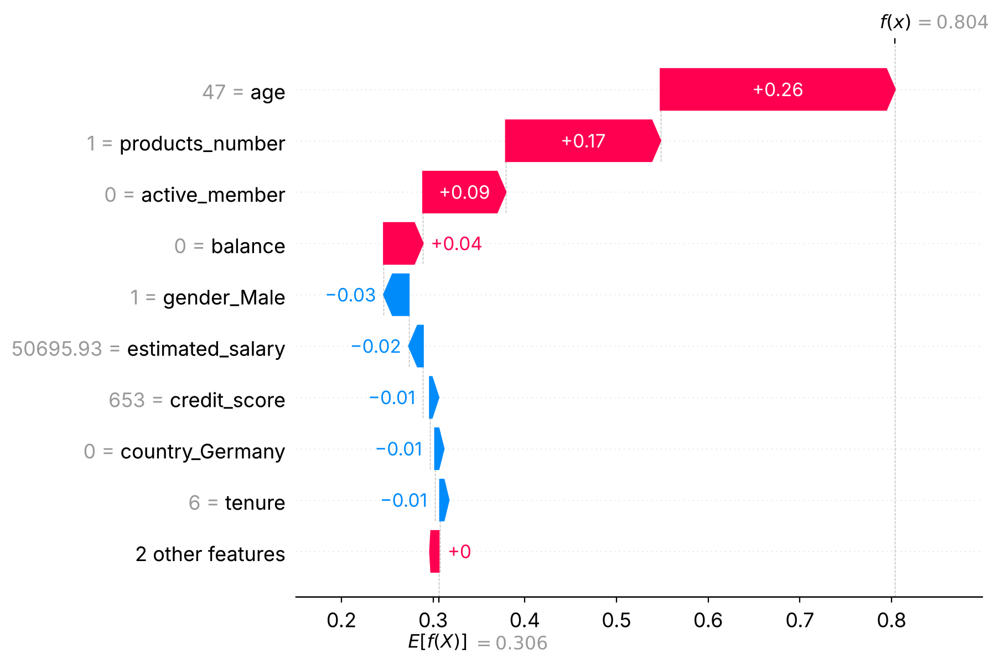

Falso negativo
Valor base más suma de SHAP: 0.32111627396556414


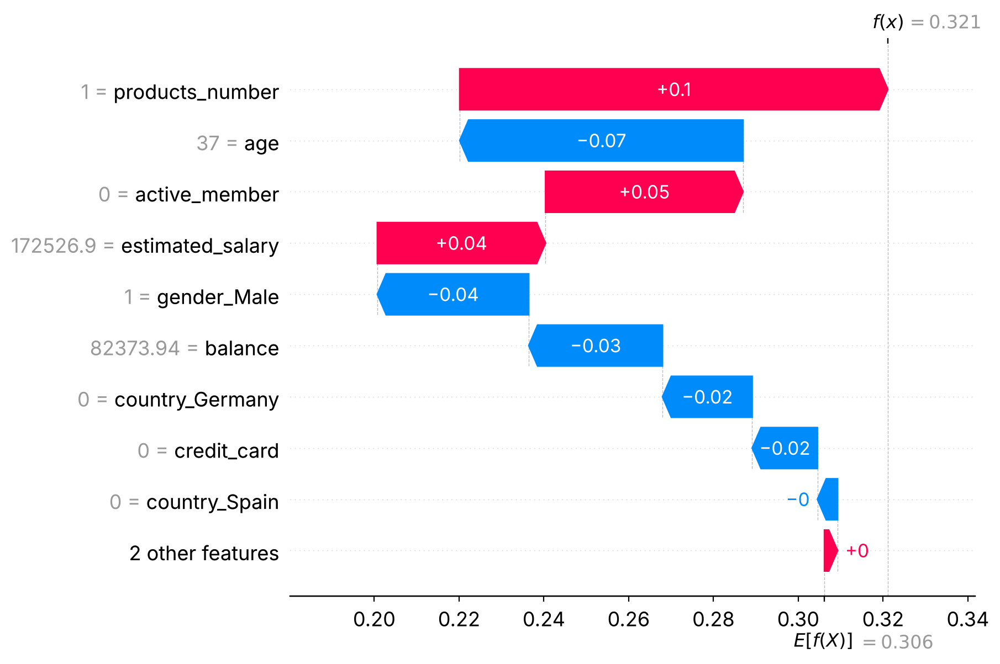

Falso positivo
Valor base más suma de SHAP: 0.6220277278532382


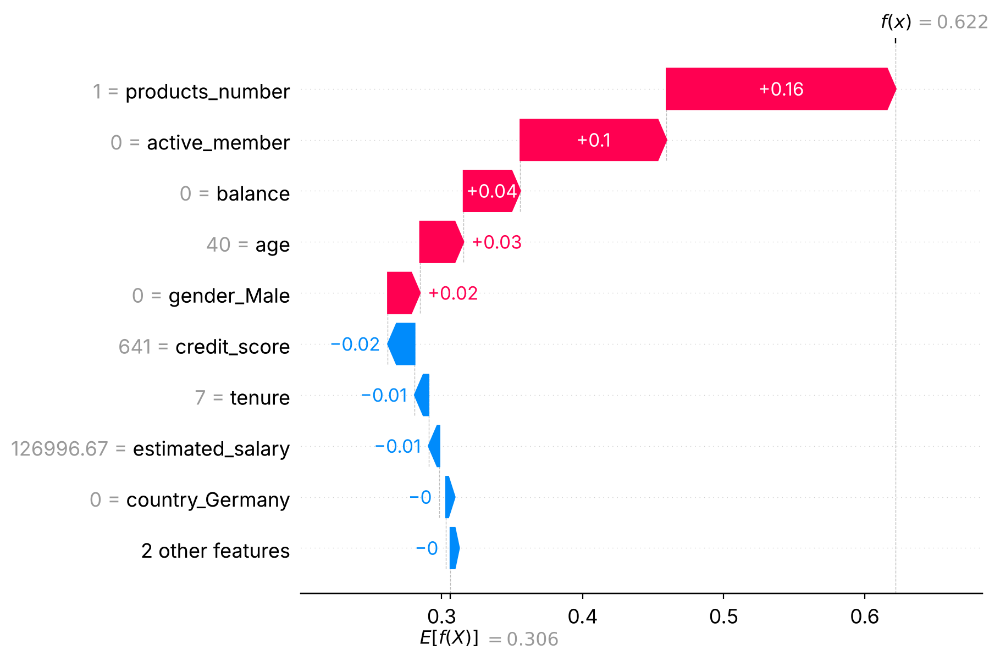

In [70]:
# cascada de SHAP de los mismos tres clintes
valores_casos = explicador(X_casos)

for k, nombre_caso in enumerate( casos):
    print(nombre_caso)
    print("Valor base más suma de SHAP:", valores_casos.base_values[k] + valores_casos.values[k].sum())
    shap.plots.waterfall(valores_casos[k])

La cascada de SHAP del Random Forest parte del valor base de 0,306, que es la probabilidad promedio que predice el modelo, y suma la contribución de cada variable hasta llegar a la predicción de cada cliente. Las sumas coinciden con las probabilidades del modelo.

Verdadero positivo, probabilidad de 0,804. La edad de 47 años suma 0,25, tener un solo producto suma 0,17, ser inactivo suma 0,09 y el saldo 0 suma 0,04. Ser hombre resta 0,03 y el salario de 50.696 resta 0,02. El modelo lo detecta porque varias señales deriesgo se acumulan.

Falso negativo, probabilidad de 0,321. Tener un solo producto suma 0,10, ser inactivo suma 0,05 y el salario alto de 172.527 suma 0,04. Pero la edad de 37 años resta 0,07, ser hombre resta 0,03, el saldo de 82.374 resta 0,03 y no ser alemán resta 0,02. El resultado, queda por debajo de 0,5 y el cliente no se marca, aunque se fue. Este tipo de error aparece cuando el cliente se parece más a los que se quedan en la variable que el modelo pesa más, la edad.

Falso positivo, probabilidad de 0,622. Tener un solo producto suma 0,16, ser inactivo suma 0,10, el saldo 0 suma 0,04, la edad de 40 años suma 0,03 y ser mujer suma 0,02. Casi no hay nada que reste. Era un cliente con el perfil de riesgo típico que no se fue, y es difícil que un modelo lo evite, dado que se parece mucho a los que sí abandonan.

En los tres casos coinciden LIME y SHAP en que el producto único y la inactividad suman, y la edad es lo que mássepara un caso de otro. Son explicaciones de cómo llegó el modelo a cada predicción y no pruebas de por qué se fue cada cliente.

## 5. Generación de valor

Ayudas usdas: clcular el impacto de un modelo y elegir el umbral con el impacto, de la Práctica 4, y la presentación demétricas avanzadas y generación de valor. Incluye el ROI, la fórmula de Provost, la fórmula simplificada, la fórmula de equilibrio, el punto de equilibrio y el recall mínimo para recuperar la inversión en k meses.

El escenario del taller es un banco de FinAlpes con 20.000 clientes. La deserción anual promedio de la banca minorista ronda el 15 por ciento, la campaña de retención convence solo al 30 por ciento de los clientes que se iban a ir y la oferta se le paga a todos los contactados, y el ingreso anual de un cliente activo está entre 500.000 y 900.000 pesos colombianos.

La matriz de costo y beneficio tiene cuatro casos, con V el valor anual del cliente que se retiene, c el costo de la oferta por cliente contactado y r la tasa de éxito de la oferta. Si el modelo acierta y el cliente se iba a ir, el banco lo contacta y lo retiene con probabilidad r. Por lo tanto, el valor es r por V menos c. Si el modelo da una falsa alarma, el banco paga c sin ganar nada, y el valor es menos c. Si el cliente se iba a ir y el modelo no lo detecta, el banco no gasta ni gana nada respecto a no usar el modelo, y el valor es 0. Si el cliente no se iba a ir y el modelo tampoco lo marca, el valor también es 0.

### 5.1 Supuestos explícitos y sus fuentes

El enunciado fija el número de clientes, la tasa de abandono, r y el rango de V. No da el costo por cliente contactado ni el costo de implementación del modelo y pide estimarlos con fuentes. Se construyen con fuentes externas recientes

Costo por cliente contactado: es la suma de dos partes, el costo de la oferta y el costo del canal. El enunciado no los da y se estiman con datos oficiales y de medios reconocidos que reportan datos oficiales. Todo queda en pesos colombianos, así que no hace falta convertir monedas.

Costo de la oferta: se define la oferta de retención como exonerar la cuota de manejo durante 6 meses, y su costo es el ingreso que el banco deja de cobrar. Noticias RCN, el 29 de julio de 2026, reportó con base en el reporte trimestral de productos de depósito de la Superintendencia Financiera que las cuotas de manejo van desde 0 hasta 44.030 pesos al mes, y que en cuentas de ahorro el Banco Itaú y el Banco Popular cobran entre 9.000 y 14.000 pesos, en `https://www.noticiasrcn.com/economia/cuota-de-manejo-bancos-mas-caros-y-gratuitos-1045068`. El reporte original está en la página de tarifas de la Superintendencia Financiera, `https://www.superfinanciera.gov.co/61279`. Se usan tres escenarios, 9.000 pesos al mes como bajo, 44.030 como alto y el punto medio como medio. La fórmula supone que c se paga por cada cliente contactado, así que c es un tope: en la práctica un dscuento solo lo paga el banco a quien lo acepta.

Costo del canal: es el tiempo de un agente de llamadas. El salario mínimo de 2026 es de 1.750.905 pesos y el auxilio de transporte de 249.095, segun el decreto transitorio 0159 del 19 de febrero de 2026 del Ministerio del Trabajo que reporta La República en `https://www.larepublica.co/economia/mintrabajo-publico-decreto-transitorio-que-mantiene-minimo-de-1-75-millones-en-2026-4331878`. Valora Analitik calculó que un trabajador con salario mínimo le cuesta al empleador unos 2.863.086 pesos al mes con aportes y prestaciones, en `https://www.valoraanalitik.com/cuanto-cuesta-a-una-empresa-un-trabajador-que-gana-el-salario-minimo/`. Se supone un agente con salario mínimo, 160 horas al mes y llamadas de 5 minutos.

Inversión: se estima como el costo del equipo durante el proyecto. El equipo es un científico de datos, un ingeniero de datos, un ingeniero de ML y medio líder de negocio durante 3 meses. El equipo y la duración son supuestos míos, porque no encontré una fuente confiable que dé la duración típica de un proyecto así en un banco. Por eso se prueban también duraciones de 2 y 6 meses. Los salarios salen del Observatorio Laboral para la Educación del Ministerio de Educación, que reporta el Ingreso Base de Cotización de recién graduados en múltiplos del salario mínimo. Para los graduados de 2021 la mediana fue de 4 a 4,5 salarios mínimos en maestría, de 3 a 3,5 en especialización y de 2,5 a 3 en Ingeniería de Sistemas, en `https://ole.mineducacion.gov.co/1769/articles-426952_recurso_1.pdf`. Son salarios de recién graduados, así que pueden quedase cortos para un equipo con experiencia. A esos salarios se les suman los aportes del empleador y las prestaciones que detallan Valora Analitik y Forbes Colombia en `https://forbes.co/2026/09/24/economia-y-finanzas/salario-minimo-2026-esto-cuesta-realmente-contratar-a-un-trabajador-en-colombia/`. No se incluyen nube, licencias ni contingencia, porque no encontré una fuente confiable de esos montos, y se supone que la integración y la capacitación hacen parte del trabajo del equipo. Esto puede subestimar la inversión.


In [71]:
n_clientes=20000                       #del enunciado
tasa_abandono = 0.15  # del enunciado, deserción promedio anual de la banca minorista
r =0.30                                 # del enunciado, la oferta convence al 30 por ciento de los que se iban
valores_V = {"bajo": 500_000, "medio": 700_000,  "alto": 900_000}   #del enunciado, ingreso anual entre 500.000 y 900.000
M =n_clientes * tasa_abandono / 12  # clientes que se van cada mes

In [ ]:
# costo de la oferta, exonerar la cuota de manejo 6 meses
cuota_mensual = {"bajo": 9_000, "medio": (9_000 + 44_030) / 2,  "alto": 44_030}    # supuesto

meses_exoneracion =6
costo_oferta = {escenario: cuota * meses_exoneracion for escenario, cuota in cuota_mensual.items()}

# costo del canal, llamada de 5 minutos de un agente con salario minio de 2026
costo_agente_mes =2_863_086   #lo que le cuesta al empleador por mes con aportes y prestaciones
horas_mes = 160                         # supuesto
minutos_llamada = 5                     #supuesto
costo_canal = costo_agente_mes / (horas_mes * 60)* minutos_llamada

#se usa el escenario medio de la oferta para los tres V
costo_contacto = {escenario: costo_oferta["medio"] + costo_canal for escenario in valores_V}   # supuesto
print("Costo de la oferta por escenario:",{k: round(v) for k,v in costo_oferta.items()})
print("Costo del canal por llamada:", round( costo_canal))
print("Costo por cliente contactado, escenario medio:", round(costo_contacto["medio"]))

Costo de la oferta por escenario: {'bajo': 54000, 'medio': 159090, 'alto': 264180}
Costo del canal por llamada: 1491
Costo por cliente contactado, escenario medio: 160581


In [ ]:
#inversión, lo que cuesta el equipo con salarios colombianos
SMMLV = 1_750_905
equipo = pd.DataFrame( {"rol": ["Científico de datos", "Ingeniero de datos","Ingeniero de ML",  "Líder de negocio"],
                       "dedicación": [1.0, 1.0, 1.0, 0.5],              # supuesto
                       "SMMLV bajo": [4.0,2.5, 2.5,  3.0],
                       "SMMLV alto": [4.5, 3.0, 3.0, 3.5] })
equipo[ "SMMLV medio"]= (equipo["SMMLV bajo"] + equipo["SMMLV alto"]) / 2

#aportes del empleador y prestaciones, pension caja ARL prima cesantias intereses y vacaciones
carga = 0.12 + 0.04 + 0.00522 + 0.0833 + 0.0833 + 0.01 + 0.0417

def inversion_total(columna,meses):
    mensual = (equipo["dedicación"] * equipo[columna] * SMMLV * (1 + carga)).sum()
    return mensual * meses

inversion = inversion_total( "SMMLV medio", 3)                                  # supuesto
inversiones= {"base": inversion, "2 meses": inversion_total("SMMLV medio", 2 ), "6 meses": inversion_total("SMMLV medio", 6),
               "salarios bajos": inversion_total("SMMLV bajo",  3), "salarios altos": inversion_total("SMMLV alto",3)}
print(equipo.to_string(index=False))
print("Carga del empleador:", round(carga, 4))
print("Costo mensual del equipo:", round(inversion / 3))

print({k: round(v) for k, v in inversiones.items()})

                rol  dedicación  SMMLV bajo  SMMLV alto  SMMLV medio
Científico de datos         1.0         4.0         4.5         4.25
 Ingeniero de datos         1.0         2.5         3.0         2.75
    Ingeniero de ML         1.0         2.5         3.0         2.75
   Líder de negocio         0.5         3.0         3.5         3.25
Carga del empleador: 0.3835
Costo mensual del equipo: 27554937
{'base': 82664812, '2 meses': 55109875, '6 meses': 165329625, 'salarios bajos': 76305981, 'salarios altos': 89023644}


### 5.2 Valor esperado, fórmula simplificada y equilibrio

Los dos modelos son los de la configuración 2 de la sección 3: A es el mejor modelo básico y B es el mejor ensamble, entrenados con el conjunto de variables que ganó. Se usan las tasas de la matriz de confusión del conjunto de prueba, con umbral de decisión de 0,5, y se ponderan con la distribución previa del banco, que es el 15 por ciento de abandono, como en la fórmula de Provost. El beneficio mensual es el valor esperado por cliente multiplicado por el número de clientes y dividido entre 12, dado que la tasa de abandono es anual.

Además de los dos modelos, se calula una línea de referencia que es contactar a todos los clientes sin usar ningún modelo. Es la misma fórmula con recall de 1 y tasa de falsos positivos de 1, y sirve para saber si el modlo le gana a una campaña masiva.

In [74]:
from sklearn.metrics import confusion_matrix

def impacto(y_real, y_pred, V, c, tasa, r, n_clientes, inversion):
    vn, fp, fn, vp = confusion_matrix(y_real,  y_pred, labels=[0, 1]).ravel()
    tpr, fnr =vp / (vp + fn), fn / (vp + fn)  #probabilidad de acertar y de fallar en los positivos
    tnr,fpr= vn / (vn + fp ), fp / (vn + fp)          # probabilidad de acertar y de fallar en los negativos
    p_P, p_N = tasa, 1 - tasa                          # distribuciones previas

    #frmula de Provost
    b_vp, v_fp, v_fn, v_vn= r* V - c,  -c, 0, 0
    valor_esperado = p_P * (tpr* b_vp + fnr * v_fn)+ p_N * (tnr * v_vn + fpr* v_fp)
    beneficio_mensual = valor_esperado * n_clientes / 12

    #formula simplificada, a_hat es a menos 1 menos I por e con I igual a la precision
    contactados = p_P * tpr + p_N* fpr
    precision =tpr * p_P/ contactados if contactados > 0 else np.nan
    a, e =r * V - c,  r * V
    a_hat= a - (1 - precision)* e if contactados > 0 else np.nan
    contactados_mes= n_clientes * contactados / 12

    #fórmula del equilibrio y punto de equilibrio
    P_e= c / (r * V)
    mes_equilibrio = inversion / beneficio_mensual if beneficio_mensual> 0 else np.nan
    roi_12 = (12 * beneficio_mensual - inversion) / inversion
    return {"recall": tpr, "precisión ajustada": precision, "precisión de equilibrio": P_e,
            "valor esperado por cliente": valor_esperado, "a_hat por contacto": a_hat,
            "contactados por mes": contactados_mes, "beneficio mensual": beneficio_mensual,
            "mes de equilibrio": mes_equilibrio, "ROI a 12 meses": roi_12,
            "costo máximo por contacto": precision * r * V, "r mínima": c / (precision * V) if contactados > 0 else np.nan}

modelo_A, modelo_B = modelo_2A, modelo_2B

nombre_A, nombre_B ="A: "+ mejor_basico, "B: " + mejor_ensamble
X_val_S, X_test_S = X_esc[conjunto_elegido ]["val"], X_esc[conjunto_elegido]["test"]
prob_val= {nombre_A: probabilidades( modelo_A, X_val_S), nombre_B: probabilidades(modelo_B, X_val_S)}
prob_test ={nombre_A: probabilidades(modelo_A, X_test_S), nombre_B: probabilidades(modelo_B, X_test_S)}

#con umbral 0,5 la probabilidad da las mismas clases que predict salvo empates exactos
for nombre, modelo in [( nombre_A, modelo_A), (nombre_B,modelo_B)]:
    print(nombre, "clientes de prueba con clase distinta:",(clases(modelo, X_test_S)!= (prob_test[nombre] >= 0.5)).sum())

preds_test ={nombre: (prob >= 0.5).astype(int) for nombre, prob in prob_test.items()}
preds_test["Contactar a todos"]= np.ones(n_test, dtype=int)

filas =[]
for escenario,  V in valores_V.items():
    for nombre, y_p in preds_test.items():
        fila={ "escenario V": escenario, "V": V, "c": costo_contacto[escenario],"modelo": nombre}
        fila.update(impacto(y_test_arr,  y_p,  V, costo_contacto[escenario], tasa_abandono, r,n_clientes, inversion))
        filas.append(fila)
tabla_impacto = pd.DataFrame(filas)
pd.options.display.float_format = "{:,.3f}".format
tabla_impacto.set_index(["escenario V","modelo"] )

A: Árbol de decisión clientes de prueba con clase distinta: 0
B: Random Forest clientes de prueba con clase distinta: 0


V           c  recall  \
escenario V modelo                                             
bajo        A: Árbol de decisión  500000 160,581.191   0.442   
            B: Random Forest      500000 160,581.191   0.666   
            Contactar a todos     500000 160,581.191   1.000   
medio       A: Árbol de decisión  700000 160,581.191   0.442   
            B: Random Forest      700000 160,581.191   0.666   
            Contactar a todos     700000 160,581.191   1.000   
alto        A: Árbol de decisión  900000 160,581.191   0.442   
            B: Random Forest      900000 160,581.191   0.666   
            Contactar a todos     900000 160,581.191   1.000   

                                  precisión ajustada  precisión de equilibrio  \
escenario V modelo                                                              
bajo        A: Árbol de decisión               0.627                    1.071   
            B: Random Forest                   0.467                    1.071   
            Contactar a todos                  0.150                    1.071   
medio       A: Árbol de decisión               0.627                    0.765   
            B: Random Forest                   0.467                    0.765   
            Contactar a todos                  0.150                    0.765   
alto        A: Árbol de decisión               0.627                    0.595   
            B: Random Forest                   0.467                    0.595   
            Contactar a todos                  0.150                    0.595   

                                  valor esperado por cliente  \
escenario V modelo                                             
bajo        A: Árbol de decisión                  -7,042.534   
            B: Random Forest                     -19,393.115   
            Contactar a todos                   -138,081.191   
medio       A: Árbol de decisión                  -3,062.190   
            B: Random Forest                     -13,400.486   
            Contactar a todos                   -129,081.191   
alto        A: Árbol de decisión                     918.154   
            B: Random Forest                      -7,407.857   
            Contactar a todos                   -120,081.191   

                                  a_hat por contacto  contactados por mes  \
escenario V modelo                                                          
bajo        A: Árbol de decisión         -66,549.304              176.374   
            B: Random Forest             -90,594.844              356.774   
            Contactar a todos           -138,081.191            1,666.667   
medio       A: Árbol de decisión         -28,936.549              176.374   
            B: Random Forest             -62,600.306              356.774   
            Contactar a todos           -129,081.191            1,666.667   
alto        A: Árbol de decisión           8,676.206              176.374   
            B: Random Forest             -34,605.768              356.774   
            Contactar a todos           -120,081.191            1,666.667   

                                  beneficio mensual  mes de equilibrio  \
escenario V modelo                                                       
bajo        A: Árbol de decisión    -11,737,557.394                NaN   
            B: Random Forest        -32,321,857.606                NaN   
            Contactar a todos      -230,135,317.708                NaN   
medio       A: Árbol de decisión     -5,103,650.760                NaN   
            B: Random Forest        -22,334,142.618                NaN   
            Contactar a todos      -215,135,317.708                NaN   
alto        A: Árbol de decisión      1,530,255.874             54.020   
            B: Random Forest        -12,346,427.630                NaN   
            Contactar a todos      -200,135,317.708                NaN   

                                  ROI a 12 meses  costo máximo por contact

In [75]:
#comprobar que la fórmula simplificada y la de Provost dan lo mismo
mascara = tabla_impacto["a_hat por contacto"].notna()
chequeo = tabla_impacto["a_hat por contacto"] * tabla_impacto["contactados por mes"] - tabla_impacto["beneficio mensual"]
print("Diferencia máxima entre las dos fórmulas:",chequeo[mascara].abs().max())

Diferencia máxima entre las dos fórmulas: 2.9802322387695312e-08


Fuentes de los supuestos. El número de clientes, el 15% de abandono anual, la tasa de éxito de 30% y el ingreso de 500.000 a 900.000 pesos por cliente vienen del enunciado del taller. El costo por cliente contactado tiene dos partes. La oferta es exonerar la cuota de manejo durante 6 meses, con cuotas de 9.000, 26.515 y 44.030 pesos al mes, que dan costos de la oferta de 54.000, 159.090 y 264.180 pesos. El canal es una llamada de 5 minutos de un agente con salario mínimo, que cuesta 1.491 pesos. Con el escenario medio de la oferta, el costo por cliente contactado es de 160.581 pesos. La inversión es el costo de un equipo de 3,5 personas durante 3 meses con salarios del Observatorio Laboral, y da 82,7 millones de pesos, con 27,6 millones por mes de equipo. Con 2 meses sería de 55,1 millones y con 6 meses de 165,3 millones, y con salarios bajos o altos va de 76,3 a 89,0 millones. La definición de la oferta, las horas del agente, el equipo y la duración son decisiones mías. Además, la fórmula supone que c se paga por cada cliente contactado. Por lo tanto, c es un tope: un descuento solo lo paga el banco a quien lo acepta.

La inversión no incluye nube, licencias ni contingencia, y tampoco costos que se repiten cada mes después del lanzamiento, como el monitreo del modelo y el reentrenamiento. Por eso puede estar subestimada.

Con la fórmula de Provost y el umbral de 0,5 en prueba, ningún modelo genera beneficio con V medio. El árbol pierde 5,1 millones de pesos al mes, el Random Forest pierde 22,3 millones y contactar a todos pierde 215,1 millones. La precisión de equilibrio, c dividido entre r por V, es de 0,765 con V medio. La precisión de los modelos, ponderada con el 15% de abandono del banco, es de 0,627 en el árbol y de 0,467 en el Random Forest, las dos por debajo. Es por esto, que la ganania por cliente contactado, a_hat, es negativa, de menos 28.937 pesos en el árbol y menos 62.600 en el Random Forest. Un modelo con buen recall puede perder dinero porque cada cliente contactado cuesta c y, si la mayoría de los contactados no se iba a ir o no acepta la oferta, el costo supera el beneficio. El Random Forest tiene el mejor recall, 0,666, y pierde más que el árbol porque contacta a 357 clientes por mes contra 176.

Aquí V sí cambia la conclusión, dado que c ya no es proporcional a V y la precisión de equilibrio baja cuando V sube. Con V bajo la precisión de equilibrio es de 1,071, mayor que 1. Por lo tanto, nigún modelo puede ganar dinero. Con V alto es de 0,595, y el árbol, con su precisión de 0,627, queda por encima: gana 1,5 millones al mes y recuperaría la inversión en 54,0 meses, unos 4,5 años. El Random Forest sigue por debajo y pierde 12,3 millones al mes. La fórmula simplificada y la de Provost dan el mismo beneficio mensual, con una diferencia máxma de 3e menos 8.

### 5.3 Elección del umbral con el impacto

Se prueban cuatro variaciones del umbral de decisión respecto a 0,5: 0,3 y 0,4 que lo bajan, y 0,6 y 0,7 que lo suben. Para cada modelo y cada umbral se calculan la precisión, el recall y el beneficio mensual en el conjunto de validación con V medio, y el umbral que maximiza el beneficio se evalúa en prueba. Un umbral por encima del cual el modelo no marca a nadie tiene beneficio de cero.

In [76]:
V = valores_V["medio"]
c = costo_contacto["medio"]
umbrales= [0.3, 0.4, 0.5, 0.6, 0.7 ]

filas =[]
for nombre in [nombre_A, nombre_B]:
    for umbral in umbrales:
        y_p = (prob_val[nombre] >= umbral).astype(int)
        res = impacto(np.asarray(y_val), y_p, V, c, tasa_abandono, r, n_clientes, inversion)
        filas.append({"modelo": nombre,"umbral": umbral,
                      "precisión en validación": precision_score(y_val, y_p, zero_division=0),
                      "recall en validación": recall_score(y_val, y_p, zero_division=0),
                      "beneficio mensual en validación": res["beneficio mensual"]})
tabla_umbral =pd.DataFrame(filas)

print(tabla_umbral.round(3).to_string(index=False))

umbral_elegido = {nombre: tabla_umbral[tabla_umbral["modelo"] == nombre].set_index("umbral")["beneficio mensual en validación"].idxmax()
                  for nombre in [nombre_A,nombre_B]}
print("Umbral que maximiza el beneficio en validación:", umbral_elegido)

              modelo  umbral  precisión en validación  recall en validación  beneficio mensual en validación
A: Árbol de decisión   0.300                    0.561                 0.597                  -19,756,752.636
A: Árbol de decisión   0.400                    0.621                 0.528                  -12,181,151.290
A: Árbol de decisión   0.500                    0.700                 0.452                   -5,696,258.819
A: Árbol de decisión   0.600                    0.789                 0.359                   -1,137,527.553
A: Árbol de decisión   0.700                    0.844                 0.280                      461,604.060
    B: Random Forest   0.300                    0.368                 0.816                  -71,178,598.872
    B: Random Forest   0.400                    0.455                 0.744                  -42,640,865.334
    B: Random Forest   0.500                    0.536                 0.646                  -24,576,271.436
    B: Random Fores

In [77]:
# resultado en prueba con el umbral elegido
preds_test_umbral= {nombre: (prob_test[nombre] >= umbral_elegido[nombre]).astype(int) for nombre in umbral_elegido}
preds_test_umbral["Contactar a todos"]= preds_test["Contactar a todos"]

filas = []
for nombre, y_p in preds_test_umbral.items():
    fila ={"modelo": nombre, "umbral": umbral_elegido.get(nombre, np.nan)}
    fila.update(impacto(y_test_arr, y_p, V, c,  tasa_abandono, r, n_clientes,  inversion))
    filas.append(fila)
tabla_umbral_test = pd.DataFrame(filas).set_index("modelo")
tabla_umbral_test

,umbral,recall,precisión ajustada,precisión de equilibrio,valor esperado por cliente,a_hat por contacto,contactados por mes,beneficio mensual,mes de equilibrio,ROI a 12 meses,costo máximo por contacto,r mínima
modelo,,,,,,,,,,,,
A: Árbol de decisión,0.700,0.292,0.746,0.765,-231.756,"-3,941.578",97.996,"-386,260.543",NaN,-1.056,"156,639.613",0.308
B: Random Forest,0.700,0.455,0.680,0.765,"-1,771.553","-17,680.721",166.995,"-2,952,588.545",NaN,-1.429,"142,900.470",0.337
Contactar a todos,NaN,1.000,0.150,0.765,"-129,081.191","-129,081.191","1,666.667","-215,135,317.708",NaN,-32.230,"31,500.000",1.529


Al subir el umbral la precisión sube y el recall baja, porque el modelo solo marca a los clientes de los que está más seguro. En el árbol la precisión en validación pasa de 0,561 con umbral 0,3 a 0,844 con 0,7, y el recall de 0,597 a 0,280. En el Random Forest pasa de 0,368 a 0,761 y de 0,816 a 0,462. Al bajarlo pasa lo contrario, y se contactan muchos másclienes con más falsas alarmas.

El mejor umbral no es 0,5. Los dos modelos maximizan el beneficio en validación con 0,7, el más alto de los probados. En el árbol el beneficio mensual en validación pasa de menos 5,7 millones con 0,5 a 0,46 millones con 0,7, y en el Random Forest de menos 24,6 millones a menos 2,7 millones. Que el mejor umbral sea el extremo de la rejilla indica que un umbral aún más alto podría ser mejor, y no se probó porque la actividad pide solo cuatro variaciones.

Con el umbral elegido, en prueba el árbol tiene una precisión ajustada de 0,746, un poco por debajo de la de equilibrio de 0,765, un recall de 0,292 y un beneficio mensual de menos 0,39 millones de pesos. El Random Forest queda con una precisión de 0,680 ypierde 2,95 millones al mes. El umbral reduce mucho las pérdidas, el árbol pasa de peder 5,1 millones al mes a perder 0,39 y el Random Forest de perder 22,3 a perder 3,0, pero ninguno llega a tener beneficio positivo con V medio.

En el árbol, el beneficio en validación fue de 0,46 millones y en prueba de menos 0,39. Por lo tanto, el signo cambió entre conjuntos. Eso muestra que, con una precisión tan cerca de la de equilibrio, el resultado depende mucho de la muestra. El árbol con este umbral contacta a unos 98 clientes al mes.

### 5.4 Punto de equilibrio con V medio

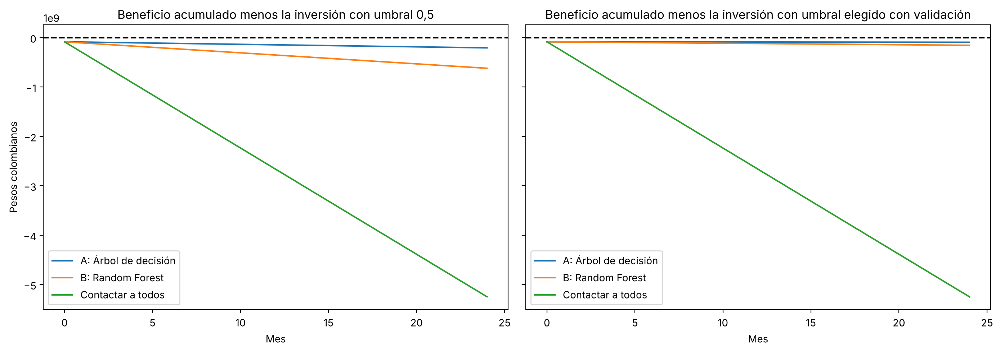

In [78]:
meses= np.arange(0,  25)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax,  (titulo, predicciones) in zip(axes,  [("umbral 0,5", preds_test), ("umbral elegido con validación", preds_test_umbral )]):
    for nombre, y_p in predicciones.items():
        beneficio = impacto(y_test_arr, y_p, V,c,tasa_abandono,r, n_clientes, inversion)["beneficio mensual"]
        ax.plot(meses, beneficio * meses - inversion,  label=nombre)
    ax.axhline(0,  color="k", linestyle="--")
    ax.set_xlabel("Mes")
    ax.set_title("Beneficio acumulado menos la inversión con " + titulo)
    ax.legend()
axes[0].set_ylabel( "Pesos colombianos")
plt.tight_layout()
plt.show()

### 5.5 Recall mínimo para recuperar la inversión en 3 meses

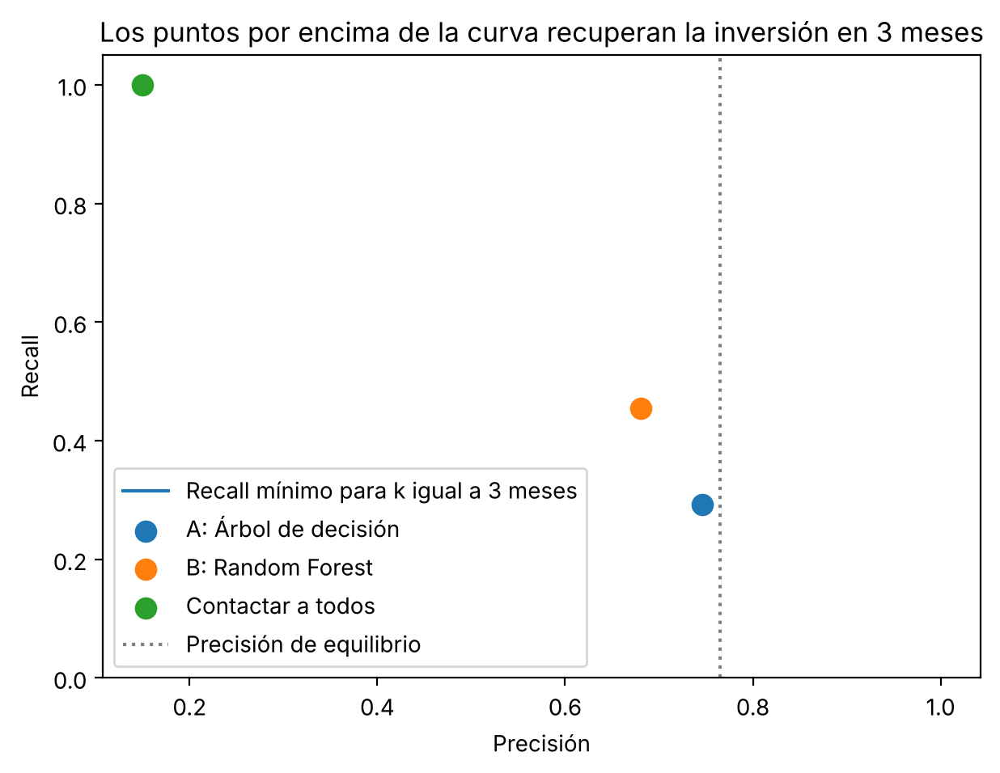

A: Árbol de decisión . Su precisión no supera la de equilibrio: 0.746 contra 0.765
B: Random Forest . Su precisión no supera la de equilibrio: 0.68 contra 0.765


In [79]:
k = 3
P_e =c / ( r * V )
precisiones =np.linspace(P_e + 0.005, 1,200)
recall_min= inversion / (k * M* (r * V - c / precisiones))

plt.figure(figsize=( 7,5))

plt.plot(precisiones, recall_min, label="Recall mínimo para k igual a 3 meses")
for nombre, y_p in preds_test_umbral.items():
    res = impacto(y_test_arr, y_p, V,c, tasa_abandono, r, n_clientes, inversion)
    if not np.isnan(res["precisión ajustada" ]):
        plt.scatter(res["precisión ajustada"],res["recall"], s=80, label=nombre)
plt.axvline(P_e,color="gray", linestyle=":", label="Precisión de equilibrio")
plt.ylim(0, 1.05)
plt.xlabel("Precisión")
plt.ylabel("Recall")
plt.title( "Los puntos por encima de la curva recuperan la inversión en 3 meses")
plt.legend()
plt.show()

for nombre in [nombre_A, nombre_B]:
    res =impacto(y_test_arr, preds_test_umbral[nombre], V,  c, tasa_abandono, r, n_clientes,  inversion)
    if res["precisión ajustada"] > P_e:
        print(nombre, ". Recall necesario con su precisión:", round(inversion/ (k * M * (r * V - c / res["precisión ajustada"])), 3),
              "y recall que tiene:",  round(res["recall"], 3))
    else:
        print(nombre,  ". Su precisión no supera la de equilibrio:",round(res["precisión ajustada" ], 3), "contra", round(P_e, 3))

### 5.6 Sensibilidad al costo por contacto, a la tasa de éxito y a la inversión

In [80]:
# beneficio mensual del mejor modelo según valiación con su umbral para varios costos y tasas de éxito
nombre_mejor = max(umbral_elegido,key=lambda n: tabla_umbral[(tabla_umbral["modelo"] == n) & (tabla_umbral["umbral"] == umbral_elegido[n])]["beneficio mensual en validación" ].iloc[0])
costos = sorted(set([5_000, 20_000, 50_000,100_000, 200_000]+ [ round(oferta + costo_canal) for oferta in costo_oferta.values()]))

tasas_exito = [0.2, 0.3,  0.4, 0.5]

filas= []
for costo in costos:
    fila={"costo por contacto": costo}
    for tasa_exito in tasas_exito:
        fila["r = " + str(tasa_exito)] = impacto(y_test_arr, preds_test_umbral[nombre_mejor], V, costo,tasa_abandono,
                                                 tasa_exito, n_clientes, inversion)["beneficio mensual"]
    filas.append( fila)
print("Modelo:", nombre_mejor, "con umbral", umbral_elegido[nombre_mejor])
pd.DataFrame(filas).set_index("costo por contacto")

Modelo: A: Árbol de decisión con umbral 0.7


,r = 0.2,r = 0.3,r = 0.4,r = 0.5
costo por contacto,,,,
5000,"9,743,433.084","14,860,140.701","19,976,848.317","25,093,555.934"
20000,"8,273,486.635","13,390,194.252","18,506,901.868","23,623,609.485"
50000,"5,333,593.738","10,450,301.354","15,567,008.971","20,683,716.588"
55491,"4,795,495.341","9,912,202.958","15,028,910.574","20,145,618.191"
100000,"433,772.242","5,550,479.858","10,667,187.475","15,783,895.092"
160581,"-5,502,949.479","-386,241.862","4,730,465.754","9,847,173.371"
200000,"-9,365,870.750","-4,249,163.133","867,544.483","5,984,252.100"
265671,"-15,801,394.299","-10,684,686.682","-5,567,979.066","-451,271.449"


In [81]:
#mes de equilibrio en la misma tabla
filas = []
for costo in costos:
    fila= {"costo por contacto": costo}
    for tasa_exito in tasas_exito:
        fila["r = " + str(tasa_exito)]= impacto(y_test_arr,preds_test_umbral[nombre_mejor], V, costo, tasa_abandono,
                                                 tasa_exito, n_clientes,inversion)["mes de equilibrio"]
    filas.append(fila)
pd.DataFrame(filas).set_index("costo por contacto")

,r = 0.2,r = 0.3,r = 0.4,r = 0.5
costo por contacto,,,,
5000,8.484,5.563,4.138,3.294
20000,9.992,6.174,4.467,3.499
50000,15.499,7.910,5.310,3.997
55491,17.238,8.340,5.500,4.103
100000,190.572,14.893,7.749,5.237
160581,NaN,NaN,17.475,8.395
200000,NaN,NaN,95.286,13.814
265671,NaN,NaN,NaN,NaN


In [82]:
# mes de equilibrio según la inversión con el costo base de contacto
c = costo_contacto["medio"]
filas=[]
for nombre_inv,valor_inv in inversiones.items():
    fila ={ "inversión": nombre_inv, "pesos": round(valor_inv)}
    for tasa_exito in tasas_exito:
        fila["r = " + str(tasa_exito)]= impacto(y_test_arr, preds_test_umbral[nombre_mejor ], V, c, tasa_abandono,
                                                 tasa_exito,n_clientes,  valor_inv)["mes de equilibrio"]
    filas.append(fila)
pd.DataFrame(filas).set_index("inversión")

,pesos,r = 0.2,r = 0.3,r = 0.4,r = 0.5
inversión,,,,,
base,82664812,NaN,NaN,17.475,8.395
2 meses,55109875,NaN,NaN,11.650,5.597
6 meses,165329625,NaN,NaN,34.950,16.790
salarios bajos,76305981,NaN,NaN,16.131,7.749
salarios altos,89023644,NaN,NaN,18.819,9.041


In [83]:
#el mejor umbral cambia con el costo, para cada costo se elige moelo y umbral en validación y se evalúa en prueba
V =valores_V["medio"]
filas = []
for costo in costos:
    mejor = None
    for nombre in [nombre_A, nombre_B]:
        for umbral in umbrales:
            y_p= ( prob_val[nombre] >= umbral).astype(int)
            b_val =impacto(np.asarray(y_val), y_p, V, costo,  tasa_abandono, r, n_clientes,inversion)["beneficio mensual"]
            if mejor is None or b_val > mejor[0]:
                mejor = (b_val, nombre, umbral)
    b_val, nombre, umbral = mejor
    y_p =(prob_test[nombre] >= umbral).astype(int)
    res = impacto(y_test_arr, y_p, V, costo, tasa_abandono, r, n_clientes, inversion)
    filas.append({"costo por contacto": costo, "modelo": nombre, "umbral": umbral,
                  "beneficio en validación": b_val, "beneficio en prueba": res[ "beneficio mensual"],
                  "mes de equilibrio": res["mes de equilibrio"]})
pd.DataFrame(filas).set_index("costo por contacto")

,modelo,umbral,beneficio en validación,beneficio en prueba,mes de equilibrio
costo por contacto,,,,,
5000,B: Random Forest,0.300,"39,275,817.291","41,186,870.615",2.007
20000,B: Random Forest,0.400,"28,906,036.237","30,235,383.046",2.734
50000,B: Random Forest,0.600,"16,973,737.991","17,982,305.624",4.597
55491,B: Random Forest,0.600,"15,622,118.590","16,628,119.356",4.971
100000,B: Random Forest,0.700,"7,455,789.122","7,164,155.681",11.539
160581,A: Árbol de decisión,0.700,"461,620.968","-386,241.862",NaN
200000,A: Árbol de decisión,0.700,"-3,034,845.323","-4,249,163.133",NaN
265671,A: Árbol de decisión,0.700,"-8,859,864.674","-10,684,686.682",NaN


Con los supuestos base ningún modelo recupera la inversión. Con el umbral de 0,7 y V medio, el árbol pierde 0,39 millones al mes y el Random Forest 2,95 millones. Por lo tanto, ninguno tiene punto de equilibrio. El ROI a 12 meses es de menos 1,06 en el árbol y de menos 1,43 en el Random Forest, es decir que en el primer año perderían más que la inversión de 82,7 millones. Contactar a todos pierde mucho dinero en cualquier caso.

Cuando no hay punto de equilibrio, se calcula a partir de qué valor apareceria. Para el árbol, el costo máximo por contacto con el que tendría beneficio es de 156.640 pesos, contra los 160.581 supuestos, y la tasa de éxito mínima es de 0,308, contra 0,30. Para el Random Forest el costo máximo es de 142.900 pesos y la tasa de éxito mínima es de 0,337. Estas cifras muestran que el árbol está muy cerca del punto donde cambia de signo, y por eso cualquier error en c o en r cambia la conclusión.

Para recuperar la inversión en tres meses, ninguno de los dos modelos supera la precisión de equilibrio, 0,746 en el árbol y 0,680 en el Random Forest contra 0,765, y por eso no hay recall que alcance. Ningún modelo se paga en un trimestre con el costo base.

La sensibilidad, muestra que todo depende de c. La primera tabla usa el árbol con elumbral 0,7, que se eligió para el costo base. La segunda tabla elige el modelo y el umbral en validación para cada costo, y por eso es la que mejor describe cada caso. Con r de 0,3, un costo por contacto de 55.491 pesos, que es la oferta baja más el canal, da un beneficio de 16,6 millones al mes con el Random Forest y el umbral 0,6, y la inversión se recupera en 5,0 meses. Con 50.000 pesos, en 4,6 meses, y con 100.000, en 11,5 meses con el Random Forest y el umbral 0,7. Con el costo base de 160.581 pesos el mejor es el árbol con 0,7 y pierde 0,39 millones al mes, y con 200.000 y 265.671 pierde más. El mejor modelo cambia con el costo: cuando la oferta es barata conviene contactar a más clientes, con más recall, y el Random Forest gana al árbol. Cuando es cara conviene contactar solo a los más seguros, y gana el árbol.

La tasa de éxito también pesa. Con el costo base, una tasa de 0,4 da un beneficio de 4,7 millones al mes y un equilibrio en 17,5 meses, y una de 0,5 da 9,8 millones y 8,4 meses. Con la oferta alta, de 265.671 pesos por contacto, pierde dinero incluso con r de 0,5.

La inversión importa menos. Con el costo base y r de 0,4, el equilibrio es de 11,7 meses con 2 meses de equipo, 17,5 con 3 y 35,0 con 6. Con salarios bajos es de 16,1 meses y con altos de 18,8. Con r de 0,3 o menos no se recupera en ningún escenario de inversión con el costo base.

En resumen, con estos supuestos el proyecto se paga si el costo por contacto es de unos 100.000 pesos o menos, en menos de 12 meses con r de 0,3, y se paga con el costo base solo si la tasa de éxito es de 0,4 o más. No se paga con la oferta alta ni con el costo base y r de 0,3. El resultado depende más del costo por contacto y de la tasa de éxito que del modelo o de la inversión

### 5.7 Limitaciones

Las conclusiones de esta sección y del taller tienen varias limitaciones.

El costo de la oferta, la tasa de éxito y la inversión son supustos. Definí la oferta como exonerar la cuota de manejo durante 6 meses y lepuse el costo con las cuotas que reporta la Superintendencia Financiera, pero un banco puede ofrecer otra cosa, como una mejor tasa, con otro costo. Además, c se cobra por cada cliente contactado, y en la práctica el descuento solo lo paga el banco a quien lo acepta, así que c es un tope. El canal supone un agente con salario mínimo, 160 horas al mes y llamadas de 5 minutos. La inversión supone un equipo de 3,5 personas durante 3 meses, decisión mía, con salarios de recién graduados que pueden quedarse cortos para un equipo con experiencia, y no incluye nube, licencias, contingencia ni costos recurrentes. El salario mínimo de 2026 se fijó con un decreto transitorio que depende de un fallo pendiente. Ninguno es una cifra de FinAlpes ni de un banco colombiano. Como el resultado está cerca del punto donde cambia de signo, esto es lo que más pesa. Es por esto, que la conclusión se presenta como condicional al costo por contacto y a la tasa de éxito.

El dataset es de clientes de bancos europeos, en Francia, Alemania y España, y no de Colombia. Los patrones de abandono, como el efecto de la edad o de tener tres productos, pueden ser distintos en otro mercado. Por lo tanto, el modelo no se debe usar tal cual sin revisarlo con datos delbanco que lo va a usar. La tasa de abandono del dataset es de 20% y la del escenario es de 15%, y por eso se ponderó con la distribución previa, pero la precisión real dependerá de cuál sea la tasa del banco.

Los números de tres o más productos salen de 326 clientes, y los valores extremos de variales se trataron con una regla, el clipping en los percentiles 1 y 99, que cambia a clientes que quizás son reales. Las derivadas no mejoraron el Random Forest, y no se evaluó si mejoran a la regresión logística. El F1 de los mejores modelos es de 0,6. Por lo tanto, predecir el abandono con estos datos es difícil: unaparte del abandono no se explica con las variables disponibles.

El umbral se eligió entre cinco valores y el mejor fue el más alto. Por lo tanto, puede haber uno mejor. El beneficio del árbol fue de 0,46 millones al mes en validación y de menos 0,39 en prueba, lo que muestra la variación entre conjuntos. Las explicaciones de LIME de los casos individuales tienen un ajuste local bajo en dos de los tres clientes. El análisis es estático: supone que el valor de un cliente retenido, la tasa de éxito y el costo se mantienen en el tiempo, y no considera costos de monitoreo, reentrenamiento ni el efecto de contactar a clientes que no se iban a ir. Todas las relaciones descritas son asociaciones, no causas.